# **PART 0: TECHNICAL INITIATION**

## **0.1. Import Libraries**

In [1]:
# silence warnings
import warnings
warnings.filterwarnings('ignore')

# basic libraries
import numpy as np
import pandas as pd

# basic python utilities
import math
import textwrap

# plotting and visualization
import matplotlib.pyplot as plt
import seaborn as sns

# models
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, validation_curve, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from scipy.stats import shapiro, chi2_contingency
import re
from xgboost import XGBClassifier

# **PART 1: BUSINESS UNDERSTANDING**

## **1.1 Business Context**

Nova Academy is a B2B/B2C professional training company that delivers technical courses (e.g. cloud, cybersecurity, physical equipment setups) to corporate groups. Each course requires the company to commit real resources **in advance of the course start date**: reserving cloud environments, ordering catering, preparing physical kits, and staffing instructors and lab configurations.

Management has identified that a large share of confirmed registrations are being **cancelled before the course start date** (`Dropped_Course = 1`). This is costly on two fronts:

- **Wasted spend**: resources (catering, kits, cloud environments, lab setup) are provisioned for groups that never show up.
- **Opportunity cost**: seats held for a cancelling group block other groups from being registered for the same slot, and the company forfeits the revenue that alternate group would have brought.

The company has historical CRM data on past registrations, including whether each one was ultimately cancelled, and wants to use this data to anticipate cancellations *before* they happen - while there's still time to act.

## **1.2 Business Objective**

Build a model that, given the information known about a registration at (or shortly after) booking time, estimates the **probability that group will cancel its course before the start date.**

This prediction would let the operations team:
- Prioritize follow-up/retention outreach toward high-risk groups.
- Delay or stage resource-intensive commitments (catering orders, physical kit prep) for high-risk bookings until closer to the course date.
- Make more conservative overbooking/waitlist decisions for slots dominated by high-risk registrations.

## **1.3 Business Success Criteria**

A model is considered business-useful if it can reliably rank registrations by cancellation risk well enough that the operations team can act on the top-risk segment with meaningfully better precision than treating all bookings the same way - translating into materially reduced wasted spend on cancelled bookings, without over-investing in retention effort on registrations that were never going to cancel.

## **1.4 Data Mining Goal & Target Variable**

The business objective is framed as a **binary classification problem**: predict `Dropped_Course` (1 = the group cancelled before the course started, 0 = the group attended as scheduled) using the features available in the CRM data at/near booking time (e.g. group composition, course logistics, registration timing, prior client history, payment terms, and registration channel - see 2.2 for the full feature list).

Because the operational use case is about **ranking and prioritizing** registrations by risk rather than issuing a hard yes/no verdict, the model should output a **calibrated probability of dropout**, not just a binary label - this is also the format required for the final submission.

## **1.5 Data Mining Success Criteria**

Model performance is measured using **AUC (Area Under the ROC Curve)** on a held-out test set, since AUC evaluates the model's ability to correctly *rank* registrations by risk regardless of the exact probability threshold used - which matches how the business intends to use the output (prioritization, not automatic action). The project defines a minimum bar of **AUC ≥ 0.70** for the model to be considered acceptable; scores above this threshold are additionally ranked competitively.

# **PART 2: DATA DISCOVERY**

## **2.1 Data Load**

In [2]:
# import dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Load the CSV files into a DataFrame
train = pd.read_csv('/content/drive/MyDrive/לימודי/מדעים דיגיטליים וביולוגיה/מדעים דיגיטליים/ML/ML Project - Nova Academy/Train_Data.csv')
test = pd.read_csv('/content/drive/MyDrive/לימודי/מדעים דיגיטליים וביולוגיה/מדעים דיגיטליים/ML/ML Project - Nova Academy/Test_Data_No_Target.csv')

train_original = train.copy()
test_original = test.copy()

## **2.2 Variables Meaning**



> '**Client_ID**' = מזהה הזמנה ייחודי | *categorical*

---



> '**Professionals_Count**' = מספר אנשי המקצוע המנוסים שרשומים בהזמנה | *numeric*

---


> '**Students_Count**' = מספר הסטודנטים שרשומים בהזמנה | *numeric*

---


> '**Observers_Count**' = מספר משקיפים שלא מבצעים תרגילים בקורס שרשומים להזמנה | *numeric*

---


> '**Course_Start_Date**' = התאריך המיועד לפתיחת הקורס | *date*

---


> '**Practical_Hours**' = מספר שעות התרגול המעשי המתוכננות בקורס | *numeric*

---


> '**Theory_Hours**' = מספר שעות הלמידה העיונית המתוכננות בקורס | *numeric*

---


> '**Registration_Days_Before**' = מספר הימים שעברו ממועד ההרשמה ועד ליום פתיחת הקורס | *numeric*

---


> '**Origin_Country**' = קוד המדינה ממנה מגיעה הקבוצה שביצעה את ההזמנה | *categorical*

---


> '**Catering_Package**' = סוג חבילת ההסעדה שהוזמנה מראש עבור הקבוצה | *categorical*

---


> '**Welcome_Gift_Type**' = סוג מתנת הפתיחה שחולקה לקבוצה | *categorical*

---


> '**Requested_Lab_Config**' = סביבת המעבדה שהקבוצה ביקשה לצורך הקורס | *categorical*

---


> '**Assigned_Lab_Config**' = סביבת המבדה שהוקצתה בפועל ביום הקורס עצמו | *categorical*

---


> '**Prev_Course_Dropouts**' = מספר הפעמים שהקבוצה ביטלה את הקורסים בעבר | *numeric*

---


> '**Prev_Course_Attended**' = מספר הפעמים שהקבוצה השתתפה בקורסים תחת החברה | *numeric*

---


> '**Pre_Course_Supports_Tickets**' = מספר הבקשות שהקבוצה ביקשה טרם תחילת הקורס | *numeric*

---


> '**Physical_Course_Kits**' = מספר ערכות הציוד הפיזיות שנדרש להכין מראש עבור הקבוצה | *numeric*

---


> '**Waiting_List_Days**' = מספר הימים שהקבוצה המתינה ברשימת ההמתנה עד אישור פרטי ההרשמה במערכת | *numeric*

---


> '**Registration_Changes**' = מספר הפעמים שהקבוצה שינתה את פרטי ההזמנה שלה במערכת | *numeric*

---


> '**Enrollment_Type**' = אופן הרישום מול החברה | *categorical*

---


> '**Lanyard_Color**' = צבע שרוך התג שתענוד הקבוצה | *categorical*

---


> '**Client_Category**' = הסגמנט העסקי של הקבוצה | *categorical*

---


> '**Submission_Source**' = ערוץ הרישום דרכו הגיעה ההזמנה | *categorical*

---


> '**Returning_Client**' = אינדיקטור הקובע האם מדובר בלקוח חוזר (1) או חדש (0) | *binary*

---


> '**Agent_ID**' = מזהה ייחודי של סוכן או נציג המכירות שסגר את ההרשמה | *categorical*

---


> '**Company_ID**' = מזהה החברה שדרכו נרשמה הקבוצה | *categorical*

---


> '**Payment_Terms**' = תנאי התשלום שהוגדרו עבור ההזמנה | *categorical*


---


> '**Daily_Tuition_Cost**' = עלות ההדרכה היומית עבור אותה הזמנה | *numeric*

---


> '**Dropped_Course**' =  | *Label*

---


## **2.3 Train Set Structure Analysis**

### **2.3.1 Train - Initial Display**

In [4]:
train

,Client_ID,Professionals_Count,Students_Count,Observers_Count,Course_Start_Date,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,...,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Agent_ID,Company_ID,Payment_Terms,Daily_Tuition_Cost,Dropped_Course
0,13766,2,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
1,78660,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
2,51396,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,...,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
3,34000,2,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,...,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
4,69025,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,...,General Admission,Orange,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63459,43806,2,0.0,0,2017-04-26,10000,3,156.0,PRT,Standard (Coffee Only),...,General Admission,Blue,Big Tech & Multinationals,B2B Platforms & Resellers,0,320.0,NaN,Prepaid (Non-Refundable),100.0,1
63460,13196,2,0.0,0,2017-04-26,0,3,156.0,PRT,Standard (Coffee Only),...,General Admission,Black,Big Tech & Multinationals,B2B Platforms & Resellers,0,NaN,NaN,Prepaid (Non-Refundable),100.0,1
63461,77685,2,0.0,0,2017-04-26,0,3,NaN,!PRT,Standard (Coffee Only),...,General Admission,Blue,Big Tech & Multinationals,B2B Platforms & Resellers,0,315.0,NaN,Prepaid (Non-Refundable),140.0,1
63462,54083,2,1.0,0,2017-04-26,1,4,110.0,NOR,No Food Plan,...,General Admission,Red,SaaS & Software Houses,B2B Platforms & Resellers,0,184.0,NaN,Pay Upon Start,100.8,1


### **2.3.2 Train - Dataset size**

In [5]:
# print the size of the data
print(f"The size of the train data set : {train.shape[0]} rows and {train.shape[1]} columns")

The size of the train data set : 63464 rows and 29 columns


### **2.3.3 Train - Basic Cols Information**

In [6]:
# create basic cols info function
def detailed_structure_analysis(df, name="Data", categorical_threshold=15):
    # create a table of basic data for each col
    summary = pd.DataFrame({
        'Column': df.columns,
        'Dtype': df.dtypes,
        'Missing Values': df.isnull().sum(),
        'Missing %': df.isnull().mean() * 100,
        'Unique Values': df.nunique()
    }).reset_index(drop=True)

    # automatic classify column type
    def classify_col(col, dtype, nunique):
        if pd.api.types.is_bool_dtype(dtype):
            return 'Boolean'
        elif pd.api.types.is_numeric_dtype(dtype):
            return 'Categorical' if nunique <= categorical_threshold else 'Numerical'
        elif pd.api.types.is_object_dtype(dtype) or pd.api.types.is_categorical_dtype(dtype):
            return 'Categorical'
        else:
            return 'Other'

    # clssify each row
    summary['Automatic Feature Type'] = [
        classify_col(col, row['Dtype'], row['Unique Values'])
        for col, row in zip(summary['Column'], summary.to_dict('records'))
    ]

    # sort by % missing values
    summary = summary.sort_values(by='Missing %', ascending=False).reset_index(drop=True)

    print(f"======== {name.upper()} STRUCTURE ANALYSIS ========")
    display(summary)

detailed_structure_analysis(train, name="Train")

======== TRAIN STRUCTURE ANALYSIS ========


,Column,Dtype,Missing Values,Missing %,Unique Values,Automatic Feature Type
0,Company_ID,float64,60344,95.083827,184,Numerical
1,Agent_ID,float64,11173,17.605257,203,Numerical
2,Registration_Days_Before,float64,2666,4.200807,423,Numerical
3,Requested_Lab_Config,object,1736,2.735409,8,Categorical
4,Physical_Course_Kits,float64,1040,1.638724,4,Categorical
5,Enrollment_Type,object,719,1.132926,298,Categorical
6,Submission_Source,object,605,0.953296,328,Categorical
7,Payment_Terms,object,587,0.924934,236,Categorical
8,Origin_Country,object,557,0.877663,721,Categorical
9,Catering_Package,object,407,0.641308,321,Categorical


## **2.4 Train Set Statistical Summary**

### **2.4.1 Train Numeric Cols - Statistics**

In [7]:
# calculate count, mean, std, min-max,
def statistical_summary(df, name="Data"):
    print(f"======== {name.upper()} STATISTICAL SUMMARY ========")
    print("\n--- Numerical Features ---")
    display(df.describe().T)

statistical_summary(train, name="Train")

======== TRAIN STATISTICAL SUMMARY ========

--- Numerical Features ---


,count,mean,std,min,25%,50%,75%,max
Client_ID,63464.0,39761.752616,22878.980699,1.0,19959.75,39819.5,59570.25,79330.0
Professionals_Count,63464.0,1.835214,0.508607,0.0,2.00,2.0,2.00,4.0
Students_Count,63460.0,8.751718,294.238584,0.0,0.00,0.0,0.00,9999.0
Observers_Count,63464.0,0.005326,0.089662,0.0,0.00,0.0,0.00,10.0
Practical_Hours,63464.0,6.609054,215.502929,-5.0,0.00,1.0,1.00,10000.0
Theory_Hours,63464.0,2.164392,1.469854,0.0,1.00,2.0,3.00,41.0
Registration_Days_Before,60798.0,102.894470,109.178824,0.0,19.00,65.0,150.00,629.0
Prev_Course_Dropouts,63464.0,0.095991,0.448526,0.0,0.00,0.0,0.00,21.0
Prev_Course_Attended,63464.0,0.122967,1.535201,0.0,0.00,0.0,0.00,61.0
Pre_Course_Supports_Tickets,63464.0,0.513330,0.763563,0.0,0.00,0.0,1.00,5.0


### **2.4.2 Train Numeric Cols - Initial Visualizations**

======= DATA – NUMERIC DISTRIBUTIONS =======


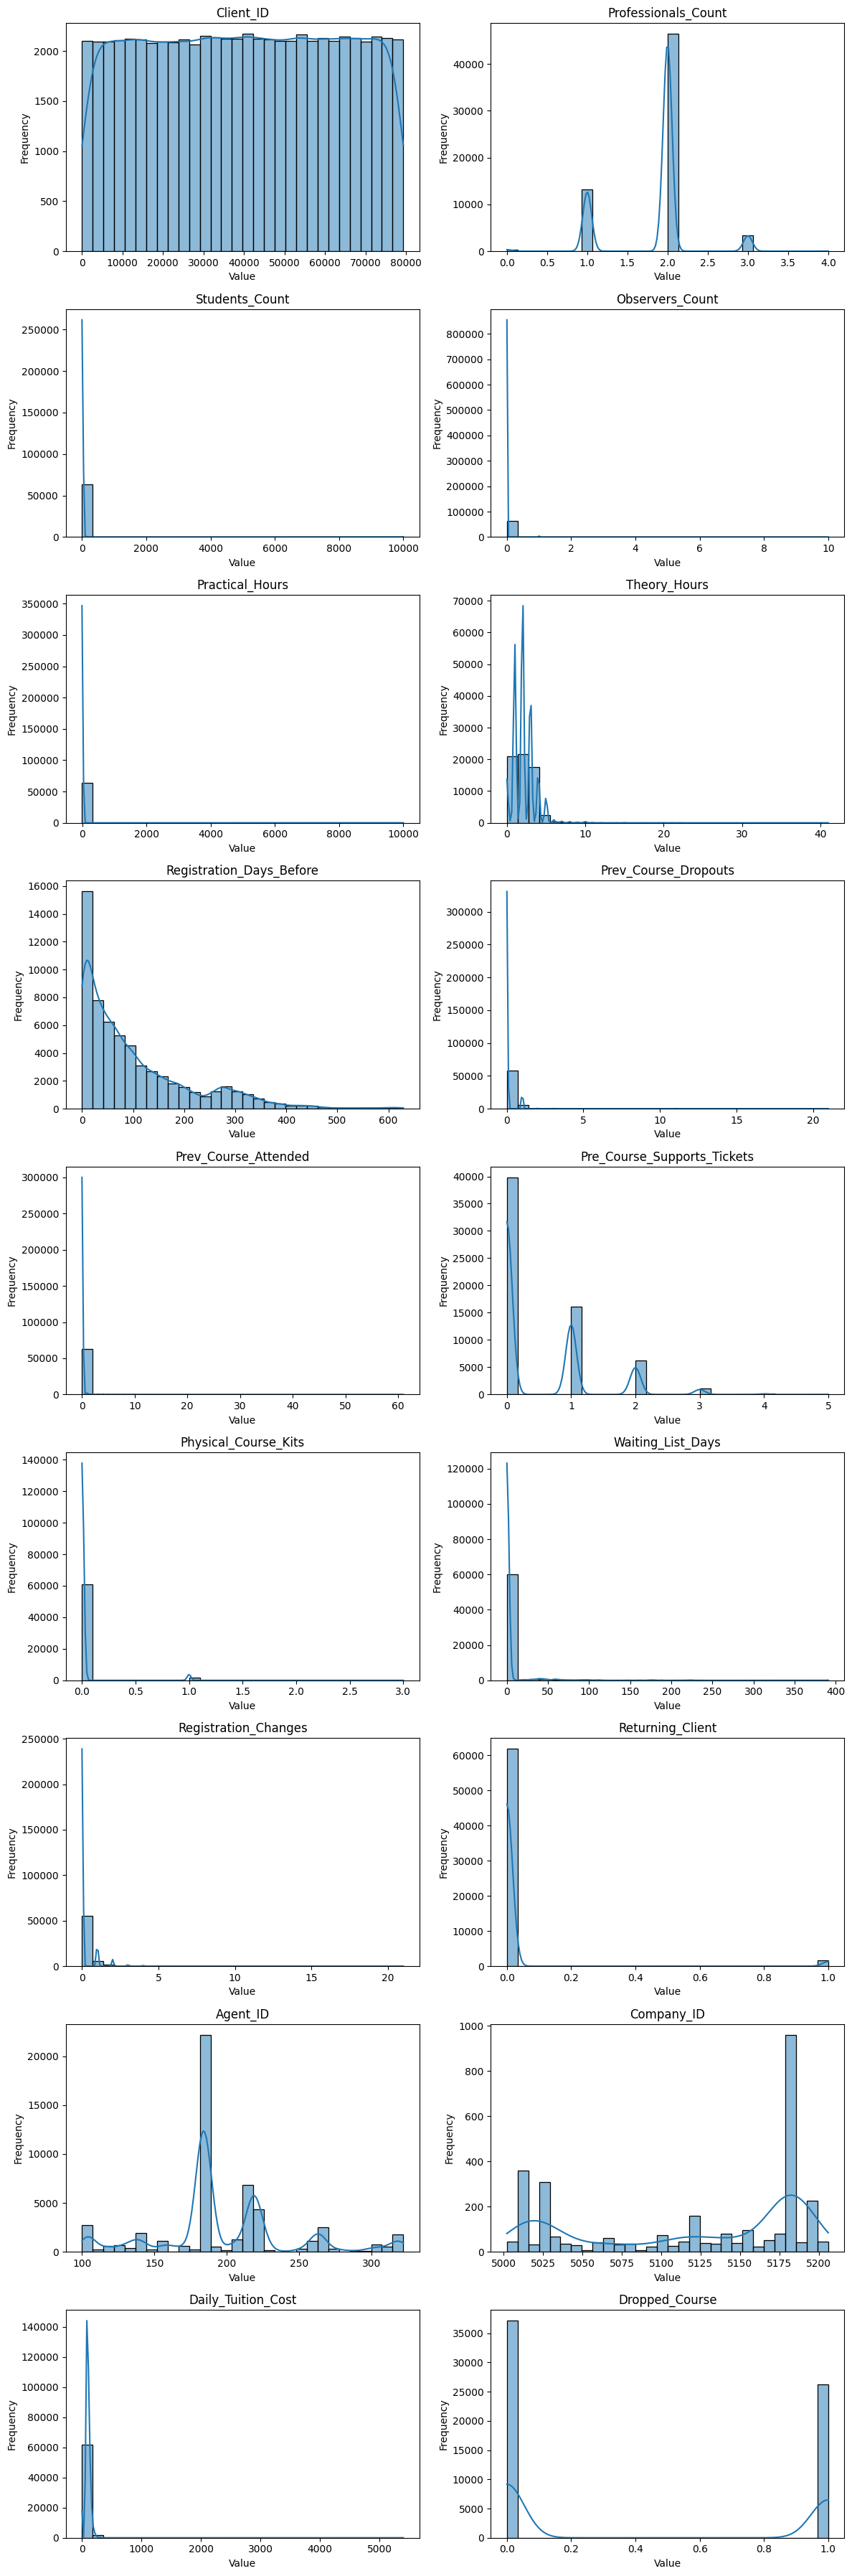

In [8]:
# create distribution histogram for numerical features
def plot_numeric_distributions(df, cols=None, bins=30, name="Data"):
    numeric_cols = cols if cols is not None else df.select_dtypes(include=['number']).columns
    num_plots = len(numeric_cols)

    print(f"======= {name.upper()} – NUMERIC DISTRIBUTIONS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))
    axes = axes.flatten()

    # create histograms
    for i, col in enumerate(numeric_cols):
        sns.histplot(df[col].dropna(), bins=bins, ax=axes[i], kde=True)
        axes[i].set_title(col)
        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_numeric_distributions(train)

✏️ explanation will follow the manual features classification (part 3).

### **2.4.3 Train Categoric Cols - Statistics**

======= TRAIN CATEGORICAL COUNTS =======


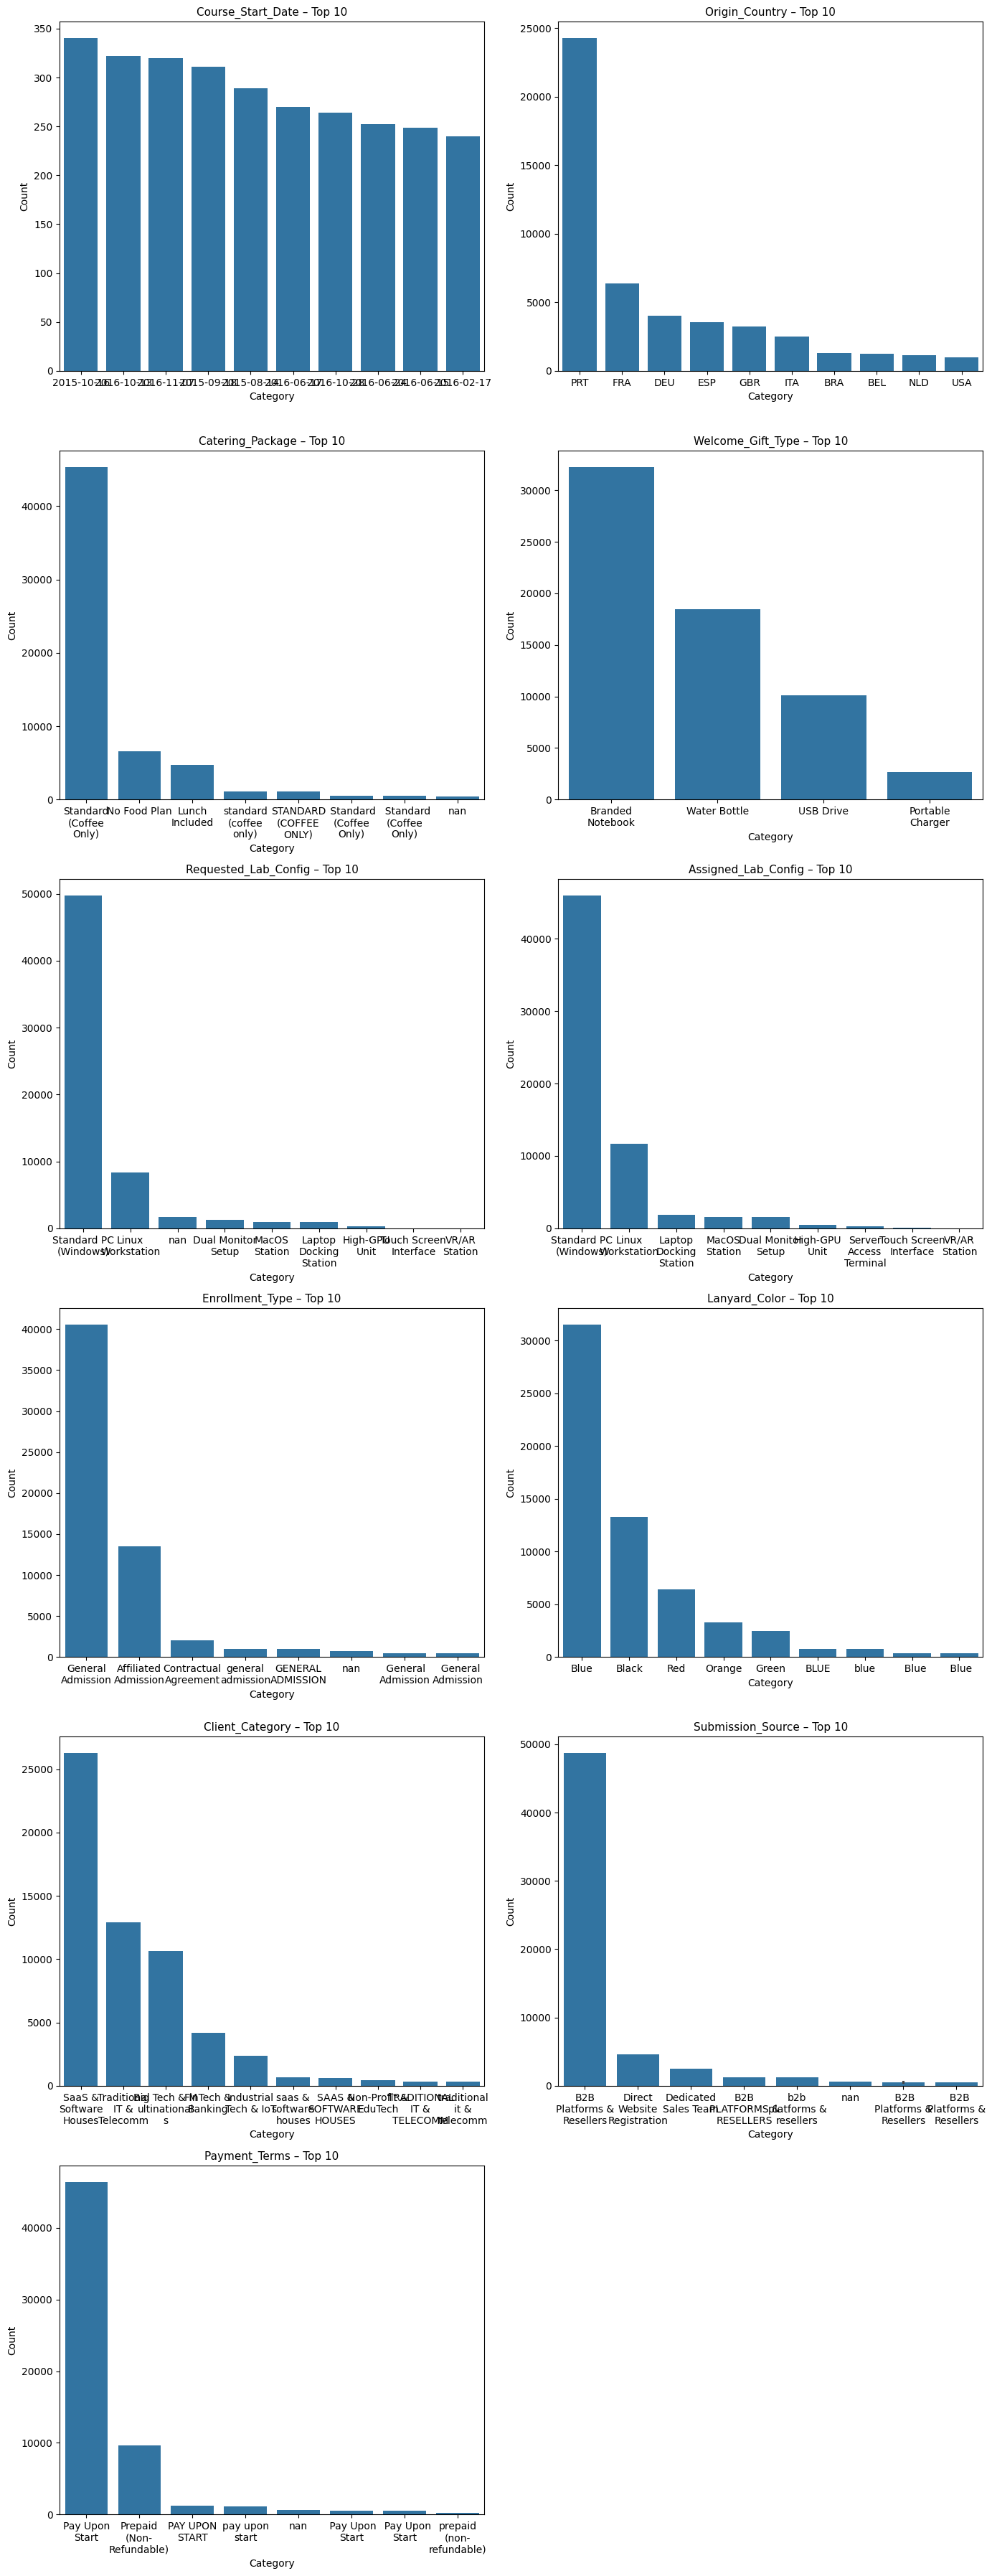

In [9]:
# create distribution histogram for categorical features
def plot_categorical_counts(df, max_categories=10, name="Data"):
    cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns
    num_plots = len(cat_cols)

    print(f"======= {name.upper()} CATEGORICAL COUNTS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 6 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):
        counts = df[col].value_counts(dropna=False).head(max_categories)
        labels = [textwrap.fill(str(label), width=12) for label in counts.index]
        sns.barplot(x=labels, y=counts.values, ax=axes[i])
        axes[i].set_title(f"{col} – Top {max_categories}", fontsize=11)
        axes[i].set_ylabel("Count")
        axes[i].set_xlabel("Category")
        axes[i].tick_params(axis='x', rotation=0)

    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_categorical_counts(train, name="Train")

✏️ explanation will follow the manual features classification (part 3).

## **2.5 Test Set Structure Analysis**

### **2.5.1 Test - Initial Display**

In [10]:
test

,Client_ID,Professionals_Count,Students_Count,Observers_Count,Course_Start_Date,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,...,Registration_Changes,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Agent_ID,Company_ID,Payment_Terms,Daily_Tuition_Cost
0,62246,2,1.0,0,2017-04-26,0,3,48.0,IND,Standard (Coffee Only),...,0,Affiliated Admission,Blue,SaaS & Software Houses,B2B Platforms & Resellers,0,184.0,NaN,Pay Upon Start,144.00
1,43031,2,0.0,0,2017-04-26,0,3,156.0,PRT,STANDARD (COFFEE ONLY),...,0,General Admission,Orange,big tech & multinationals,B2B Platforms & Resellers,0,320.0,NaN,Prepaid (Non-Refundable),100.00
2,26571,2,0.0,0,2017-04-26,0,1,59.0,CHE,Standard (Coffee Only),...,0,General Admission,Blue,FinTech & Banking,Direct Website Registration,0,264.0,NaN,Pay Upon Start,130.50
3,77694,2,0.0,0,2017-04-26,0,3,156.0,PRT,Standard (Coffee Only*),...,0,General Admission,Blue,Big Tech & Multinationals,B2B Platforms & Resellers,0,320.0,NaN,Prepaid (Non-Refundable),100.00
4,22185,1,0.0,0,2017-04-26,0,1,6.0,PRT,Standard (Coffee Only),...,0,Affiliated Admission,Red?,Traditional IT & Telecomm,B2B Platforms & Resellers,0,273.0,NaN,Pay Upon Start,65.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15861,6266,2,0.0,0,2017-08-31,0,3,1.0,gbr,Standard (Coffee Only),...,0,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,224.0,NaN,Pay Upon Start,109.50
15862,54887,2,0.0,0,2017-08-31,0,3,30.0,DEU,Standard (Coffee Only),...,0,General Admission,Orange,FinTech & Banking,Direct Website Registration,0,264.0,NaN,Pay Upon Start,151.67
15863,76821,2,0.0,0,2017-08-31,1,3,112.0,DEU,Standard (Coffee Only),...,0,General Admission,Blue,SaaS & Software Houses,B2B Platforms & Resellers,0,184.0,NaN,Pa#y Upon Start,145.00
15864,861,2,0.0,0,2017-08-31,0,1,65.0,CN,NO FOOD PLAN,...,0,General Admission,Blue,SaaS & Software Houses,B2B Platforms & Resellers,0,184.0,NaN,Pay Upon Start,140.00


### **2.5.2 Test - Dataset size**

In [11]:
# show dataset size
print(f"The size of the test data set : {test.shape[0]} rows and {test.shape[1]} columns")

The size of the test data set : 15866 rows and 28 columns


### **2.5.3 Test - Basic Cols Information**

In [12]:
# show test basic cols information
detailed_structure_analysis(test, name="Test")

======== TEST STRUCTURE ANALYSIS ========


,Column,Dtype,Missing Values,Missing %,Unique Values,Automatic Feature Type
0,Company_ID,float64,15297,96.413715,55,Numerical
1,Agent_ID,float64,2794,17.609984,92,Numerical
2,Registration_Days_Before,float64,642,4.046389,399,Numerical
3,Requested_Lab_Config,object,477,3.006429,8,Categorical
4,Physical_Course_Kits,float64,227,1.430732,4,Categorical
5,Enrollment_Type,object,177,1.115593,145,Categorical
6,Origin_Country,object,160,1.008446,442,Categorical
7,Submission_Source,object,149,0.939115,164,Categorical
8,Payment_Terms,object,144,0.907601,125,Categorical
9,Catering_Package,object,111,0.699609,172,Categorical


## **2.6 Test Set Statistical Summary**

### **2.6.1 Test Numeric Cols - Statistics**

In [13]:
# calculate count, mean, std, min-max,
statistical_summary(test, name="Test")

======== TEST STATISTICAL SUMMARY ========

--- Numerical Features ---


,count,mean,std,min,25%,50%,75%,max
Client_ID,15866.0,39280.489537,22984.277379,3.0,19379.00,39026.5,59185.75,79326.0
Professionals_Count,15866.0,1.914030,0.507165,0.0,2.00,2.0,2.00,4.0
Students_Count,15866.0,7.676163,274.889662,0.0,0.00,0.0,0.00,9999.0
Observers_Count,15866.0,0.003404,0.058242,0.0,0.00,0.0,0.00,1.0
Practical_Hours,15866.0,7.772217,244.583919,-5.0,0.00,1.0,2.00,10000.0
Theory_Hours,15866.0,2.257217,1.398962,0.0,1.00,2.0,3.00,12.0
Registration_Days_Before,15224.0,137.095113,113.044344,0.0,40.00,123.0,186.00,521.0
Prev_Course_Dropouts,15866.0,0.014749,0.230450,0.0,0.00,0.0,0.00,6.0
Prev_Course_Attended,15866.0,0.169986,2.215701,0.0,0.00,0.0,0.00,72.0
Pre_Course_Supports_Tickets,15866.0,0.681268,0.832721,0.0,0.00,0.0,1.00,5.0


### **2.6.2 Test Categoric Cols - Statistics**

======= TEST CATEGORICAL COUNTS =======


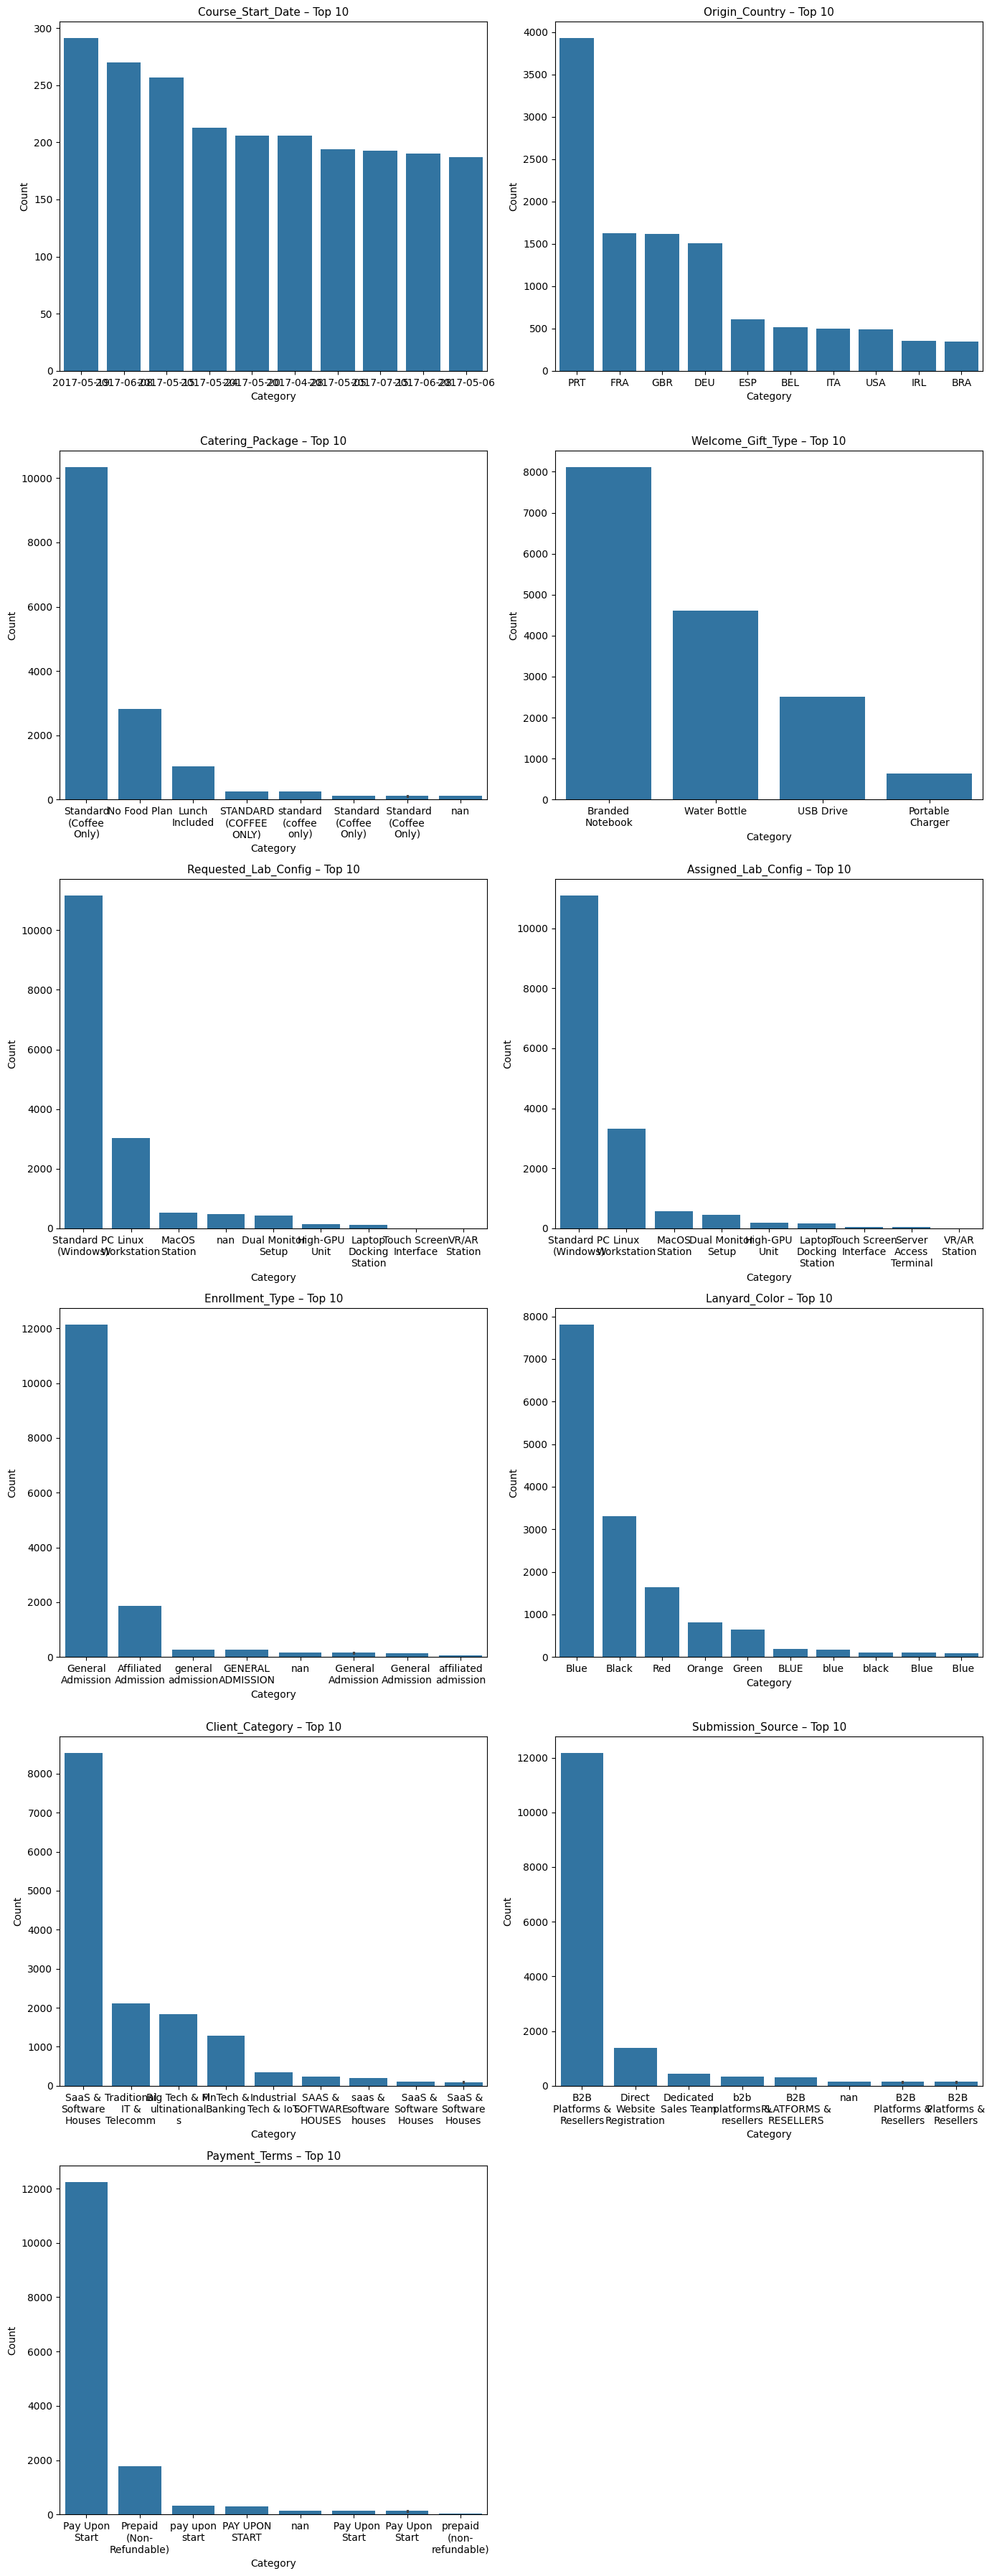

In [14]:
# create distribution histogram for categorical features
plot_categorical_counts(test, name="Test")

✏️ explanation will follow the manual features classification (part 3).

# **PART 3: EXPLORATORY DATA ANALYSIS (EDA)**

## **3.1 Fixed Features Classification**

### **3.1.1 Automatic Categorical Classification**

In [15]:
# Identify categorical columns in a dataframe based on data type and cardinality
def get_categorical_columns(df, threshold=15):
    cat_cols = []
    # Iterate over all columns in the dataframe
    for col in df.columns:
        # If the column is explicitly categorical (object, bool, or category), add to list
        if df[col].dtype in ['object', 'bool', 'category']:
            cat_cols.append(col)
        # If the column is numeric but has a limited number of unique values, treat it as categorical
        elif pd.api.types.is_numeric_dtype(df[col]):
            if df[col].nunique() <= threshold:
                cat_cols.append(col)
    return cat_cols

cat_cols = get_categorical_columns(train)

print("Categorical columns:")
for col in cat_cols:
    print("-", col)

Categorical columns:
- Professionals_Count
- Students_Count
- Observers_Count
- Course_Start_Date
- Origin_Country
- Catering_Package
- Welcome_Gift_Type
- Requested_Lab_Config
- Assigned_Lab_Config
- Prev_Course_Dropouts
- Pre_Course_Supports_Tickets
- Physical_Course_Kits
- Enrollment_Type
- Lanyard_Color
- Client_Category
- Submission_Source
- Returning_Client
- Payment_Terms
- Dropped_Course


### **3.1.2 Automatic Numeric Classification**

In [16]:
5# Identify numerical columns by excluding known categorical columns
def get_numerical_columns(df, cat_cols):
    return [col for col in df.columns if col not in cat_cols]

num_cols = get_numerical_columns(train, cat_cols)

print("Numerical columns:")
for col in num_cols:
    print("-", col)

Numerical columns:
- Client_ID
- Practical_Hours
- Theory_Hours
- Registration_Days_Before
- Prev_Course_Attended
- Waiting_List_Days
- Registration_Changes
- Agent_ID
- Company_ID
- Daily_Tuition_Cost


### **3.1.3 Manual Features Classification**

✏️ To ensure that the automatic column classification is accurate, I manually reviewed each column. I examined the number of unique values, the value range, and the general behavior of the values — for example, whether the numbers are always rounded, include negative values, or show large jumps. I also reviewed each feature's distribution. Based on these observations, I will now manually correct columns that were classified as categorical but are more appropriately treated as numerical.

In [17]:
# manual features classification fixation: numeric --> categorical
fix_to_categorical = ['Client_ID', 'Agent_ID', 'Company_ID']
for col in fix_to_categorical:
    if col in train.columns:
        train[col] = train[col].astype('category')
        print(f"{col} converted to category.")
    else:
        print(f"Column {col} not found in dataframe.")

# add new classification to categorical features lists
for col in fix_to_categorical:
    if col in num_cols:
        num_cols.remove(col)
    if col not in cat_cols:
        cat_cols.append(col)

# manual features classification fixation: categorical --> numeric
fix_to_numeric = ['Professionals_Count', 'Students_Count', 'Observers_Count', 'Prev_Course_Dropouts', 'Pre_Course_Supports_Tickets', 'Physical_Course_Kits']
for col in fix_to_numeric:
    if col in train.columns:
        train[col] = pd.to_numeric(train[col], errors='coerce')
        print(f"{col} converted to numeric.")
    else:
        print(f"Column {col} not found in dataframe.")

# add new classification to numeric features list
for col in fix_to_numeric:
    if col in cat_cols:
        cat_cols.remove(col)
    if col not in num_cols:
        num_cols.append(col)

label = 'Dropped_Course'
if label in cat_cols:
    cat_cols.remove(label)

Client_ID converted to category.
Agent_ID converted to category.
Company_ID converted to category.
Professionals_Count converted to numeric.
Students_Count converted to numeric.
Observers_Count converted to numeric.
Prev_Course_Dropouts converted to numeric.
Pre_Course_Supports_Tickets converted to numeric.
Physical_Course_Kits converted to numeric.


### **3.1.4 Verify Global Definition of cat_cols & num_cols**

In [18]:
# validate cols names
cat_cols

['Course_Start_Date',
 'Origin_Country',
 'Catering_Package',
 'Welcome_Gift_Type',
 'Requested_Lab_Config',
 'Assigned_Lab_Config',
 'Enrollment_Type',
 'Lanyard_Color',
 'Client_Category',
 'Submission_Source',
 'Returning_Client',
 'Payment_Terms',
 'Client_ID',
 'Agent_ID',
 'Company_ID']

In [19]:
# remove ID from num_cols and validate cols names
num_cols = [col for col in num_cols if col != 'Client_ID']
num_cols

['Practical_Hours',
 'Theory_Hours',
 'Registration_Days_Before',
 'Prev_Course_Attended',
 'Waiting_List_Days',
 'Registration_Changes',
 'Daily_Tuition_Cost',
 'Professionals_Count',
 'Students_Count',
 'Observers_Count',
 'Prev_Course_Dropouts',
 'Pre_Course_Supports_Tickets',
 'Physical_Course_Kits']

## **3.2 Univariate Analysis**

### **3.2.1 Label Balance**

✏️ Label balance analysis helps identify whether the label is distributed evenly across classes. An imbalanced dataset can lead to biased models that perform well on the dominant class but poorly on the minority class. This can result in misleading accuracy scores and poor generalization. By evaluating label balance early, we can determine whether techniques such as resampling, class weighting, or synthetic data generation are necessary to ensure fair and effective model training.

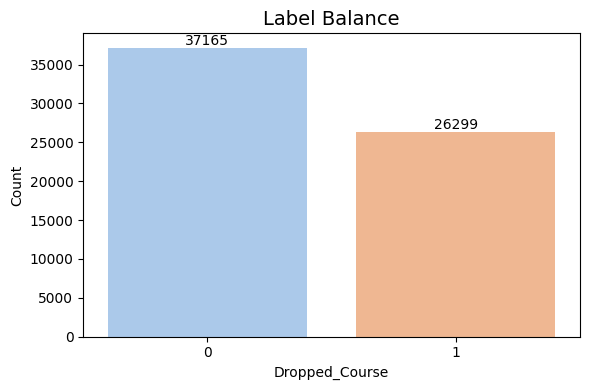

In [20]:
# show how many appereances of each label exists
def plot_label_balance(df, label_col='Dropped_Course'):
    plt.figure(figsize=(6, 4))
    ax = sns.countplot(x=label_col, data=df, palette="pastel")

    plt.title("Label Balance", fontsize=14)
    plt.xlabel("Dropped_Course")
    plt.ylabel("Count")

    for p in ax.patches:
        count = int(p.get_height())
        ax.annotate(count, (p.get_x() + p.get_width() / 2., count),
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()

plot_label_balance(train, label_col='Dropped_Course')

🔍 The target variable Dropped_Course shows a mild class imbalance, with 37,165 students (58.6%) who did not drop out (class 0) and 26,299 students (41.4%) who did (class 1). This 59/41 split is not severe, but it's enough that accuracy alone would be misleading (a naive "always predict 0" model would score 58.6%), so precision, recall, F1-score, and ROC-AUC are more reliable metrics for evaluation - particularly recall on class 1, since correctly identifying at-risk students is the primary goal. This imbalance also motivates including class_weight='balanced' as part of the Logistic Regression hyperparameter tuning.

### **3.2.2 Histograms**

======= DATA – NUMERIC DISTRIBUTIONS =======


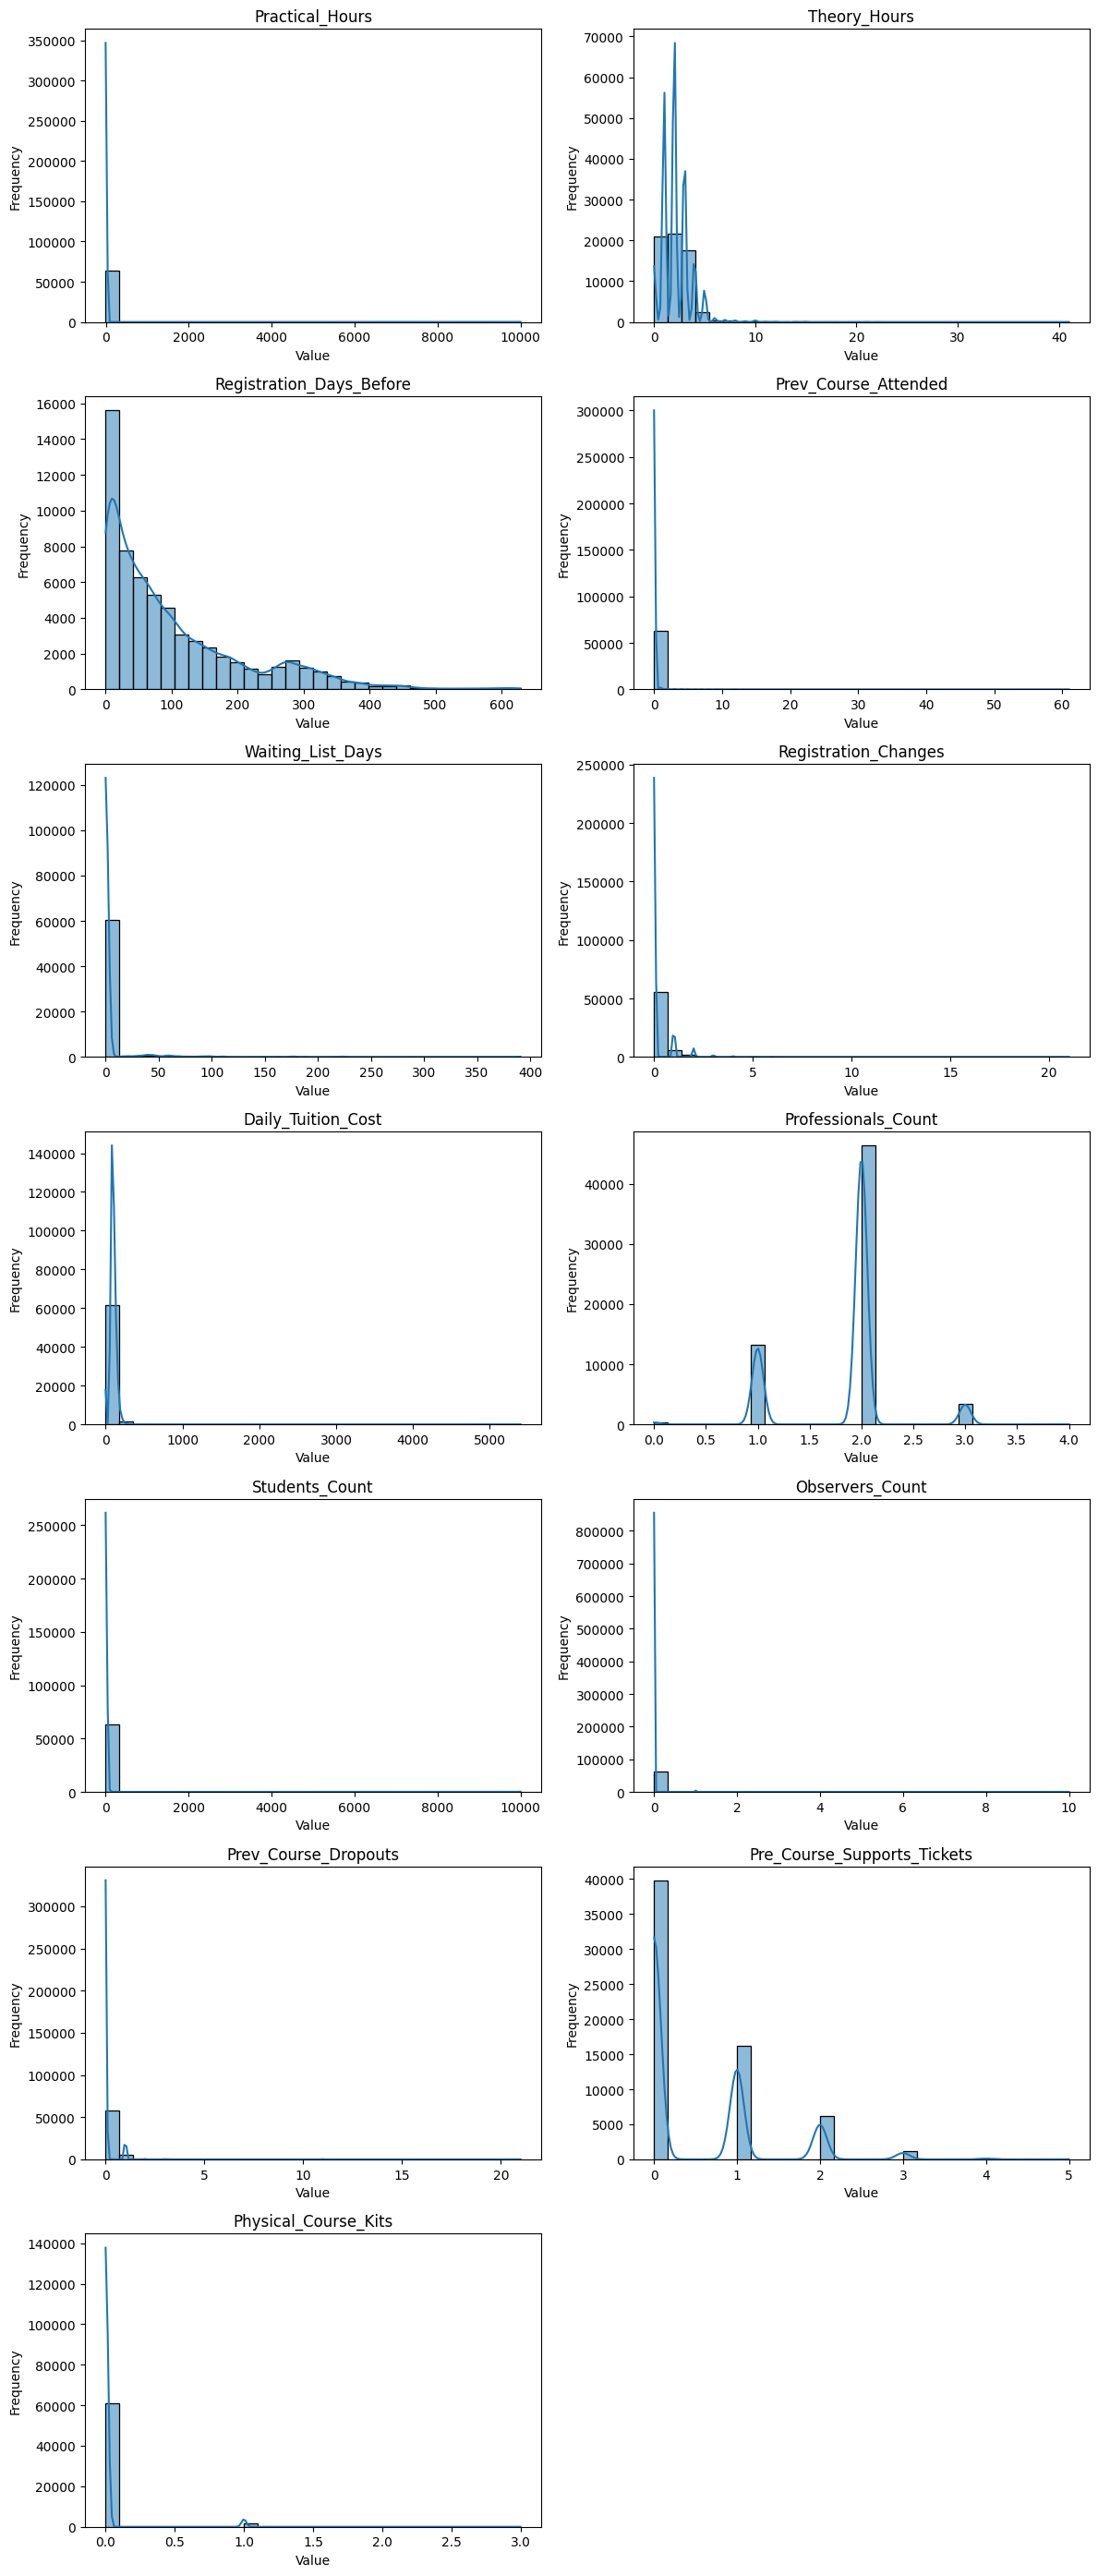

In [21]:
# show numeric cols distribution
plot_numeric_distributions(train, cols=num_cols)

🔍 **Practical_Hours** | This feature is extremely right-skewed — the vast majority of the ~350,000 records cluster near 0, with a long, sparse tail of outliers stretching out to 10,000. This suggests a small number of extreme values are dominating the scale and will likely need log-transformation or capping before modeling.

**Theory_Hours** | Similarly right-skewed but on a smaller scale, this feature peaks around 2–5 hours and decays quickly, with a thin tail extending to ~40. Less extreme than Practical_Hours, but still skewed enough to benefit from a log-transform or scaling for Logistic Regression.

**Registration_Days_Before** | This feature is right-skewed, with most students registering within 0–100 days before the course, and a gradually thinning tail extending out to 600+ days. There's a small secondary bump around 250–300 days, hinting at a possible second group of "late-but-not-last-minute" registrants. Moderate skew — could benefit from a log-transform, though it's not as extreme as the hours features.

**Prev_Course_Attended** | Extremely skewed and dominated by 0 — the overwhelming majority of students attended no previous courses, with only a small fraction attending 1 and a negligible tail out to 60. This looks almost like a near-constant feature; it may be worth treating as categorical/binary (attended vs. not) rather than continuous, since so little variance exists beyond 0–1.

**Waiting_List_Days** | Heavily right-skewed and dominated by near-zero values — most students spend little to no time on a waiting list, with a sharp drop-off and only a thin scatter of outliers extending out to 400 days. This suggests the feature may be near-constant for most of the population, with a small subset of extreme waiters; log-transform or binning (e.g., "waited vs. didn't") could help.

**Registration_Changes** | Similarly skewed, with the vast majority of students making 0 registration changes and a rapidly decaying tail out to ~20. Most of the signal is concentrated in just a few discrete low values (0, 1, 2), so this could work well as a low-cardinality categorical/ordinal feature rather than a continuous one.

**Daily_Tuition_Cost** | Heavily right-skewed, with most values concentrated near 0–200 and a very long, sparse tail extending out to 5000+. This pattern points to a small number of extreme high-cost outliers distorting the scale; log-transform or capping is recommended before modeling.

**Professionals_Count** | A discrete, mostly well-behaved distribution with distinct peaks at 1, 2, and 3 — the vast majority of records cluster at 2. Unlike the other skewed features, this looks close to a clean categorical/ordinal variable and likely needs little to no transformation, though it may benefit from one-hot or ordinal encoding depending on how it's used.

**Students_Count** | Extremely right-skewed, with almost all values compressed near 0–200 and a long, near-empty tail stretching to 10,000. This indicates a handful of extreme outliers are dominating the scale; log-transform or capping is recommended.

**Observers_Count** | Similarly extreme, with the overwhelming majority of records at or near 0 and only negligible values elsewhere out to 10. This feature looks close to constant and may add little predictive value as-is — worth checking its variance/correlation with the target before deciding whether to keep, bin, or drop it.

**Prev_Course_Dropouts** | Heavily skewed toward 0 — the vast majority of students have no prior dropouts, with a small bump around 1 and a negligible tail out to 20+. Very low variance overall; likely most useful as a binary or low-cardinality categorical feature (has dropped before vs. not).

**Pre_Course_Supports_Tickets** | A discrete, multi-modal distribution with clear peaks at 0, 1, 2, and 3, decreasing in frequency as ticket count rises. This is well-behaved and interpretable as-is — more support tickets could plausibly correlate with a higher (or lower) chance of dropping out, making it a potentially useful ordinal feature with no transformation needed.

**Physical_Course_Kits** | Strongly dominated by 0, with a secondary small cluster at 1 and almost nothing beyond that. This looks close to binary (received a kit vs. not) and could be simplified/encoded as such rather than treated as continuous.

### **3.2.3 Boxplots - Numeric Cols Distribution**


======= DATA – NUMERIC BOXPLOTS =======


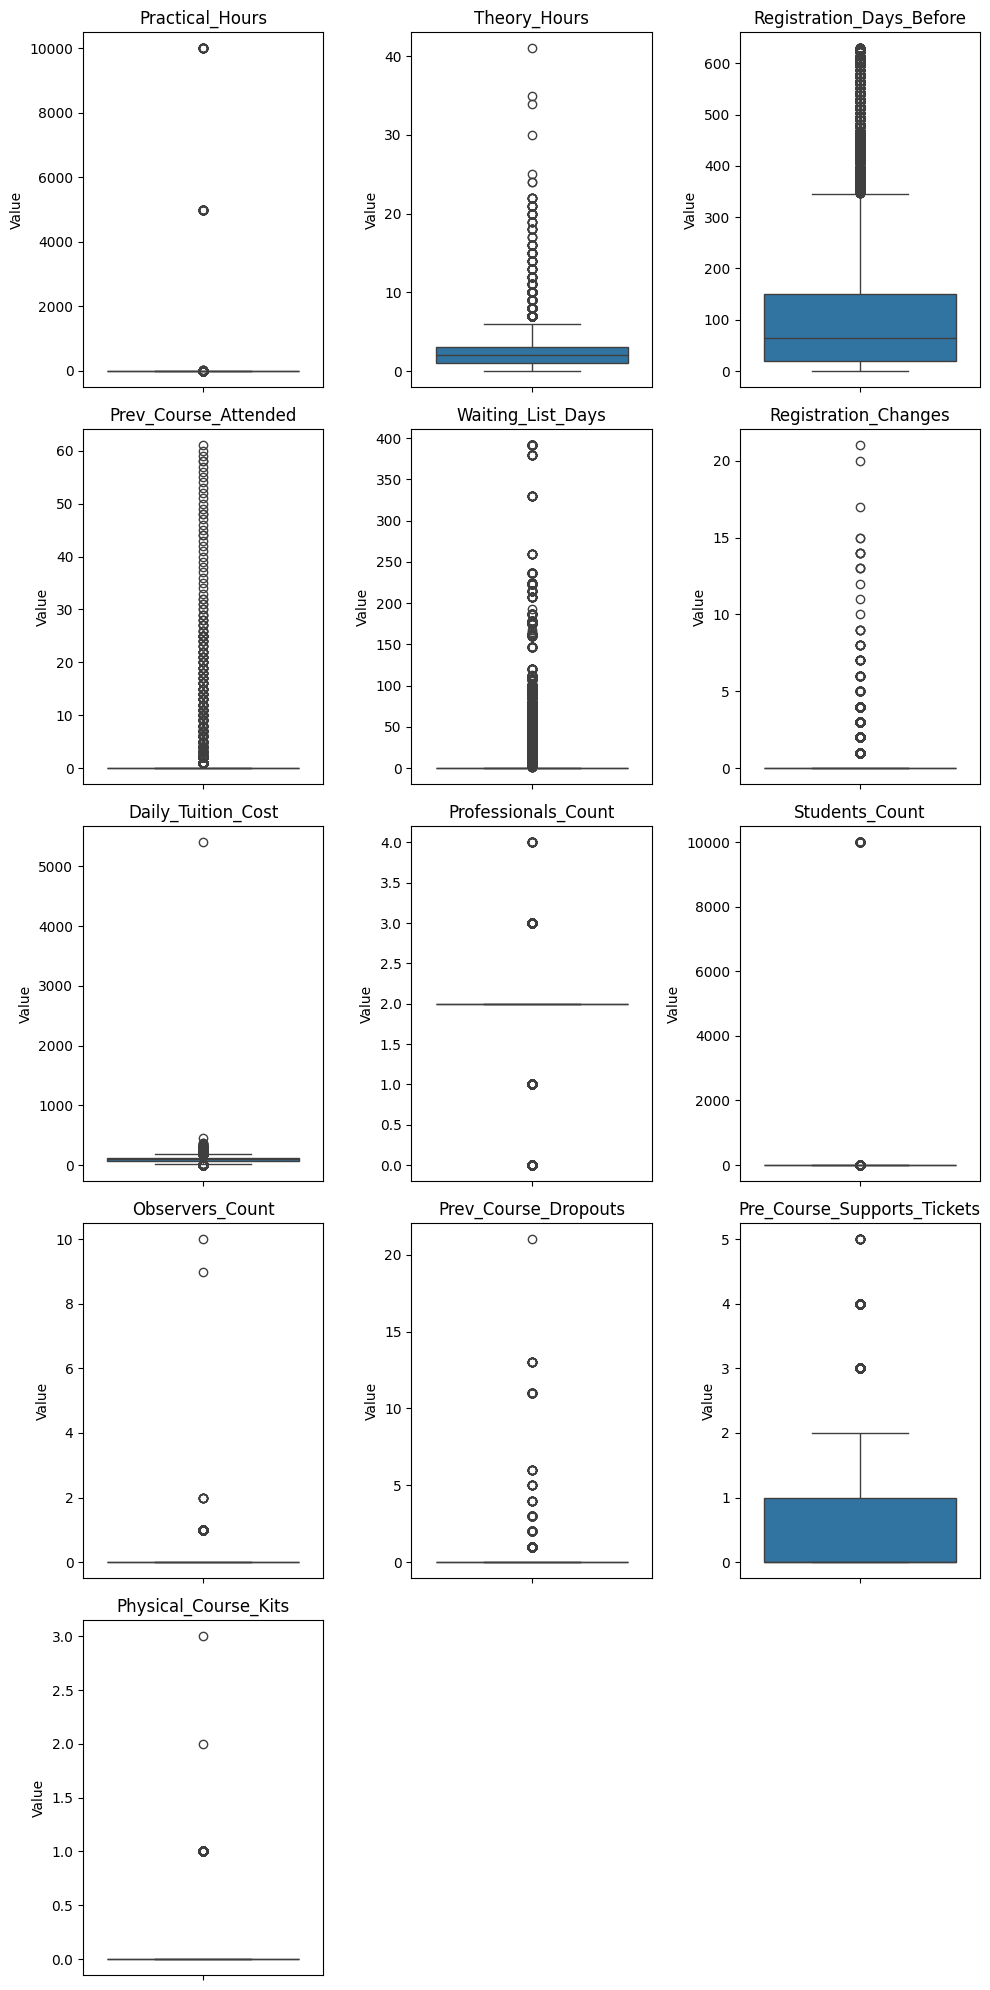

In [22]:
# show numeric cols distribution in boxplots
def plot_numeric_boxplots(df, name="Data"):
    num_plots = len(num_cols)

    print(f"======= {name.upper()} – NUMERIC BOXPLOTS =======")

    ncols = 3
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, 4 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(y=df[col], ax=axes[i])
        axes[i].set_title(col)
        axes[i].set_ylabel("Value")
        axes[i].set_xlabel("")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_numeric_boxplots(train)

🔍 **Practical_Hours** | The boxplot shows an almost invisible box hugging 0, with two extreme outliers at roughly 5,000 and 10,000. This confirms that a couple of anomalous records are stretching the entire scale, while the true bulk of the data lives in a very narrow range near zero - strong candidate for log-transform or capping.

**Theory_Hours** | Here the box sits between roughly 0 and 5, but there's a dense chain of outliers running from ~6 up to 40. Unlike Practical_Hours, this isn't just one or two anomalies - it's a real cluster of higher-than-typical values, suggesting a meaningful subgroup of students with unusually high theory hours rather than pure data errors.

**Registration_Days_Before** | This feature has the most reasonable spread of the three, with an IQR of roughly 20–150 days and a median around 60. There's still a long tail of outliers beyond ~350 days out to 600+, but relative to the median these are far less extreme than the hours features - light capping (e.g., at the 99th percentile) should be sufficient here.

**Prev_Course_Attended** | The box is entirely collapsed at 0, with a dense, continuous chain of outliers running all the way up to ~60. This confirms the near-constant nature seen in the histogram - nearly every student has a value of 0, making outlier "capping" less useful than simply treating this as a binary flag (attended before vs. not).

**Waiting_List_Days** | Similarly collapsed at 0, but the outlier chain is denser at the lower end (up to ~150) with a thinner scatter extending to ~390. This suggests a small but non-trivial group of students who waited unusually long, distinct from the vast majority who waited 0 days - worth considering a binary "waited vs. didn't" flag alongside a capped continuous version.

**Registration_Changes** | The box is again collapsed at 0, with a fairly evenly spaced chain of outliers from ~1 up to 21. Since the values are discrete and low-cardinality, this feature is well-suited to being treated as an ordinal/categorical variable rather than requiring transformation for outliers.

**Daily_Tuition_Cost** | The box sits low and tight (roughly 0–150), with a cluster of moderate outliers up to ~500 and one extreme outlier near 5,400. A single anomalous record is stretching the axis, while a secondary group of genuinely higher-cost records also exists - worth capping at a high percentile rather than removing outliers outright.

**Professionals_Count** | The box is collapsed at 2 (the dominant value), with individual outlier points at 0, 1, 3, and 4. Since this is a small set of discrete values, it's best treated as an ordinal/categorical feature rather than something needing outlier treatment.

**Students_Count** | Almost entirely collapsed at 0, with a single massive outlier at 10,000. This looks like it could be a data entry error or a genuinely unique extreme case - worth investigating individually rather than applying a blanket transformation.

**Observers_Count** | Collapsed at 0 with a handful of outlier points at 1, 2, 9, and 10. Very low variance overall; likely a weak feature unless those rare higher values correlate strongly with the target.

**Prev_Course_Dropouts** | Collapsed at 0, with a discrete scatter of outliers from 1 up to 21. Low-cardinality and mostly zero, similar to Prev_Course_Attended - a binary "has prior dropout" flag may be more useful than the raw count.

**Pre_Course_Supports_Tickets** | This one actually has a real box (IQR 0–1, median ~0) with a scattered whisker up to 2 and outlier points at 3, 4, and 5. Unlike the others, this feature has genuine spread and doesn't need special outlier treatment - it can likely be used close to as-is.

**Physical_Course_Kits** | Collapsed at 0, with outlier points at 1, 2, and 3. Very low variance, similar to the other near-constant count features - a binary flag (received a kit vs. not) is probably more useful than the raw count.


### **3.2.4 Categoric Cols lower/uppercase fixation**

In [23]:
for col in cat_cols:
    if train[col].dtype == 'object':
        train[col] = train[col].str.strip().str.lower()
    elif train[col].dtype.name == 'category' and pd.api.types.is_string_dtype(train[col].cat.categories):
        train[col] = train[col].str.strip().str.lower()

    if col in test.columns:
        if test[col].dtype == 'object':
            test[col] = test[col].str.strip().str.lower()
        elif test[col].dtype.name == 'category' and pd.api.types.is_string_dtype(test[col].cat.categories):
            test[col] = test[col].str.strip().str.lower()

### **3.2.5 Compare Train-Test Sets**

In [24]:
# check if all cols exists
def check_unseen_categories(train_df, test_df):
    cat_cols = train_df.select_dtypes(include=['object', 'category', 'bool']).columns
    result = []

    if len(cat_cols) == 0:
        print("⚠️ No categorical columns found in train set.")
        return pd.DataFrame()

    for col in cat_cols:
        if col in test_df.columns:
            train_vals = set(train_df[col].dropna().unique())
            test_vals = set(test_df[col].dropna().unique())
            unseen = test_vals - train_vals

            if unseen:
                result.append({
                    'Column': col,
                    'Unseen categories in test': list(unseen)
                })

    result_df = pd.DataFrame(result)
    if result_df.empty:
        print("✅ No unseen categories in test – all match train.")
    else:
        print("\n🔸 Unseen categories in test:")
        display(result_df)

    return result_df

# check if all cols matches
def compare_train_test_structure(train_df, test_df, label_col='Dropped_Course'):
    print("====== TRAIN vs TEST STRUCTURE CHECK ======\n")

    if label_col in train_df.columns:
        train_df = train_df.drop(columns=[label_col])

    train_cols = set(train_df.columns)
    test_cols = set(test_df.columns)
    diff1 = train_cols - test_cols
    diff2 = test_cols - train_cols

    print("🔸 Columns in train but not in test:", diff1 if diff1 else 0)
    print("🔸 Columns in test but not in train:", diff2 if diff2 else 0)

    if list(train_df.columns) != list(test_df.columns):
        print("\n🔸 Warning: Column order differs between train and test.")

    mismatched_dtypes = {
        col: (train_df[col].dtype, test_df[col].dtype)
        for col in train_cols & test_cols
        if train_df[col].dtype != test_df[col].dtype
    }

    if mismatched_dtypes:
        print("\n🔸 Columns with mismatched dtypes:")
        for col, dtypes in mismatched_dtypes.items():
            print(f"    {col}: train={dtypes[0]}, test={dtypes[1]}")
    else:
        print("\n✅ All dtypes match.")

    test_missing = test_df.isnull().sum()
    if test_missing.sum() > 0:
        print("\n🔸 Missing values in test:")
        print(test_missing[test_missing > 0])
    else:
        print("\n✅ No missing values in test.")

    check_unseen_categories(train_df, test_df)
    print("\n✅ Structure comparison complete.\n")

compare_train_test_structure(train, test)

====== TRAIN vs TEST STRUCTURE CHECK ======

🔸 Columns in train but not in test: 0
🔸 Columns in test but not in train: 0

🔸 Columns with mismatched dtypes:
    Client_ID: train=category, test=int64
    Company_ID: train=category, test=float64
    Agent_ID: train=category, test=float64

🔸 Missing values in test:
Registration_Days_Before      642
Origin_Country                160
Catering_Package              111
Requested_Lab_Config          477
Physical_Course_Kits          227
Enrollment_Type               177
Submission_Source             149
Agent_ID                     2794
Company_ID                  15297
Payment_Terms                 144
Daily_Tuition_Cost              1
dtype: int64

🔸 Unseen categories in test:


,Column,Unseen categories in test
0,Client_ID,"[32770, 3, 6, 65545, 65546, 65547, 32780, 3278..."
1,Course_Start_Date,"[2017-05-08, 2017-05-06, 2017-07-10, 2017-06-2..."
2,Origin_Country,"[i*ta, i*sr, isr#, isr?, !dnk, c#hn, caf, k#or..."
3,Catering_Package,"[lunch inclu*ded, lu#nch included, no# food pl..."
4,Enrollment_Type,"[affiliated admis?sion, affiliat!ed admission]"
5,Lanyard_Color,"[o*range, gr#een, oran#ge, gree?n, gr*een, gr?..."
6,Client_Category,"[traditio*nal it & telecomm, big tech #& multi..."
7,Submission_Source,"[dire*ct website registration, direct website ..."
8,Agent_ID,"[256.0, 290.0, 195.0, 228.0, 154.0, 282.0, 109..."
9,Company_ID,"[5124.0, 5000.0, 5001.0, 5004.0, 5012.0, 5143...."



✅ Structure comparison complete.



### **3.2.6 Countplots - Categoric Cols Distribution**

======= TRAIN CATEGORICAL COUNTS =======


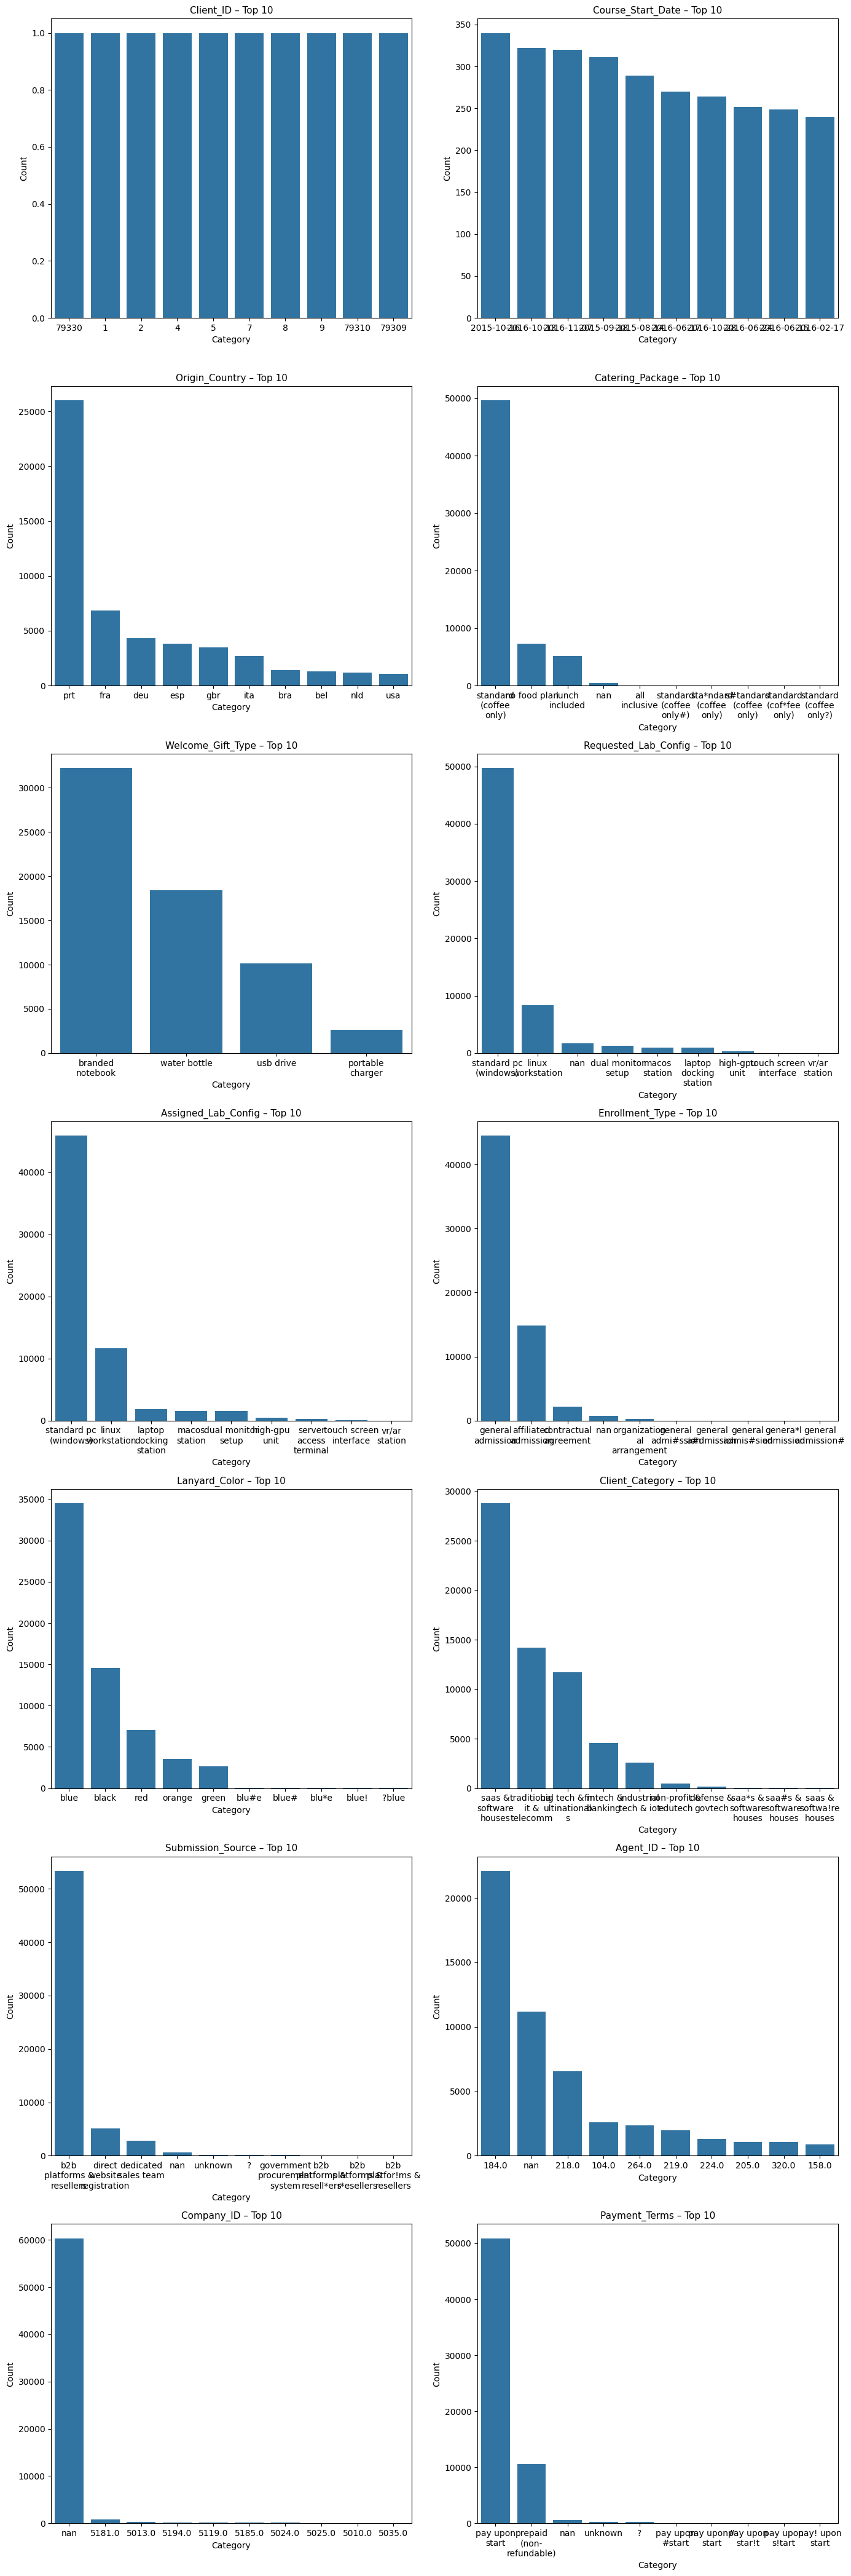

In [25]:
# create categorical cols distribution histogram
plot_categorical_counts(train, name="Train")

🔍 **Client_ID** | Every value appears exactly once - this is a unique identifier, not a predictive feature. It should be excluded from modeling (or used only for indexing/joining).

**Course_Start_Date** | Top values are fairly evenly distributed (~240–340 each), suggesting many distinct course start dates with no single date dominating. This is likely a high-cardinality date field better engineered into features like month, weekday, or season rather than used raw.

**Origin_Country** | Heavily dominated by prt (~26,000), followed by a long tail of much smaller countries (fra, deu, esp, etc.). This imbalance suggests grouping rare countries into an "other" bucket to avoid sparse categories during encoding.

**Catering_Package** | Dominated by standard (~50,000), with no food plan and lunch included far behind. Notably messy - variants like standard, sta*ndard, #tandard suggest inconsistent data entry that needs cleaning/standardizing before encoding.

**Welcome_Gift_Type** | Only 4 clean categories (branded notebook, water bottle, usb drive, portable charger), with branded notebook most common. Low cardinality and relatively clean - should encode easily.

**Requested_Lab_Config** | Strongly dominated by standard pc (windows) (~50,000), with linux workstation a distant second and the rest negligible. Highly imbalanced category - may benefit from grouping rare configs together.

**Assigned_Lab_Config** | Similar pattern to Requested_Lab_Config, dominated by standard pc (windows) then linux workstation. Worth checking how often assigned differs from requested - that mismatch itself could be a useful engineered feature.

**Enrollment_Type** | Dominated by general admission (45,000) and affiliated admission (~15,000), with the rest sparse. Also shows text inconsistency (general admission, genera*l admission, general#admission) - needs cleaning before use.

**Lanyard_Color** | Mostly blue, black, red with a long tail of near-duplicate noisy variants (blu#e, blue!, ?blue). This looks like a low-signal cosmetic field with data-quality issues; cleaning or dropping should be considered.

**Client_Category** | Dominated by saas & software houses (~29,000), followed by a few other sizable segments before a sharp drop-off. Also has messy near-duplicate categories (saa*s & software houses) that should be consolidated during cleaning.

**Submission_Source** | Extremely dominated by b2b platforms & resellers (~54,000), with all other sources negligible. Very low variance - may add little value unless the rare categories are strongly correlated with the target.

**Agent_ID** | No single agent dominates heavily, though 184.0 leads and nan (missing values) is notably the second most frequent - worth investigating why so many records lack an agent ID.

**Company_ID** | Overwhelmingly nan (~60,000 missing), with all actual company IDs each appearing only marginally. This field is mostly missing and may not be usable unless missingness itself is informative (e.g., individual vs. corporate registration).

**Payment_Terms** | Dominated by pay upon start (51,000) and prepaid (non-refundable) (~10,500), with messy near-duplicate variants (pay upon #start, pay upon star!t) that need standardizing. A relatively clean, informative feature once cleaned.

### **3.2.7 Outliers**

======= DATA – NUMERIC DISTRIBUTIONS =======


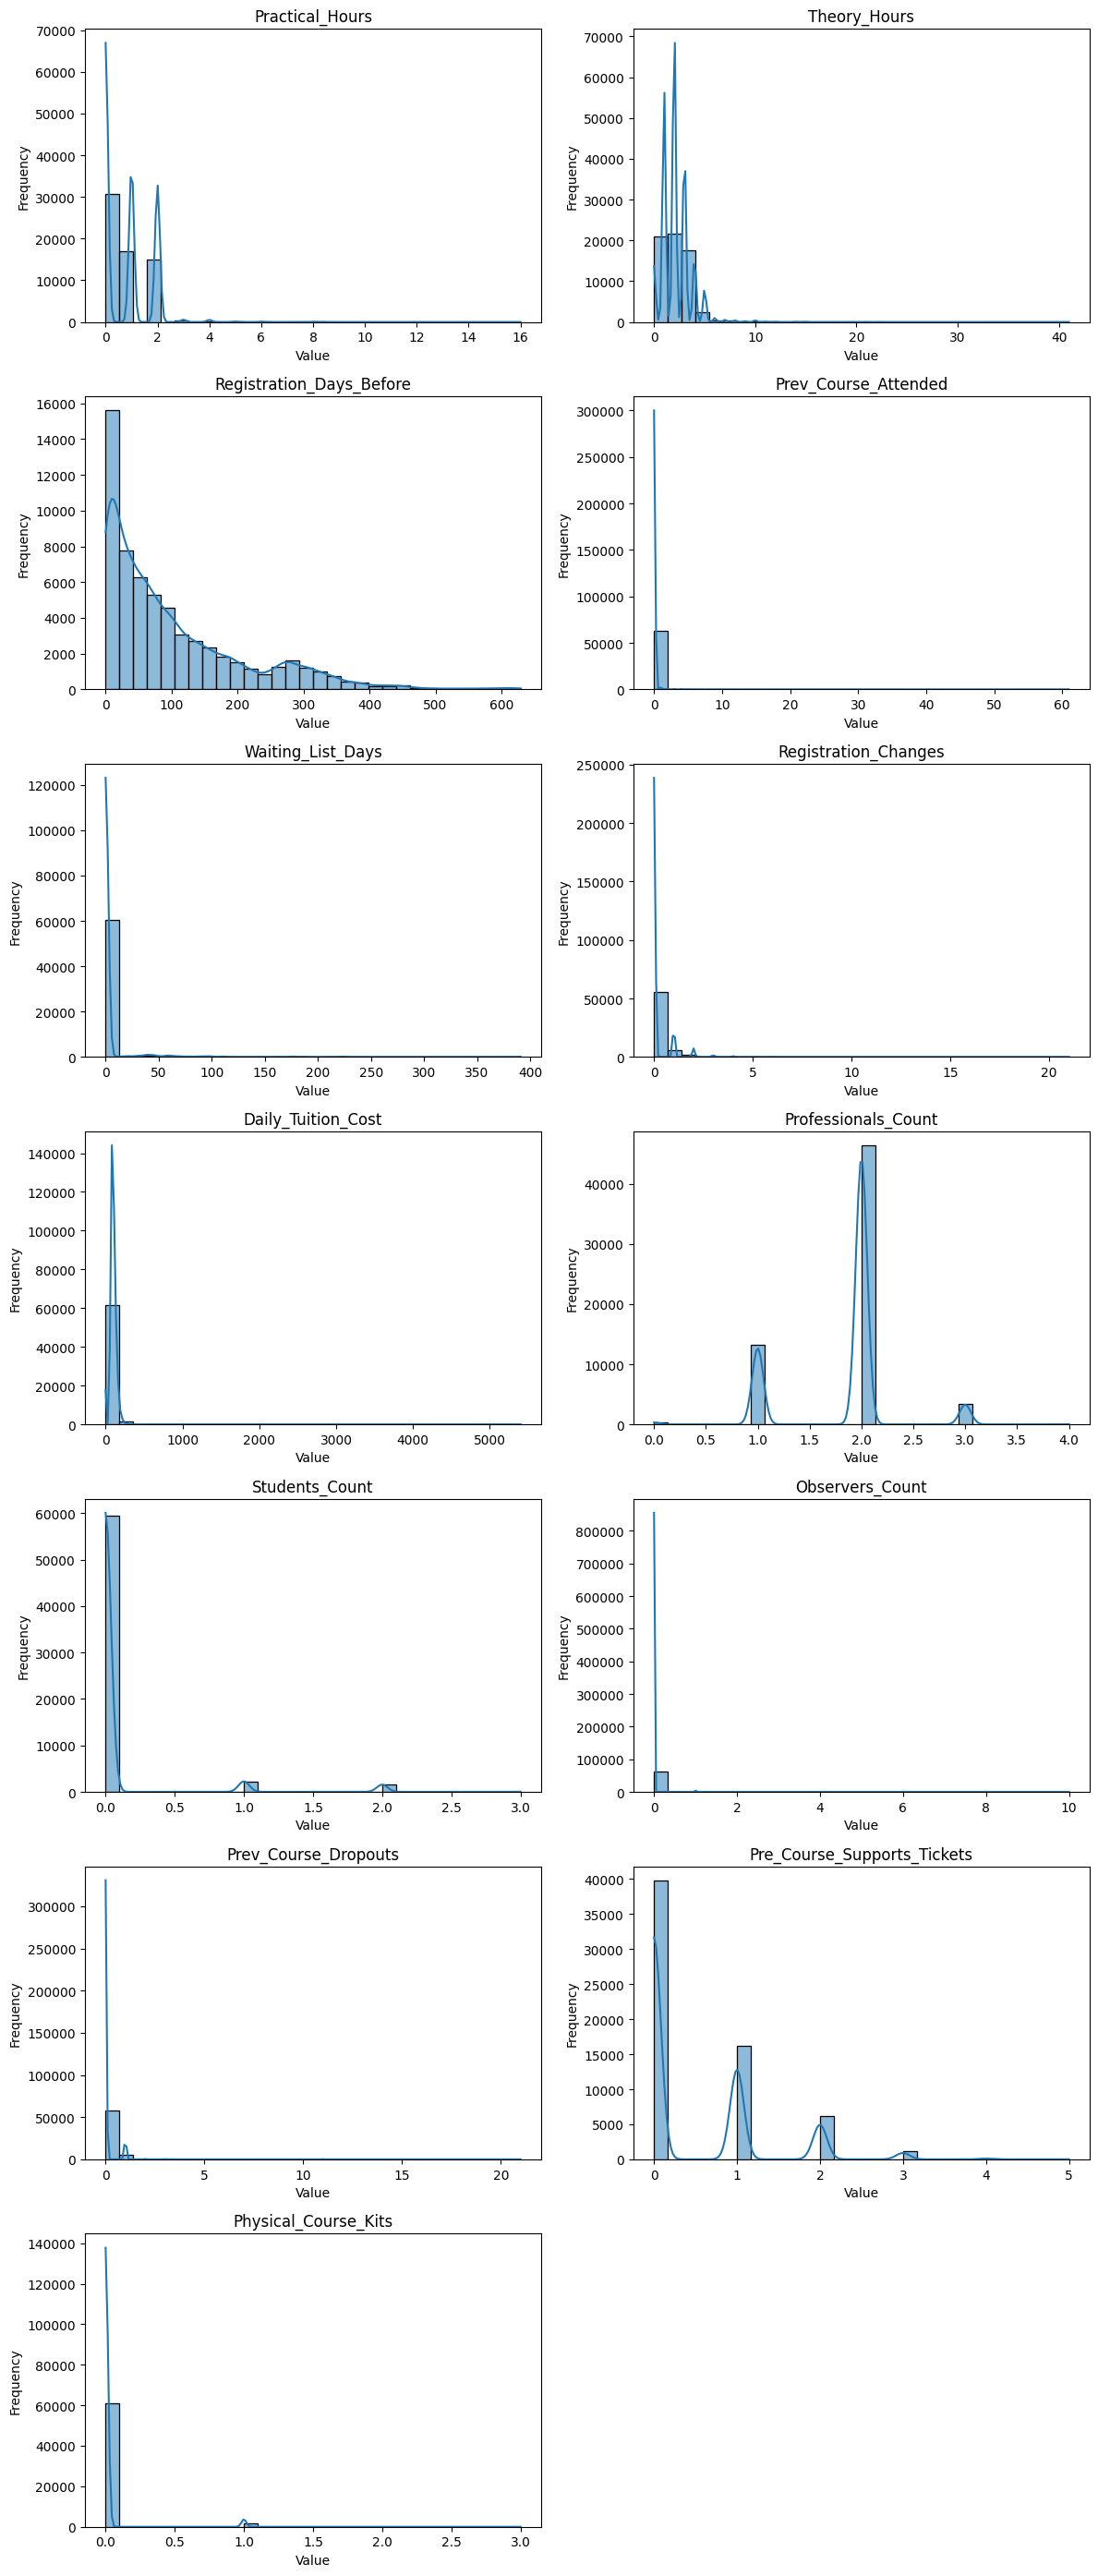

======= DATA – NUMERIC BOXPLOTS =======


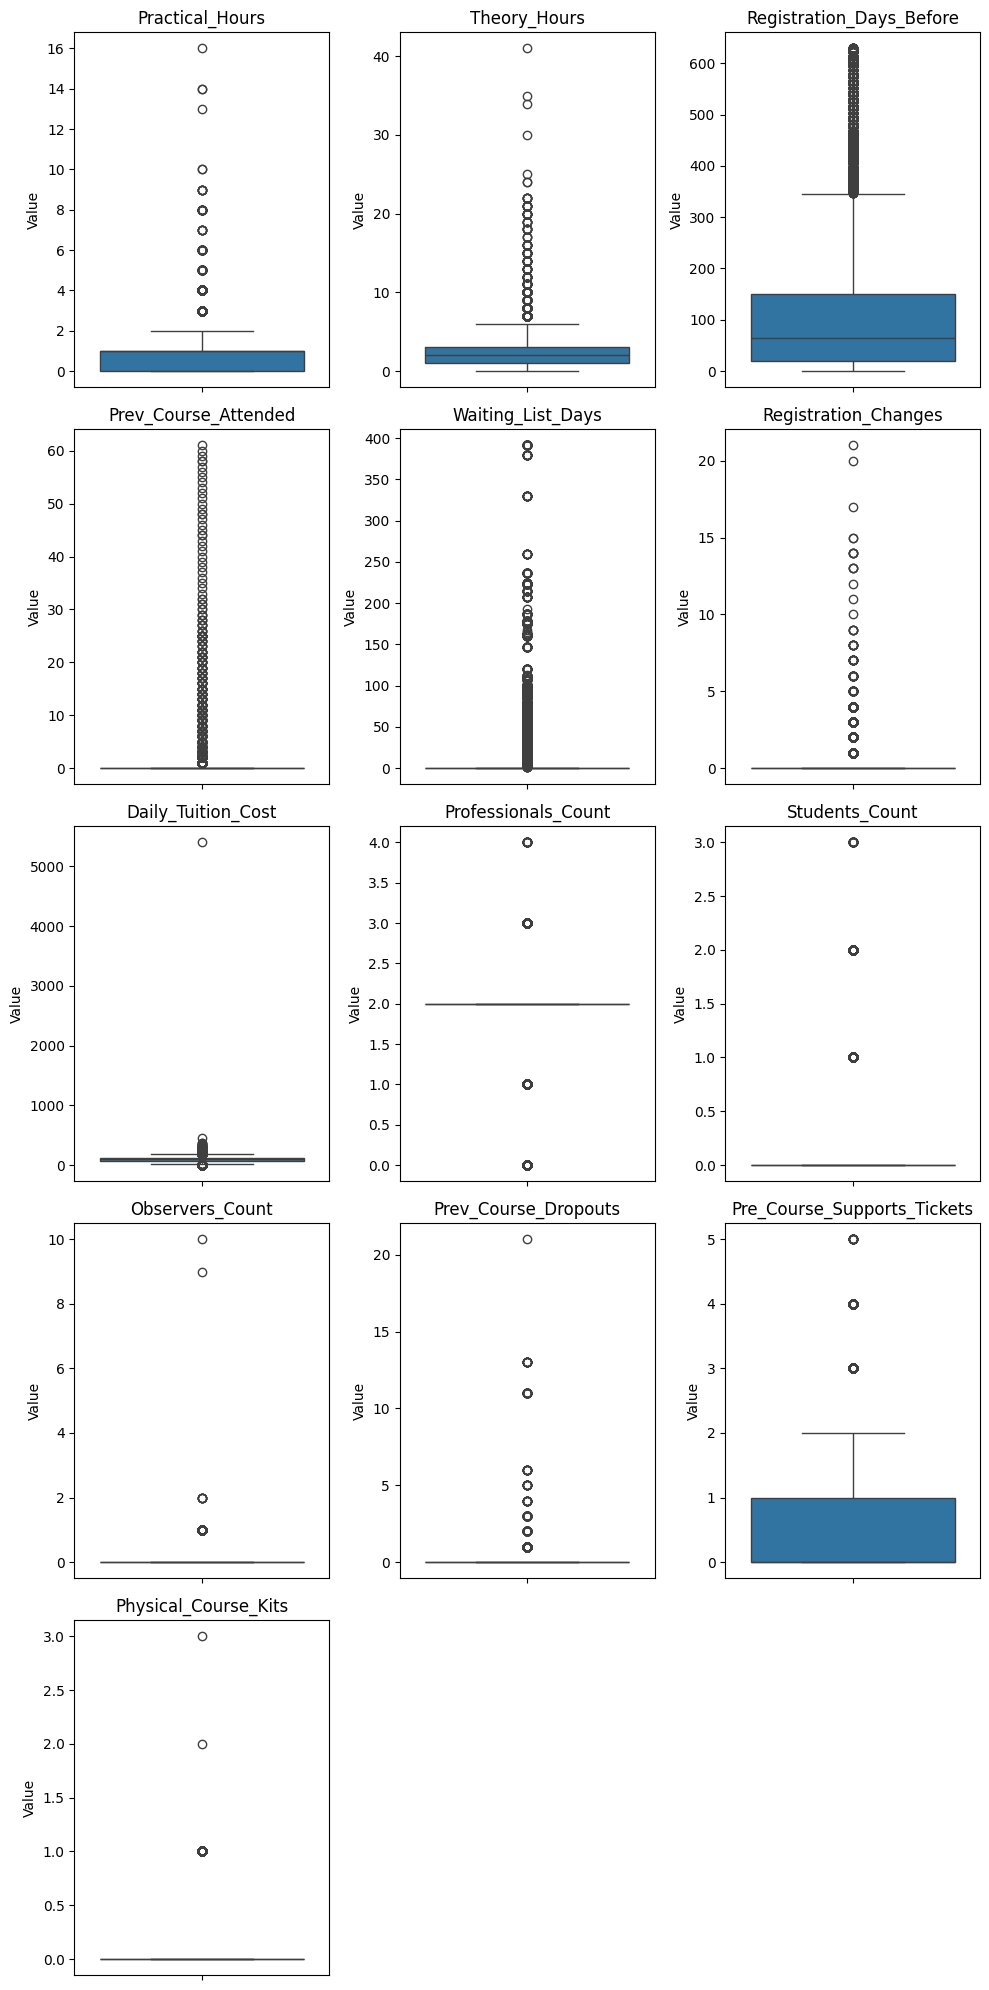

In [26]:
# fix known sentinel/error values before any outlier statistics are computed
for df_ in [train, test]:
    df_.loc[df_['Students_Count'] == 9999, 'Students_Count'] = np.nan
    df_.loc[df_['Practical_Hours'] < 0, 'Practical_Hours'] = np.nan
    df_.loc[df_['Practical_Hours'] >= 5000, 'Practical_Hours'] = np.nan

plot_numeric_distributions(train, cols=num_cols)
plot_numeric_boxplots(train)

🔍 **Data Cleaning Step**: Before recalculating outlier statistics, three known sentinel/error values were corrected: Students_Count == 9999 (an obvious placeholder, not a real value) was set to NaN, and Practical_Hours values that were negative (impossible) or ≥5000 (the extreme outliers seen earlier) were also set to NaN. This prevents these data-entry errors from distorting statistics, scaling, and model coefficients.

**Practical_Hours (updated)**: With the extreme 5,000/10,000 errors removed, the distribution now reveals its true shape - a series of distinct peaks at 0, 1, and 2, decaying quickly after that, with a much more reasonable set of outliers up to ~16. This is a far more usable distribution than before.

**Theory_Hours:** Unchanged from before - still peaks around 2–5 with a long thin tail out to ~40. No sentinel values were found here, so it retains the same moderate outlier profile.

**Registration_Days_Before:** Unchanged - still right-skewed with a reasonable IQR (~20–150) and a gradually thinning tail out to 600+ days.
Prev_Course_Attended: Unchanged - still dominated by 0 with a sparse chain of outliers up to ~60, confirming this is best treated as a near-binary feature.

**Waiting_List_Days:** Unchanged - still collapsed at 0 with a small cluster of longer-waiting outliers up to ~390.
Registration_Changes: Unchanged - still a discrete, low-cardinality feature ranging 0–21, well suited to ordinal treatment.
Daily_Tuition_Cost: Unchanged - the single extreme outlier near 5,400 remains, along with a secondary cluster up to ~500; this feature wasn't targeted by the cleaning step and may need its own capping treatment separately.

**Professionals_Count:** Unchanged - still a clean discrete feature peaking at 2, with 0, 1, 3, 4 as minor outliers.

**Students_Count (updated):** The removal of the 9999 sentinel value means the extreme 10,000 outlier is now gone from the picture - the distribution is now tightly bound to 0–3, revealing this feature is essentially a small discrete count rather than something with genuine extreme values. This is a much more trustworthy and usable feature now.

**Observers_Count:** Unchanged - still collapsed at 0 with scattered outliers up to 10.

**Prev_Course_Dropouts:** Unchanged - still dominated by 0 with a discrete tail up to ~21.

**Pre_Course_Supports_Tickets:** Unchanged - still a well-behaved discrete distribution with peaks at 0–3, no outlier treatment needed.

**Physical_Course_Kits:** Unchanged - still collapsed at 0 with a small cluster at 1, suited to binary treatment.

**Overall takeaway:** The sentinel-value fix meaningfully cleaned up two features - Practical_Hours and Students_Count - both of which previously had their entire distributions distorted by a handful of impossible or placeholder values. Now that these are set to NaN, they'll need imputation (e.g., median) before modeling, but their true underlying distributions are far more sensible and won't disproportionately skew the Logistic Regression coefficients or scaling. Daily_Tuition_Cost still has an unresolved extreme outlier that wasn't addressed by this cleaning step and should be handled separately.

In [27]:
# discover numeric continuous features
def get_continuous_features(df, unique_threshold=15):
    continuous_cols = []

    for col in num_cols:
        unique_vals = df[col].dropna().unique()
        has_decimals = any(val % 1 != 0 for val in unique_vals)
        if has_decimals or len(unique_vals) > unique_threshold:
            continuous_cols.append(col)

    return continuous_cols

continuous_features = get_continuous_features(train)
print("Continuous numeric features:")
for col in continuous_features:
    print(f"• {col}")

if continuous_features == num_cols:
    print("\n All numeric features are continuous.")
else:
    print("\n NOT all numeric features are continuous.")

Continuous numeric features:
• Theory_Hours
• Registration_Days_Before
• Prev_Course_Attended
• Waiting_List_Days
• Registration_Changes
• Daily_Tuition_Cost

 NOT all numeric features are continuous.


In [28]:
# check if features distributes normaly to decide IQR Vs. Z-score
for col in continuous_features:
    try:
        stat, p = shapiro(train[col].dropna())
        print(f'{col}: p-value = {p:.4f} {"✓ Normal" if p > 0.05 else "✗ Not normal"}')
    except Exception as e:
        print(f'{col}: Error - {e}')

Theory_Hours: p-value = 0.0000 ✗ Not normal
Registration_Days_Before: p-value = 0.0000 ✗ Not normal
Prev_Course_Attended: p-value = 0.0000 ✗ Not normal
Waiting_List_Days: p-value = 0.0000 ✗ Not normal
Registration_Changes: p-value = 0.0000 ✗ Not normal
Daily_Tuition_Cost: p-value = 0.0000 ✗ Not normal


In [29]:
# find outliers using IQR
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = ((train[num_cols] < lower_bound) | (train[num_cols] > upper_bound))

outliers_iqr_count = outliers_iqr.sum().sort_values(ascending=False)

print("Number of outliers per feature (IQR method):")
print(outliers_iqr_count)

print("\nPercentage of outliers and their effect on mean and std:")

for col in outliers_iqr_count.index:
    outlier_mask = outliers_iqr[col]
    percent = 100 * outlier_mask.sum() / len(train)

    mean_full = train[col].mean()
    std_full = train[col].std()
    mean_clean = train.loc[~outlier_mask, col].mean()
    std_clean = train.loc[~outlier_mask, col].std()

    print(f"▫️{col}: {percent:.2f}% outliers | Mean full={mean_full:.2f}, clean={mean_clean:.2f} | Std full={std_full:.2f}, clean={std_clean:.2f}")


Number of outliers per feature (IQR method):
Professionals_Count            17063
Registration_Changes            7986
Prev_Course_Dropouts            5280
Students_Count                  3827
Waiting_List_Days               3375
Daily_Tuition_Cost              2874
Registration_Days_Before        2177
Physical_Course_Kits            1634
Pre_Course_Supports_Tickets     1283
Prev_Course_Attended            1276
Practical_Hours                  600
Theory_Hours                     569
Observers_Count                  315
dtype: int64

Percentage of outliers and their effect on mean and std:
▫️Professionals_Count: 26.89% outliers | Mean full=1.84, clean=2.00 | Std full=0.51, clean=0.00
▫️Registration_Changes: 12.58% outliers | Mean full=0.18, clean=0.00 | Std full=0.59, clean=0.00
▫️Prev_Course_Dropouts: 8.32% outliers | Mean full=0.10, clean=0.00 | Std full=0.45, clean=0.00
▫️Students_Count: 6.03% outliers | Mean full=0.09, clean=0.00 | Std full=0.36, clean=0.00
▫️Waiting_List_Days: 5.3

### **3.2.8 Anomalies**

In [30]:
# use Isolation Forest method to find anomalies in train data (using random distribution)
iso = IsolationForest(contamination=0.01, random_state=42)
anomaly_labels = iso.fit_predict(train[num_cols])
anomalies = train[anomaly_labels == -1]

print(f"Number of anomalies detected: {anomalies.shape[0]}")

anomaly_ratio = len(anomalies) / len(train) * 100
print(f"Percentage of anomalies: {anomaly_ratio:.2f}%")

Number of anomalies detected: 635
Percentage of anomalies: 1.00%


🔍 An anomaly rate of 1% is considered relatively low, and therefore it's generally reasonable to leave these anomalies as is—provided they do not significantly distort the distribution of the features or affect model performance.

In [31]:
# use LOF method to find anomalies in train data (by density)
lof = LocalOutlierFactor(n_neighbors=20)
lof_data = train[num_cols].dropna()
train_cleaned = train.loc[lof_data.index].copy()
train_cleaned['lof_score'] = lof.fit_predict(lof_data)
anomalies_lof = train_cleaned[train_cleaned['lof_score'] == -1]

print(f"Number of anomalies detected by LOF: {len(anomalies_lof)}")

percentage = len(anomalies_lof) / len(train_cleaned) * 100
print(f"Percentage of anomalies: {percentage:.2f}%")

Number of anomalies detected by LOF: 6274
Percentage of anomalies: 10.53%


In [32]:
# find anomalies in categorical features by percentae of appereances
for col in cat_cols:
    counts = train[col].value_counts(normalize=True)
    rare = counts[counts < 0.005]
    if not rare.empty:
        print(f"💠Rare categories in '{col}':")
        if len(rare) > 15:
            print(f"  - {len(rare)} rare categories in this feature❗️")
        else:
            for category, proportion in rare.items():
                print(f"  - {category}: {proportion:.4%}")
        print()

💠Rare categories in 'Course_Start_Date':
  - 663 rare categories in this feature❗️

💠Rare categories in 'Origin_Country':
  - 392 rare categories in this feature❗️

💠Rare categories in 'Catering_Package':
  - 188 rare categories in this feature❗️

💠Rare categories in 'Requested_Lab_Config':
  - touch screen interface: 0.0194%
  - vr/ar station: 0.0113%

💠Rare categories in 'Assigned_Lab_Config':
  - server access terminal: 0.3813%
  - touch screen interface: 0.1749%
  - vr/ar station: 0.0126%

💠Rare categories in 'Enrollment_Type':
  - 183 rare categories in this feature❗️

💠Rare categories in 'Lanyard_Color':
  - 100 rare categories in this feature❗️

💠Rare categories in 'Client_Category':
  - 355 rare categories in this feature❗️

💠Rare categories in 'Submission_Source':
  - 194 rare categories in this feature❗️

💠Rare categories in 'Payment_Terms':
  - 138 rare categories in this feature❗️

💠Rare categories in 'Client_ID':
  - 63464 rare categories in this feature❗️

💠Rare categorie

## **3.3 Bivariate Analysis**

### **3.3.1 Barplots (Categoric Vs. Label)**

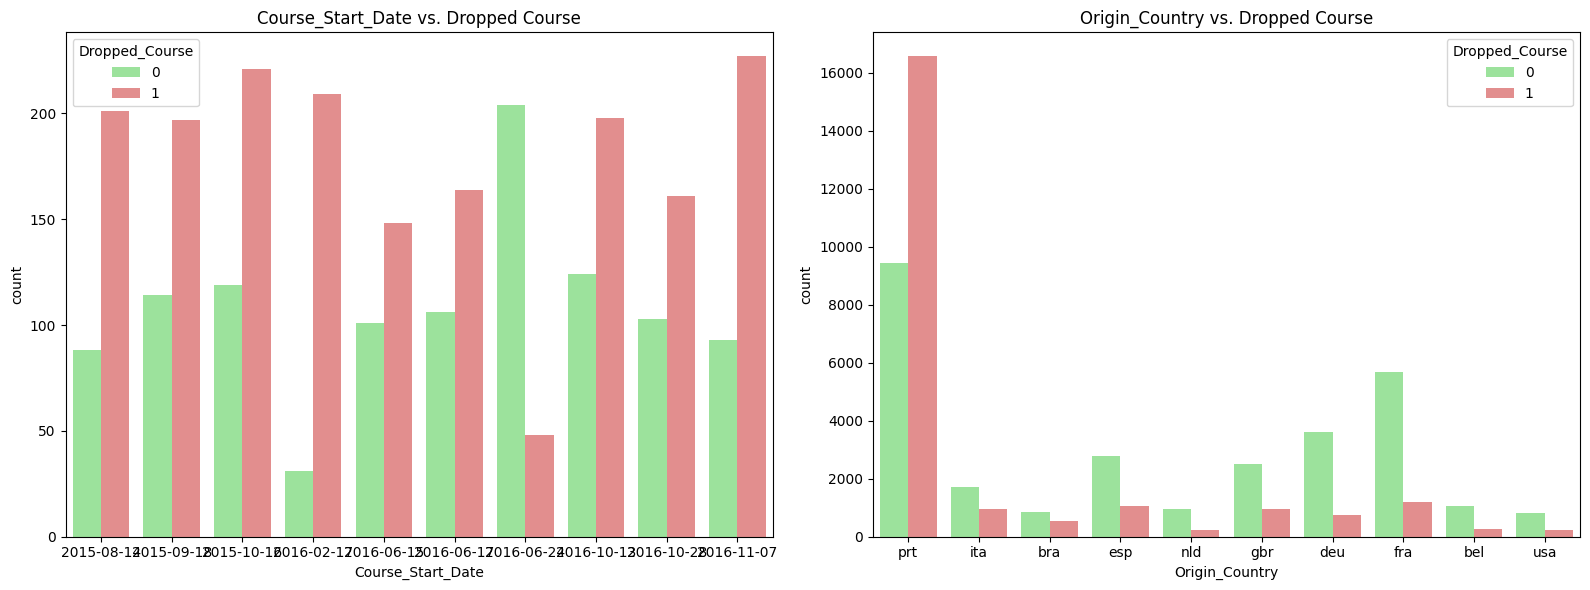

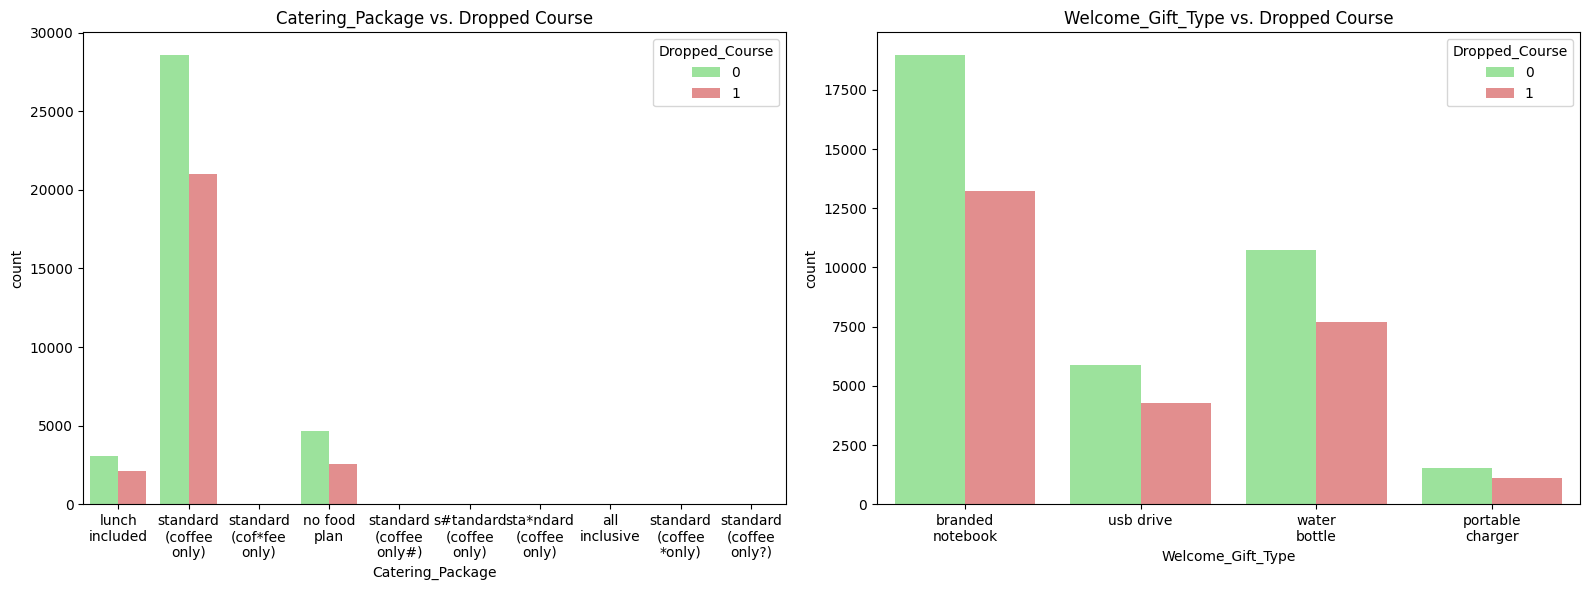

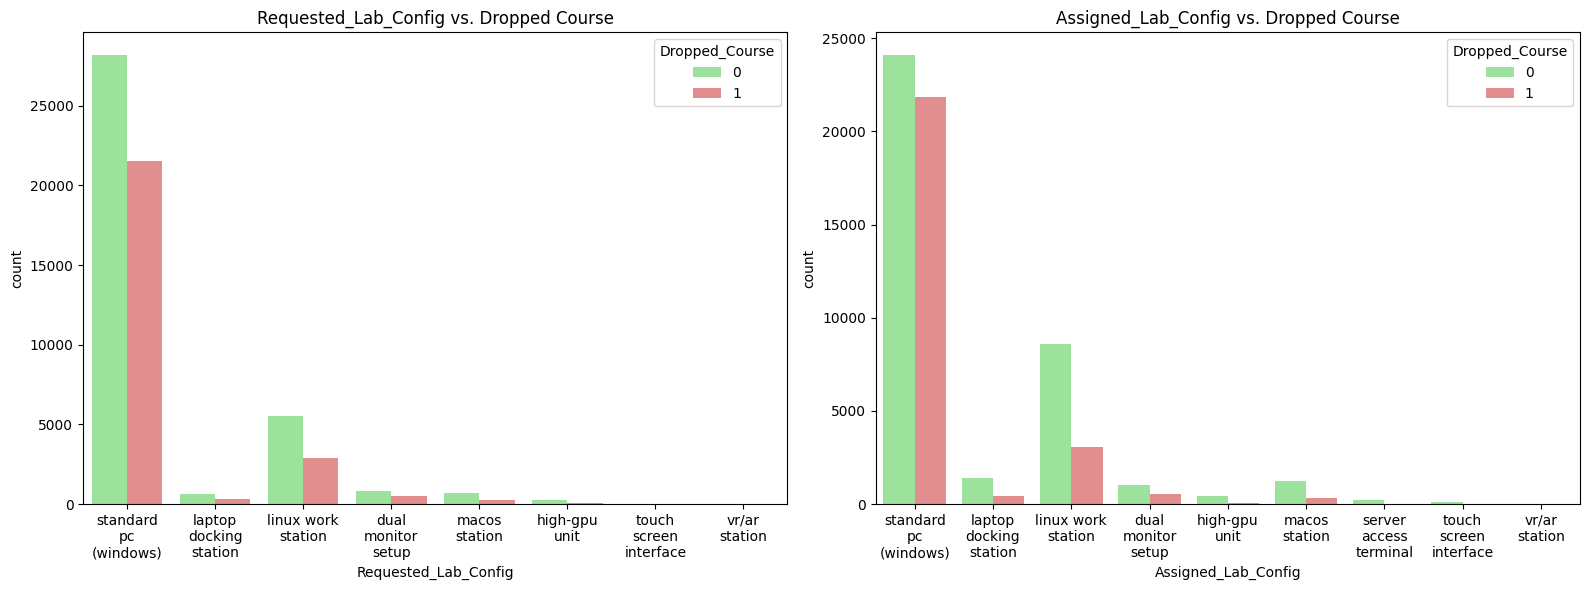

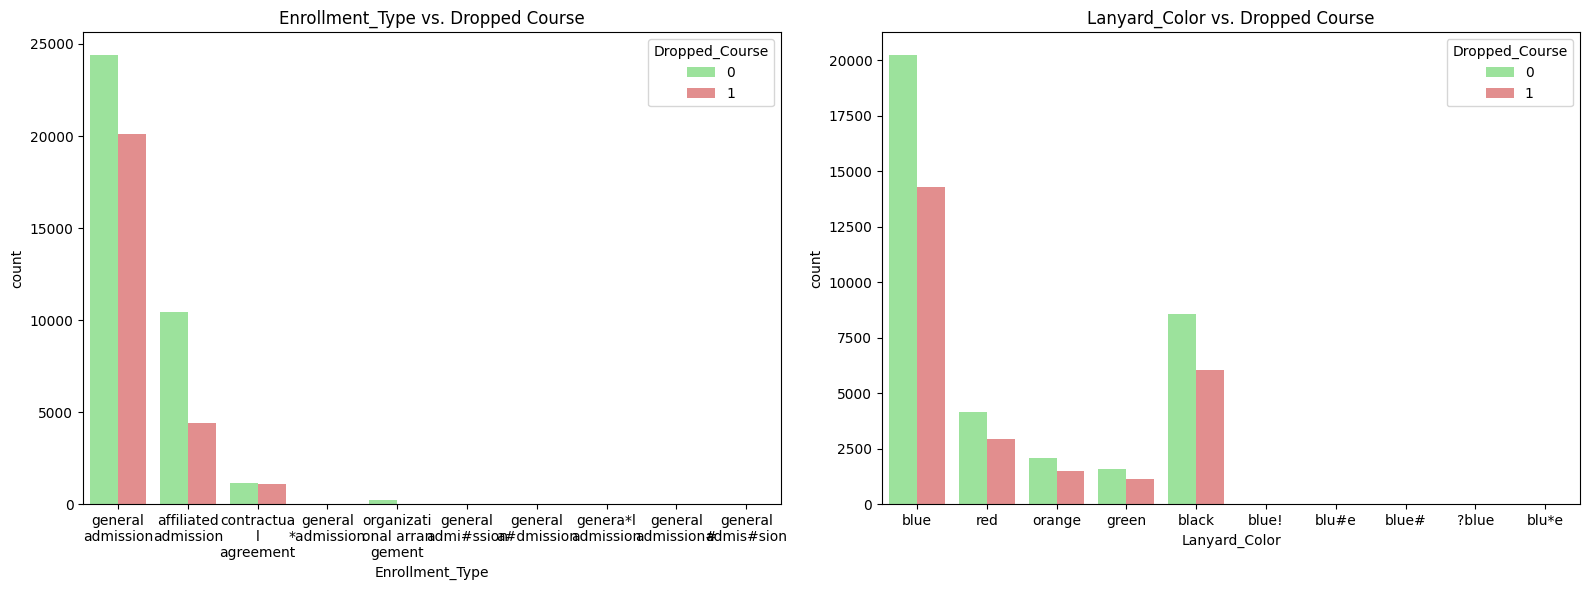

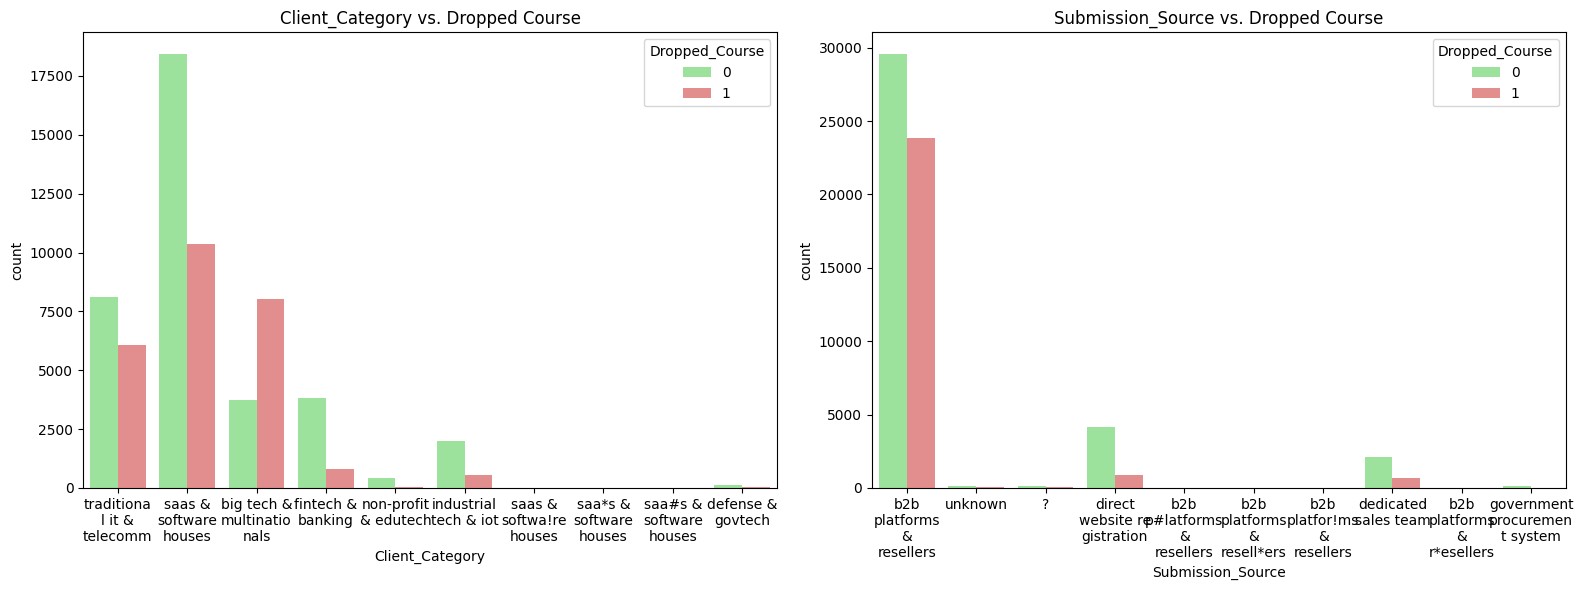

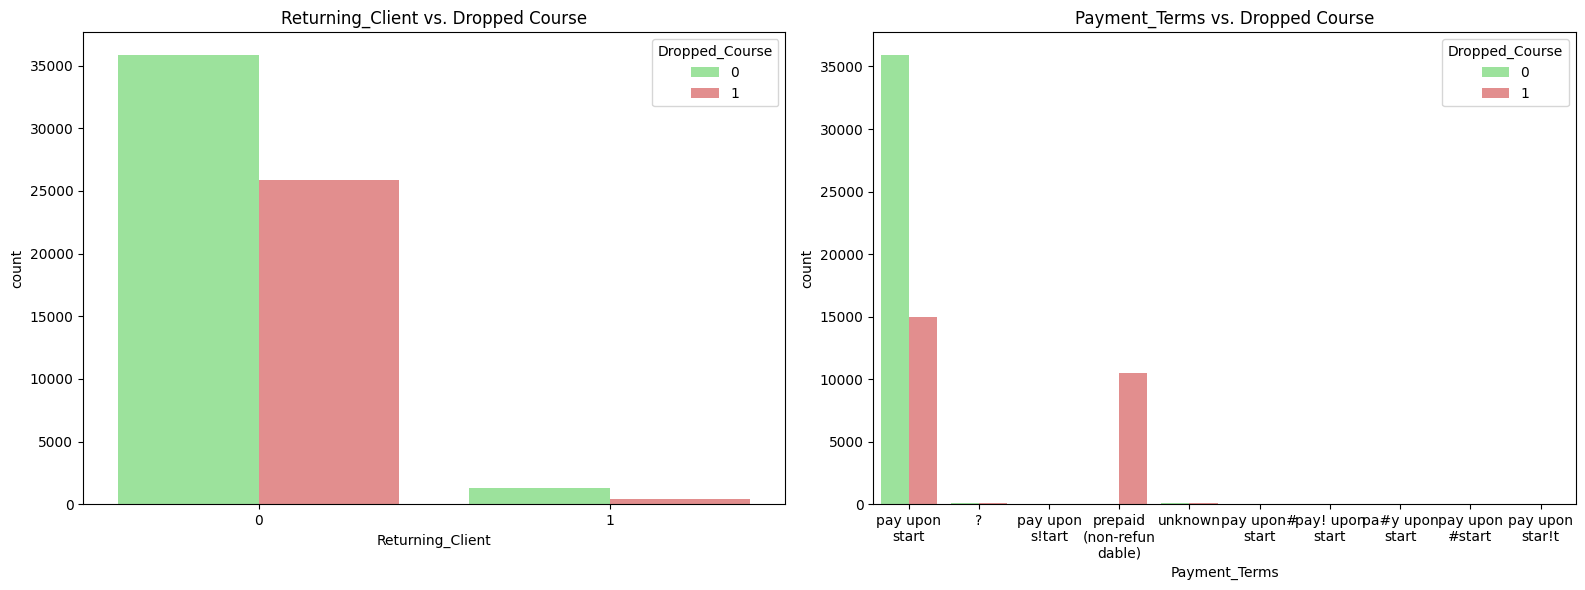

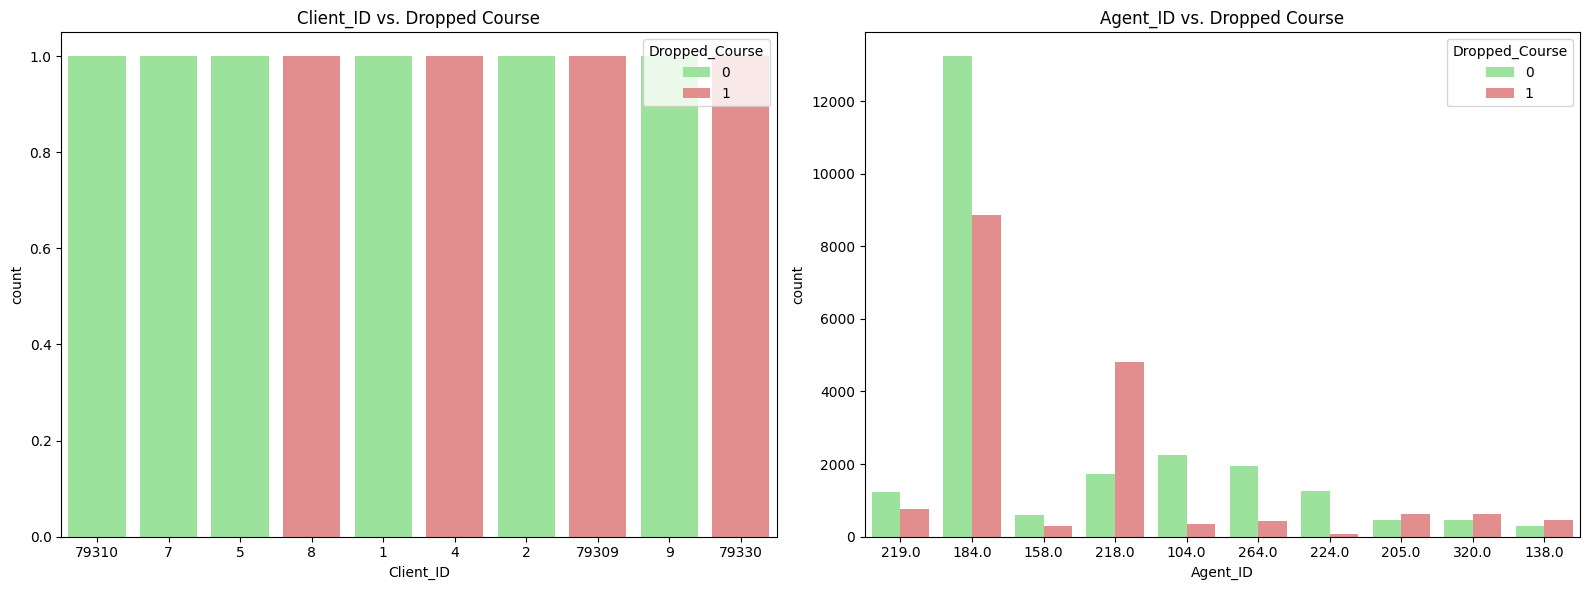

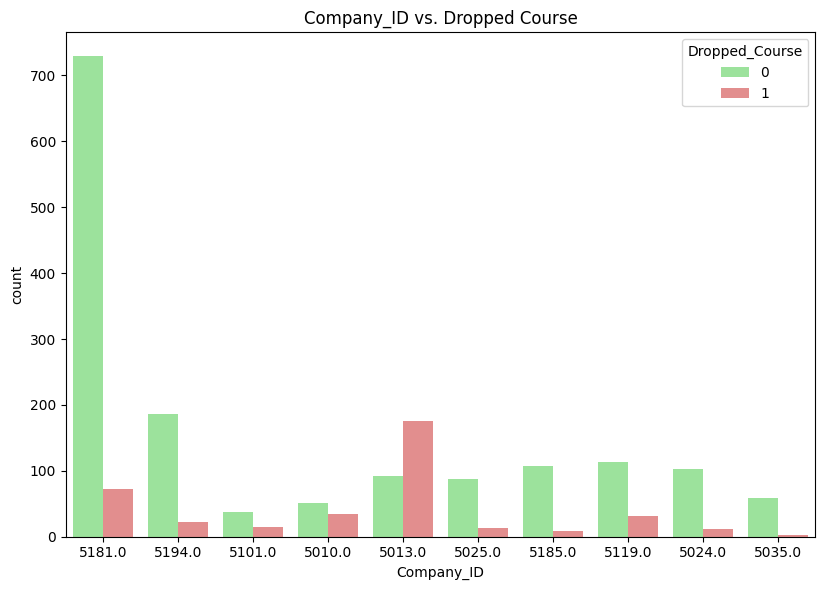

In [33]:
# show relationship between categorical features and the label
top_k = 10

label_palette = {0: 'lightgreen', 1: 'lightcoral'}

for i in range(0, len(cat_cols), 2):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for j in range(2):
        if i + j < len(cat_cols):
            col = cat_cols[i + j]
            top_values = train[col].value_counts().nlargest(top_k).index
            subset = train[train[col].isin(top_values)].copy()

            if subset.empty:
                fig.delaxes(axes[j])
                continue

            subset[col] = subset[col].astype(str).apply(lambda x: '\n'.join(textwrap.wrap(x, 10)))
            sns.countplot(data=subset, x=col, hue=label, palette=label_palette, ax=axes[j])
            axes[j].set_title(f"{col} vs. Dropped Course")
            axes[j].tick_params(axis='x', rotation=0)
        else:
            fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

🔍 **Course_Start_Date vs. Dropped_Course:** Dropout rates vary noticeably by start date - some dates (e.g., 2015-08-14, 2015-10-18, 2016-11-07) show far more dropouts than non-dropouts, while others (e.g., 2016-06-22) show the opposite. This suggests course start date carries real signal, likely tied to seasonality, cohort size, or external factors - worth engineering into month/season features rather than using raw dates.

**Origin_Country vs. Dropped_Course:** prt dominates in volume and has a higher dropout count than retention count, unlike most other countries where retention outweighs dropout. This points to a meaningful country-level effect on dropout risk, making Origin_Country a potentially strong predictive feature (after grouping rare countries).

**Catering_Package vs. Dropped_Course:** The standard (coffee only) category shows a fairly balanced 28.5k/21k split, while no food plan also shows more retention than dropout. The messy near-duplicate categories still need consolidation, but the clean version of this feature does show some separation between classes.

**Welcome_Gift_Type vs. Dropped_Course:** All four gift types show roughly the same ~60/40 retention-to-dropout ratio, mirroring the overall label balance. This suggests Welcome_Gift_Type has little independent relationship with dropout - likely a weak predictor.

**Requested_Lab_Config vs. Dropped_Course:** Most configs roughly track the overall ~59/41 split, though standard pc (windows) and linux workstation show a somewhat higher dropout proportion than the baseline. Mild signal, not dramatic.

**Assigned_Lab_Config vs. Dropped_Course:** Similar to Requested_Lab_Config, most categories track close to the overall balance, with standard pc (windows) again near parity between classes. Comparing this to the requested config (i.e., whether a student got what they asked for) may be more informative than either field alone.

**Enrollment_Type vs. Dropped_Course:** general admission shows a near-even split (24.4k vs 20k) - a notably higher dropout rate than the overall average — while affiliated admission shows stronger retention (10.5k vs 4.4k). This is a meaningful signal: affiliated students appear less likely to drop out than general admissions.

**Lanyard_Color vs. Dropped_Course:** All colors roughly track the overall ~59/41 ratio, with no color standing out as strongly predictive. Likely a weak or cosmetic feature, consistent with earlier suspicion.

**Client_Category vs. Dropped_Course:** Strong differences emerge here - big tech & multinationals shows more dropouts than retentions (a reversal of the overall trend), while traditional it & telecomm and fintech & banking skew toward retention. This makes Client_Category one of the more promising categorical predictors.

**Submission_Source vs. Dropped_Course:** b2b platforms & resellers and direct website registration both roughly track the overall balance, while dedicated sales team shows better retention (skewing green). Given how dominant the top category is, this feature may have limited discriminative power outside that comparison.

**Returning_Client vs. Dropped_Course:** Both returning (1) and non-returning (0) clients show similar retention-to-dropout ratios, close to the overall baseline. This suggests Returning_Client alone isn't strongly predictive, though it's worth keeping since the small returning-client group might interact with other features.

**Payment_Terms vs. Dropped_Course:** This is one of the strongest signals in the dataset - pay upon start shows a ~36k/15k split favoring retention, while prepaid (non-refundable) is entirely (or almost entirely) associated with dropout. This strongly suggests prepayment terms are highly predictive of course completion and should be a key feature (after cleaning the messy variants).

**Client_ID vs. Dropped_Course:** As expected for a unique identifier, each ID appears exactly once and belongs entirely to one class or the other - this is an artifact of uniqueness, not a real relationship, and confirms this field must be excluded from modeling.

**Agent_ID vs. Dropped_Course:** Dropout rates vary meaningfully by agent - some agents (e.g., 218.0) have a much higher share of dropouts than retentions, while others (e.g., 184.0, 264.0) show mostly retention. This suggests Agent_ID may capture real variation in how students are recruited/onboarded, making it a potentially useful (if high-cardinality) feature.

**Company_ID vs. Dropped_Course:** Similarly, individual companies show quite different ratios - 5013.0 skews heavily toward dropout, while 5181.0 and 5119.0 skew toward retention. Given this field is mostly missing (as seen earlier), its predictive value is likely limited to the subset of records where it's populated, but that subset shows real signal.

### **3.3.2 Boxplots (Numeric Vs. Label)**

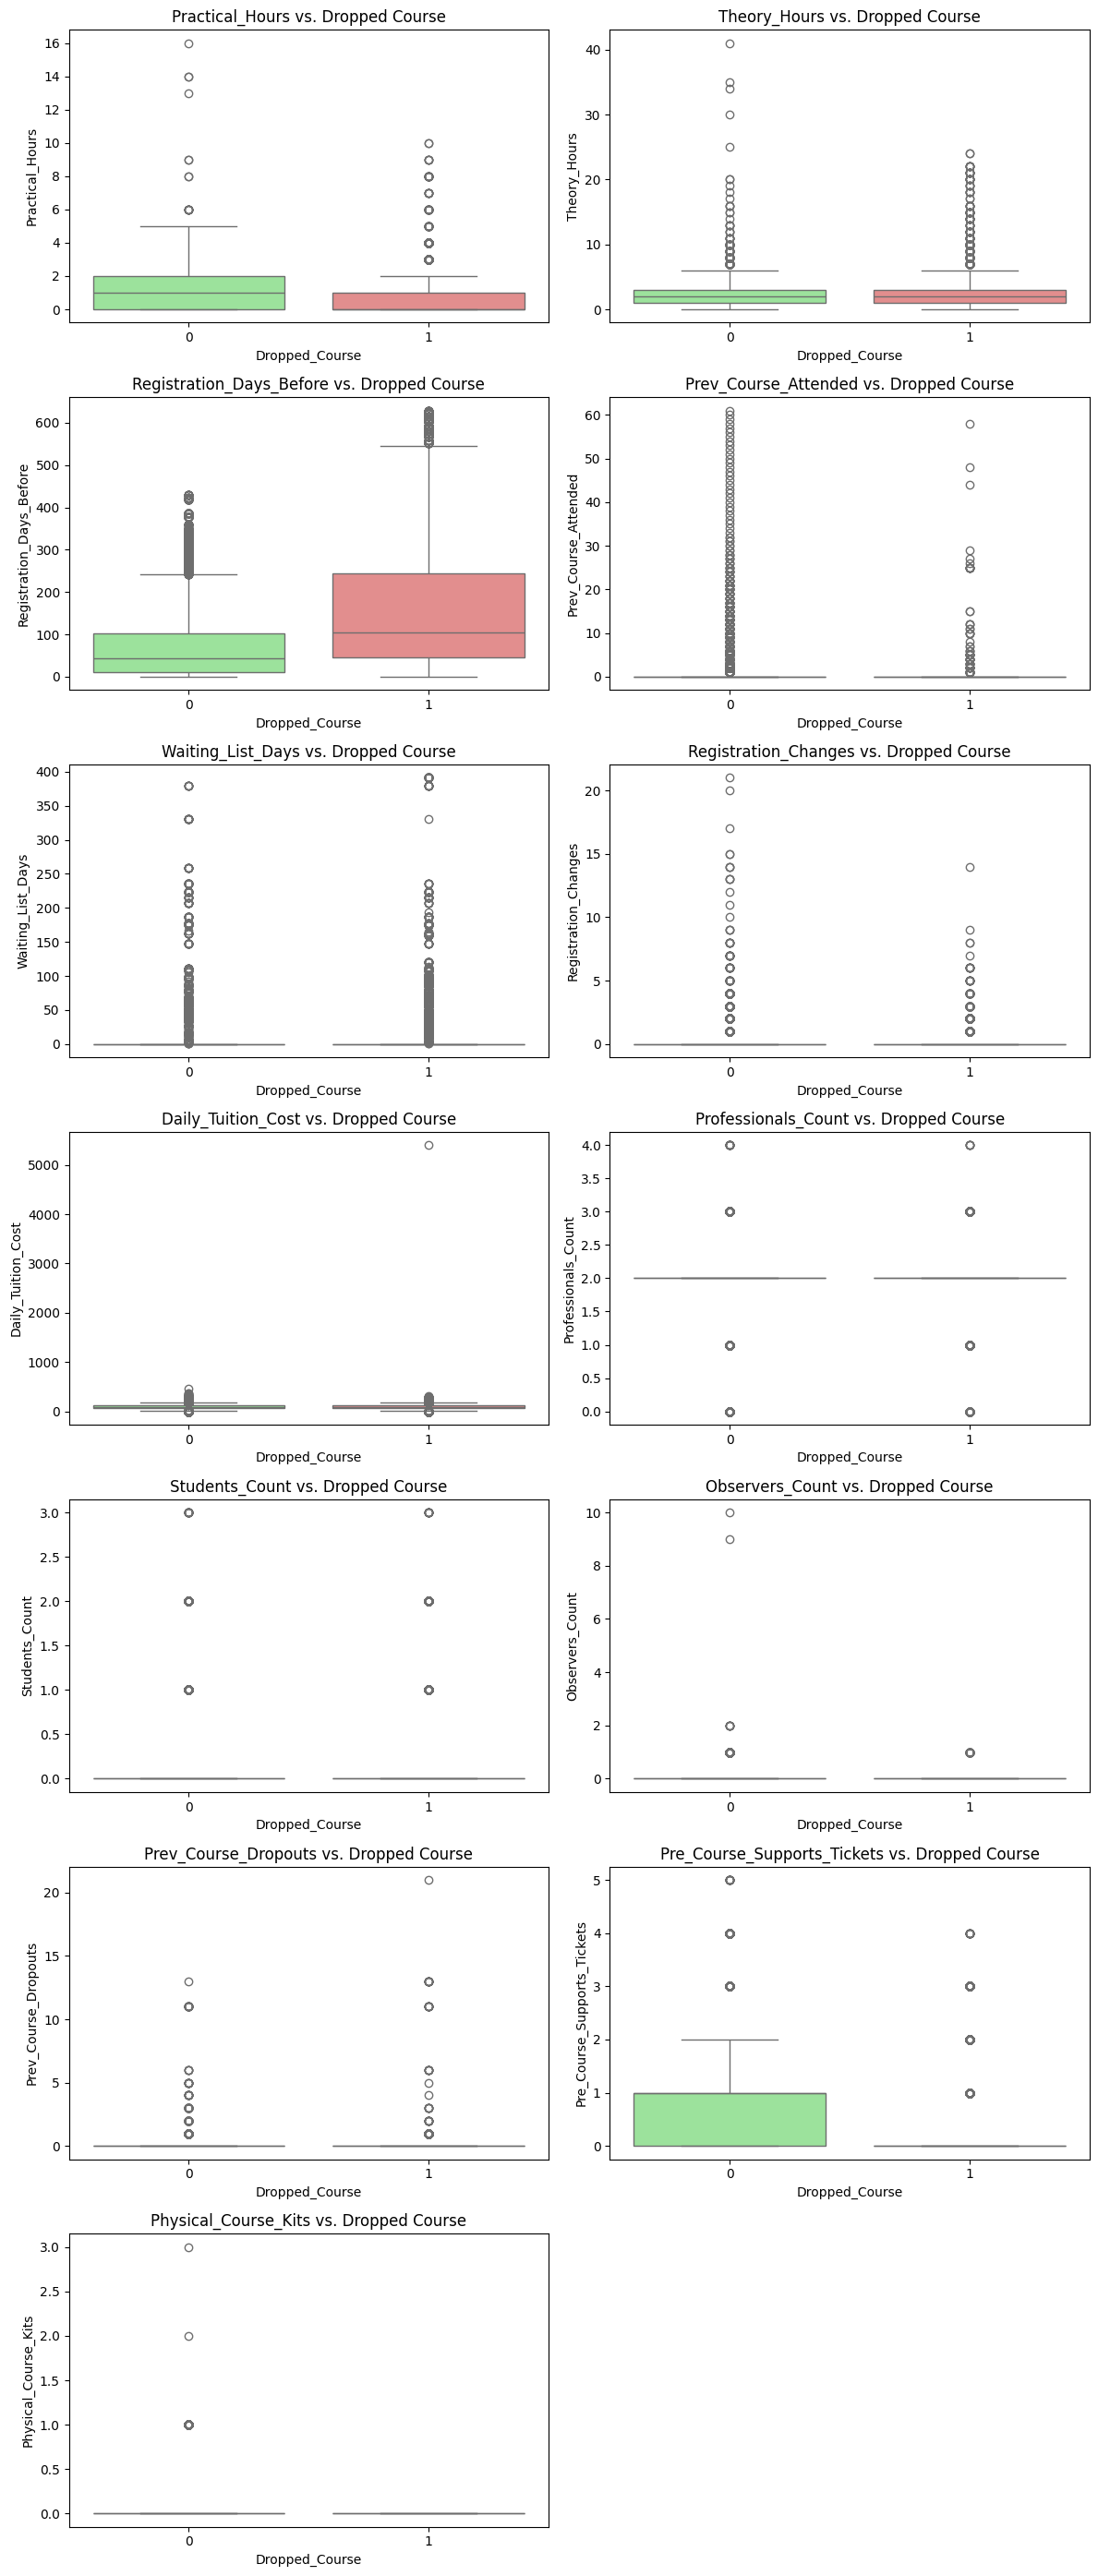

In [34]:
# boxplots for numeric cols and label
colors = {'0': 'lightgreen', '1': 'lightcoral'}
train[label] = train[label].astype(int)

ncols = 2
nrows = math.ceil(len(num_cols) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=label, y=col, data=train, ax=axes[i], palette=colors)
    axes[i].set_title(f'{col} vs. Dropped Course')

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

🔍 **Practical_Hours vs. Dropped_Course:** Students who dropped out (1) show a slightly lower median and tighter spread than those who stayed (0), whose whisker extends further (up to ~5). A mild but real separation - dropouts may have logged fewer practical hours.

**Theory_Hours vs. Dropped_Course:** The two groups look almost identical in median and IQR, with similar outlier ranges on both sides. Little to no separation here - Theory_Hours likely has weak standalone predictive power.

**Registration_Days_Before vs. Dropped_Course:** This is one of the strongest signals so far - dropouts (1) have a much higher median (100 days) and wider IQR (50-240) compared to non-dropouts (0), whose median sits around 60 with a tighter IQR (20-100). Registering far in advance appears associated with a higher chance of dropping out.

**Prev_Course_Attended vs. Dropped_Course:** Both groups are collapsed at 0 with sparse outlier chains, and non-dropouts (0) actually show a denser/higher outlier chain than dropouts. Minimal meaningful separation given how concentrated the data is at zero.

**Waiting_List_Days vs. Dropped_Course:** Both classes look very similar, collapsed at 0 with a scatter of outliers up to ~400. No strong visual separation between groups.

**Registration_Changes vs. Dropped_Course:** Non-dropouts (0) show a denser and higher-reaching outlier chain (up to 21) compared to dropouts (1, up to ~14). A slight tendency for students who make more registration changes to not drop out, though the effect looks modest.

**Daily_Tuition_Cost vs. Dropped_Course:** Both groups have similar tight boxes near 0, though the single extreme outlier (~5,400) falls in the dropout (1) group. Not a clear pattern beyond that one outlier - worth checking if it's meaningful or an error.

**Professionals_Count vs. Dropped_Course:** Nearly identical distributions between the two classes, both centered at 2 with the same range of outliers (0–4). No meaningful separation.

**Students_Count vs. Dropped_Course:** Both groups are collapsed at 0 with a similar small scatter up to 3. No visible difference between classes.

**Observers_Count vs. Dropped_Course:** Non-dropouts (0) show a wider outlier spread (up to 10) than dropouts (1, up to ~1). Given how rare non-zero values are overall, this difference is likely not very meaningful on its own.

**Prev_Course_Dropouts vs. Dropped_Course:** Both groups are collapsed at 0 with similar-looking outlier chains up to ~21. No clear separation visible.

**Pre_Course_Supports_Tickets vs. Dropped_Course:** Non-dropouts (0) show a real box (IQR 0-1) with a whisker up to 2, while dropouts (1) are almost entirely collapsed at 0 with just scattered outliers. This suggests students who submitted more support tickets before the course were more likely to stay - possibly reflecting engagement.

**Physical_Course_Kits vs. Dropped_Course:** Both groups are collapsed at 0, though dropouts (1) show a denser cluster of outliers up to 3 compared to non-dropouts (0). Slight suggestion that receiving a physical kit might correlate with dropping out, though the effect is subtle given how concentrated the data is at zero.

**Overall takeaway:** Registration_Days_Before stands out as the clearest numeric predictor - dropouts register notably earlier on average. Pre_Course_Supports_Tickets and Practical_Hours show smaller but visible differences. Most other numeric features (Theory_Hours, Waiting_List_Days, Professionals_Count, Students_Count, Prev_Course_Dropouts) show little to no separation between classes on their own, though they could still contribute in combination with other features during modeling.

### **3.3.3 Correlation**

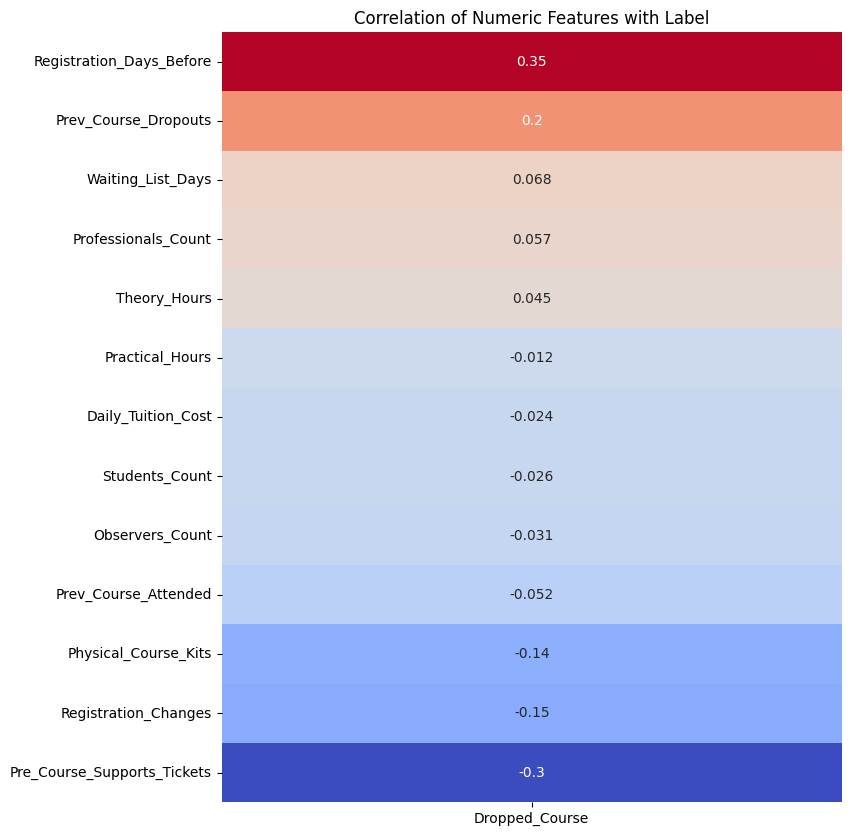

In [35]:
# Compute correlation matrix using predefined num_cols
target = label
corr_matrix = train[num_cols + [target]].corr()

# Focus on correlation with the label
corr_with_label = corr_matrix[target].drop(target).sort_values(ascending=False)

# Display as heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(corr_with_label.to_frame(), annot=True, cmap='coolwarm', cbar=False)
plt.title("Correlation of Numeric Features with Label")
plt.show()

🔍 Correlation of Numeric Features with Label: This heatmap quantifies what the boxplots suggested visually. Registration_Days_Before has the strongest positive correlation (0.35), confirming that students who register further in advance are more likely to drop out. Prev_Course_Dropouts follows at 0.20, a moderate positive relationship indicating a history of dropping out is somewhat predictive of doing so again.

On the negative side, Pre_Course_Supports_Tickets shows the strongest relationship of any feature (-0.30) - more pre-course support interactions are associated with a lower chance of dropping out, likely reflecting engagement or resolved concerns before the course even starts. Registration_Changes (-0.15) and Physical_Course_Kits (-0.14) show weaker but still notable negative relationships.

The remaining features (Waiting_List_Days, Professionals_Count, Theory_Hours, Practical_Hours, Daily_Tuition_Cost, Students_Count, Observers_Count, Prev_Course_Attended) all sit close to 0 (between -0.05 and 0.07), indicating weak linear relationships with the target individually - consistent with what the boxplots showed.
Modeling implication: These are only linear correlations, so features with near-zero values here could still matter in a multivariate Logistic Regression model, especially after interactions or proper encoding of the categorical features. But Registration_Days_Before, Prev_Course_Dropouts, and Pre_Course_Supports_Tickets stand out as the numeric features most likely to carry real weight in the model's coefficients.

### **3.3.4 Cramer's V (Categorical)**

In [36]:
# strength of association between categorical features and the target label
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k - 1, r - 1)) if min(k - 1, r - 1) > 0 else np.nan

target = 'Dropped_Course'

results = []
for col in cat_cols:
    try:
        score = cramers_v(train[col], train[target])
        results.append({'Feature': col, "Cramér's V": round(score, 3)})
    except Exception as e:
        print(f"Skipped {col}: {e}")
        continue

cramers_df = pd.DataFrame(results).sort_values(by="Cramér's V", ascending=False).reset_index(drop=True)
display(cramers_df)

,Feature,Cramér's V
0,Client_ID,1.000
1,Company_ID,0.631
2,Payment_Terms,0.537
3,Agent_ID,0.427
4,Origin_Country,0.421
5,Course_Start_Date,0.351
6,Client_Category,0.307
7,Assigned_Lab_Config,0.206
8,Submission_Source,0.177
9,Enrollment_Type,0.150


🔍 **Cramér's V - Categorical Feature Association with Label:** This table measures the strength of association between each categorical feature and Dropped_Course using Cramér's V, which ranges from 0 (no association) to 1 (perfect association) and - unlike correlation - works for categorical variables and captures non-linear relationships.

Client_ID scores a perfect 1.000, but this is an artifact of it being a unique identifier (each ID maps to exactly one label), not a real relationship - it must be excluded from modeling despite the high score.

Company_ID (0.631) and Payment_Terms (0.537) show the strongest genuine associations, consistent with what the earlier bar charts showed - Payment_Terms in particular had a near-perfect split between prepaid (all dropouts) and pay upon start (mostly retained). Agent_ID (0.427), Origin_Country (0.421), and Course_Start_Date (0.351) also show strong associations, matching the visible differences seen in their count plots. Client_Category (0.307) rounds out the group of clearly informative features.

Mid-tier features - Assigned_Lab_Config (0.206), Submission_Source (0.177), Enrollment_Type (0.150) - show moderate association and are likely to contribute some predictive value.

At the bottom, Requested_Lab_Config, Catering_Package, Returning_Client, Lanyard_Color, and especially Welcome_Gift_Type (0.007) show weak to negligible association, confirming the earlier visual impression that these features carry little signal on their own.

**Modeling implication:** Combined with the numeric correlation results, this ranking helps prioritize feature engineering effort - Payment_Terms, Company_ID, Agent_ID, Origin_Country, Course_Start_Date, and Client_Category deserve careful cleaning and encoding (e.g., target encoding for high-cardinality ones), while very weak features like Welcome_Gift_Type and Lanyard_Color could potentially be dropped to reduce noise and dimensionality - though it's worth confirming this doesn't hurt performance before removing them, since Cramér's V only captures bivariate association, not interaction effects.

## **3.4 Features Interactions**

### **3.4.1 Numeric Vs. Numeric - Heatmap**

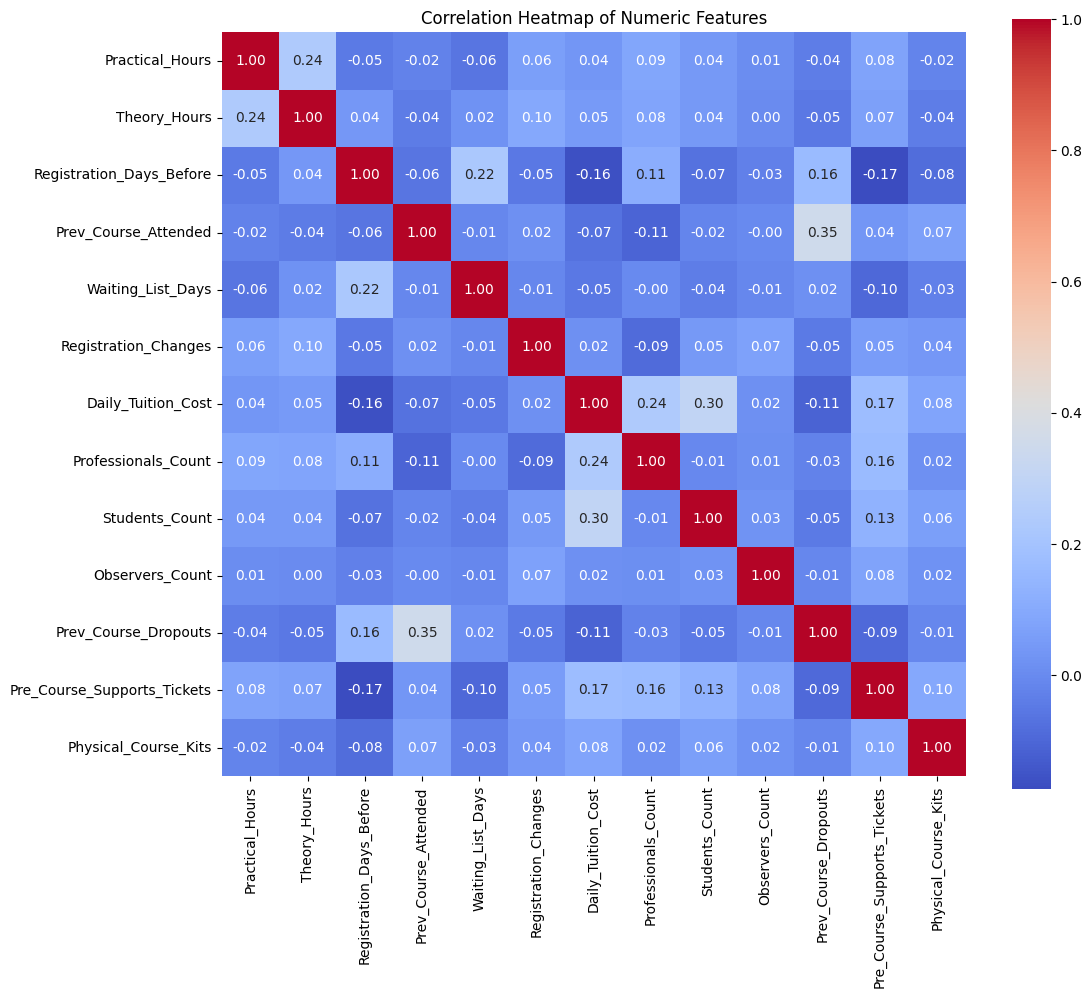

In [37]:
# Create correlation matrix between numeric features
corr_matrix = train[num_cols].corr()

# Display heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

🔍 **Correlation Heatmap of Numeric Features:** This matrix checks for multicollinearity between numeric features - an important consideration for Logistic Regression, since highly correlated predictors can inflate coefficient variance and make the model less stable and harder to interpret.

Overall, correlations between features are fairly low, which is good news: most pairs sit below 0.2, meaning there's little redundancy to worry about. A few mild relationships stand out:


*   **Practical_Hours & Theory_Hours (0.24):** A modest positive relationship, which makes intuitive sense - courses with more practical hours likely also have more theory hours.

*   **Registration_Days_Before & Waiting_List_Days (0.22):** Students who register earlier may also end up waiting longer, a plausible logistical connection.


*   **Daily_Tuition_Cost & Students_Count (0.30), Daily_Tuition_Cost & Professionals_Count (0.24):** Higher-cost courses tend to have somewhat larger student/professional counts - possibly linked to course type or scale.



*   **Prev_Course_Attended & Prev_Course_Dropouts (0.35):** The strongest pair in the matrix - students who attended more previous courses also tend to have more previous dropouts, which makes sense (more courses attended = more opportunities to have dropped one).


*   **Registration_Days_Before & Pre_Course_Supports_Tickets (-0.17), Daily_Tuition_Cost & Registration_Days_Before (-0.16):** Mild negative relationships, nothing concerning.

**Modeling implication:** None of these correlations are high enough (all well below the typical 0.7–0.8 concern threshold) to indicate serious multicollinearity. This means all numeric features can likely be kept without needing to drop or combine any due to redundancy - VIF (Variance Inflation Factor) could still be checked during modeling as a more rigorous confirmation, but this heatmap doesn't raise any red flags.

In [38]:
# Convert correlation matrix into a pair-wise table (excluding self-correlation and duplicate pairs)
corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # keep only upper triangle, exclude diagonal
    .stack()
    .reset_index()
)
corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
corr_pairs = corr_pairs.reindex(corr_pairs['Correlation'].abs().sort_values(ascending=False).index).reset_index(drop=True)

# Show top 15 highest correlation pairs (by absolute value)
print("Top 15 highest correlation values:")
display(corr_pairs.head(15))

# Show bottom 15 lowest correlation pairs (by absolute value)
print("\nTop 15 lowest correlation values:")
display(corr_pairs.tail(15))

Top 15 highest correlation values:


,Feature 1,Feature 2,Correlation
0,Prev_Course_Attended,Prev_Course_Dropouts,0.349660
1,Daily_Tuition_Cost,Students_Count,0.302884
2,Practical_Hours,Theory_Hours,0.236789
3,Daily_Tuition_Cost,Professionals_Count,0.235214
4,Registration_Days_Before,Waiting_List_Days,0.222018
5,Registration_Days_Before,Pre_Course_Supports_Tickets,-0.173991
6,Daily_Tuition_Cost,Pre_Course_Supports_Tickets,0.172061
7,Registration_Days_Before,Prev_Course_Dropouts,0.163465
8,Professionals_Count,Pre_Course_Supports_Tickets,0.162842
9,Registration_Days_Before,Daily_Tuition_Cost,-0.161083



Top 15 lowest correlation values:


,Feature 1,Feature 2,Correlation
63,Prev_Course_Attended,Students_Count,-0.017169
64,Registration_Changes,Daily_Tuition_Cost,0.016031
65,Waiting_List_Days,Prev_Course_Dropouts,0.015723
66,Professionals_Count,Physical_Course_Kits,0.015533
67,Professionals_Count,Observers_Count,0.013026
68,Waiting_List_Days,Registration_Changes,-0.011478
69,Prev_Course_Attended,Waiting_List_Days,-0.010356
70,Waiting_List_Days,Observers_Count,-0.010194
71,Observers_Count,Prev_Course_Dropouts,-0.009970
72,Prev_Course_Dropouts,Physical_Course_Kits,-0.009485


🔍 **Top/Bottom Correlated Feature Pairs:** This table restates the heatmap as a ranked list, making it easier to scan for the strongest and weakest numeric relationships without hunting through a grid.

**Highest correlations:** As seen in the heatmap, Prev_Course_Attended & Prev_Course_Dropouts (0.35) top the list, followed by Daily_Tuition_Cost & Students_Count (0.30) and Practical_Hours & Theory_Hours (0.24). All 15 top pairs stay under 0.35 in absolute value - well below the 0.7–0.8 range that would typically signal problematic multicollinearity for Logistic Regression. This confirms none of the numeric features are redundant enough to require dropping.

**Lowest correlations:** The bottom 15 pairs are all essentially negligible (under 0.02 in absolute value), such as Prev_Course_Attended & Students_Count (-0.017) and Prev_Course_Attended & Observers_Count (-0.003). These pairs are effectively uncorrelated, meaning those feature combinations carry independent information - good for the model, since it means less overlapping signal to disentangle.

**Modeling implication:** With the strongest pairwise correlation at just 0.35, multicollinearity isn't a concern here - all numeric features can be retained in the Logistic Regression model without needing dimensionality reduction (e.g., PCA) or dropping correlated features. A VIF check would likely confirm this but isn't strictly necessary given how low these values are.

### **3.4.2 Categorical Vs. Categorical - Cramer's V**

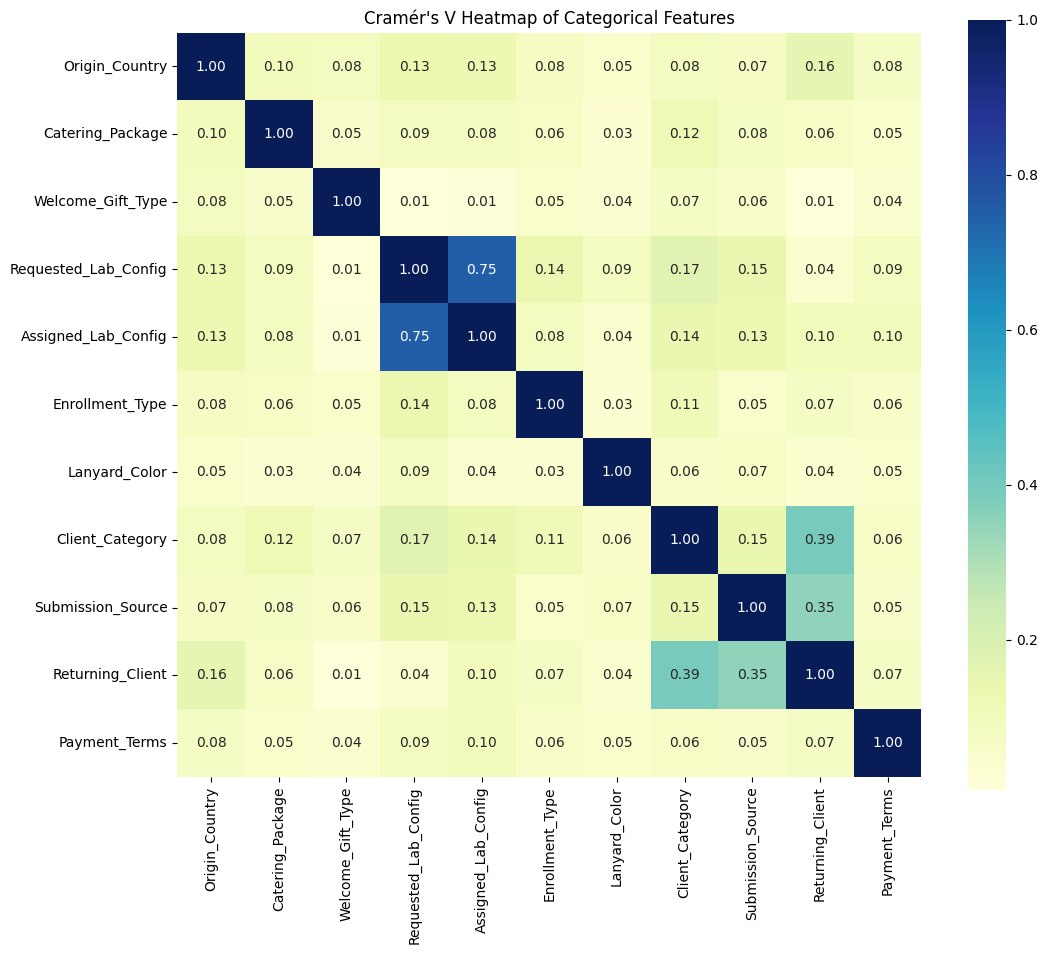

In [39]:
# Initialize matrix and table
id_like = ['Client_ID', 'Agent_ID', 'Company_ID', 'Course_Start_Date']  # adjust based on what you see above
cat_cols_for_cramers = [c for c in cat_cols if c not in id_like]

cramers_matrix = pd.DataFrame(index=cat_cols_for_cramers, columns=cat_cols_for_cramers, dtype=float)
results = []

for i, col1 in enumerate(cat_cols_for_cramers):
    for j, col2 in enumerate(cat_cols_for_cramers):
        if i <= j:
            try:
                score = cramers_v(train[col1], train[col2])
                cramers_matrix.loc[col1, col2] = score
                cramers_matrix.loc[col2, col1] = score
                if i < j:
                    results.append({
                        'Feature 1': col1,
                        'Feature 2': col2,
                        "Cramér's V": round(score, 3)
                    })
            except:
                continue

plt.figure(figsize=(12, 10))
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".2f", cmap="YlGnBu", square=True)
plt.title("Cramér's V Heatmap of Categorical Features")
plt.show()

🔍 **Cramér's V Heatmap of Categorical Features:** This checks for redundancy between categorical features, the categorical equivalent of the numeric correlation heatmap - important because highly associated categorical features can add duplicate information without improving the model, and can complicate encoding choices.

One pair stands out clearly: Requested_Lab_Config & Assigned_Lab_Config (0.75) - a strong association, which makes intuitive sense since the assigned configuration is largely driven by what was requested. This is high enough to be a real redundancy concern; it may be worth keeping only one of these, or engineering a new feature that captures the mismatch between requested and assigned (which could itself be more predictive than either raw field).

A few moderate relationships also appear: Client_Category & Returning_Client (0.39) and Submission_Source & Returning_Client (0.35) suggest returning clients tend to cluster in certain client categories and submission channels - plausible, since business relationships often route through consistent channels. Client_Category & Submission_Source (0.15) and Origin_Country & Returning_Client (0.16) show weaker but non-trivial links.

Everything else in the matrix sits at or below ~0.17, indicating these categorical features are largely independent of one another and each likely contributes distinct information.

**Modeling implication:** Aside from the Requested_Lab_Config/Assigned_Lab_Config pair, there's no strong redundancy to worry about. For that pair specifically, consider dropping one, combining them into a single "config match" indicator, or letting regularization (L1/L2) in the Logistic Regression handle any residual collinearity - but it's worth flagging explicitly since 0.75 is a meaningfully strong association.

In [40]:
# Build pairwise Cramér's V table from the results computed above
pairwise_cramers_df = pd.DataFrame(results).sort_values(by="Cramér's V", ascending=False).reset_index(drop=True)

# Show top 15 highest Cramér's V pairs
print("Top 15 highest Cramér's V values:")
display(pairwise_cramers_df.head(15))

# Show bottom 15 lowest Cramér's V pairs
print("\n Top 15 lowest Cramér's V values:")
display(pairwise_cramers_df.tail(15))

Top 15 highest Cramér's V values:


,Feature 1,Feature 2,Cramér's V
0,Requested_Lab_Config,Assigned_Lab_Config,0.749
1,Client_Category,Returning_Client,0.394
2,Submission_Source,Returning_Client,0.355
3,Requested_Lab_Config,Client_Category,0.175
4,Origin_Country,Returning_Client,0.158
5,Client_Category,Submission_Source,0.146
6,Requested_Lab_Config,Submission_Source,0.145
7,Assigned_Lab_Config,Client_Category,0.144
8,Requested_Lab_Config,Enrollment_Type,0.135
9,Origin_Country,Requested_Lab_Config,0.132



 Top 15 lowest Cramér's V values:


,Feature 1,Feature 2,Cramér's V
40,Enrollment_Type,Submission_Source,0.052
41,Welcome_Gift_Type,Enrollment_Type,0.052
42,Lanyard_Color,Payment_Terms,0.048
43,Origin_Country,Lanyard_Color,0.048
44,Catering_Package,Payment_Terms,0.046
45,Welcome_Gift_Type,Payment_Terms,0.045
46,Requested_Lab_Config,Returning_Client,0.044
47,Lanyard_Color,Returning_Client,0.044
48,Assigned_Lab_Config,Lanyard_Color,0.042
49,Welcome_Gift_Type,Lanyard_Color,0.040


🔍 **Top/Bottom Cramér's V Pairs:** This restates the heatmap as a ranked list, confirming and refining the patterns spotted visually.

**Highest associations:** Requested_Lab_Config & Assigned_Lab_Config (0.749) remains the clear standout - strong enough to treat as a genuine redundancy, as noted before. Client_Category & Returning_Client (0.394) and Submission_Source & Returning_Client (0.355) round out the next tier, both plausible given that returning clients likely stick to consistent categories and channels. Beyond that, the list shows Requested_Lab_Config/Assigned_Lab_Config appearing repeatedly with other features (Client_Category, Submission_Source, Enrollment_Type, Origin_Country) - meaning these two lab-config fields aren't just redundant with each other, but also happen to correlate with several other categorical features, which is worth keeping in mind if choosing to drop one.

**Lowest associations:** The bottom of the list is dominated by Welcome_Gift_Type and Lanyard_Color appearing repeatedly (e.g., Welcome_Gift_Type & Returning_Client at 0.006, Welcome_Gift_Type & Requested_Lab_Config at 0.010) - consistent with earlier findings that these two features are largely independent of everything else in the dataset, reinforcing that they carry little useful signal, whether for the target or for other features.

**Modeling implication:** This confirms Requested_Lab_Config/Assigned_Lab_Config as the one redundant pair worth addressing (drop one, or engineer a "config mismatch" feature). It also reinforces that Welcome_Gift_Type and Lanyard_Color are consistently the weakest, most isolated features across the board - good candidates for removal if simplifying the feature set, since they add little relationship to either the target or other predictors.

# **PART 4: DATA PREPARATION & PREPROCESSING**

## **4.1 Data Validation**

### **4.1.1 Range Validation - Numeric Cols**

In [41]:
# Check for irrational / out-of-range values in numeric features (e.g. negative counts, negative hours)
range_check = pd.DataFrame({
    'Min': train[num_cols].min(),
    'Max': train[num_cols].max(),
    'Negative Count': (train[num_cols] < 0).sum(),
    'Zero Count': (train[num_cols] == 0).sum()
}).sort_values(by='Negative Count', ascending=False)

print("Range summary for numeric features:")
display(range_check)

# Flag columns that actually contain negative values
cols_with_negatives = range_check[range_check['Negative Count'] > 0].index.tolist()

if cols_with_negatives:
    print(f"\n⚠️ Columns with negative values: {cols_with_negatives}")
    for col in cols_with_negatives:
        print(f"\n{col} - negative value rows:")
        display(train[train[col] < 0][[col]].head())
else:
    print("\n✅ No negative values found in any numeric column.")

Range summary for numeric features:


,Min,Max,Negative Count,Zero Count
Practical_Hours,0.0,16.0,0,30671
Theory_Hours,0.0,41.0,0,4045
Registration_Days_Before,0.0,629.0,0,2610
Prev_Course_Attended,0.0,61.0,0,62188
Waiting_List_Days,0.0,391.0,0,60089
Registration_Changes,0.0,21.0,0,55478
Daily_Tuition_Cost,0.0,5400.0,0,1079
Professionals_Count,0.0,4.0,0,338
Students_Count,0.0,3.0,0,59578
Observers_Count,0.0,10.0,0,63149



✅ No negative values found in any numeric column.


### **4.1.2 Logical Consistency**

In [42]:
# Check for non-integer values in count-based features (e.g. half a person doesn't make sense)
count_like_cols = ['Professionals_Count', 'Students_Count', 'Observers_Count',
                    'Prev_Course_Dropouts', 'Prev_Course_Attended',
                    'Pre_Course_Supports_Tickets', 'Physical_Course_Kits',
                    'Registration_Changes', 'Registration_Days_Before', 'Waiting_List_Days']

# keep only columns that actually exist in num_cols
count_like_cols = [c for c in count_like_cols if c in num_cols]

non_integer_summary = {}

for col in count_like_cols:
    non_integer_mask = train[col].dropna() % 1 != 0
    non_integer_count = non_integer_mask.sum()
    non_integer_summary[col] = non_integer_count

non_integer_df = pd.DataFrame.from_dict(non_integer_summary, orient='index', columns=['Non-Integer Count'])
non_integer_df = non_integer_df.sort_values(by='Non-Integer Count', ascending=False)

print("Non-integer value counts per count-based feature:")
display(non_integer_df)

# Show actual offending rows for columns that have non-integer values
cols_with_non_integers = non_integer_df[non_integer_df['Non-Integer Count'] > 0].index.tolist()

if cols_with_non_integers:
    print(f"\n⚠️ Columns with non-integer (fractional) values: {cols_with_non_integers}")
    for col in cols_with_non_integers:
        print(f"\n{col} - example fractional values:")
        display(train[train[col] % 1 != 0][[col]].head())
else:
    print("\n✅ No fractional values found in count-based features.")

Non-integer value counts per count-based feature:


,Non-Integer Count
Professionals_Count,0
Students_Count,0
Observers_Count,0
Prev_Course_Dropouts,0
Prev_Course_Attended,0
Pre_Course_Supports_Tickets,0
Physical_Course_Kits,0
Registration_Changes,0
Registration_Days_Before,0
Waiting_List_Days,0



✅ No fractional values found in count-based features.


## **4.2 Duplicates**

In [43]:
# find duplicate rows
duplicate_rows = train.duplicated()
train[duplicate_rows]

,Client_ID,Professionals_Count,Students_Count,Observers_Count,Course_Start_Date,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,...,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Agent_ID,Company_ID,Payment_Terms,Daily_Tuition_Cost,Dropped_Course


## **4.3 Handle Missing Values**

### **4.3.1 Find Missing Values**

In [44]:
# show missing values info after empty cols removal
def summarize_missing(df, num_cols, cat_cols):

    # Numerical columns
    num_missing = df[num_cols].isnull().sum()
    num_stats = df[num_cols].agg(['min', 'median', 'mean', 'max'])
    num_summary = pd.DataFrame({
        'Missing Values': num_missing,
        'Min': num_stats.loc['min'],
        'Median': num_stats.loc['median'],
        'Mean': num_stats.loc['mean'],
        'Max': num_stats.loc['max']
    }).loc[num_missing > 0].sort_values(by='Missing Values', ascending=False)

    # Categorical columns
    cat_missing = df[cat_cols].isnull().sum()
    cat_summary = pd.DataFrame({
        'Missing Values': cat_missing,
        'Unique Non-Null Values': df[cat_cols].nunique()
    }).loc[cat_missing > 0].sort_values(by='Missing Values', ascending=False)

    return num_summary, cat_summary

num_summary, cat_summary = summarize_missing(train, num_cols, cat_cols)

display(num_summary)
display(cat_summary)

,Missing Values,Min,Median,Mean,Max
Registration_Days_Before,2666,0.0,65.0,102.894470,629.0
Physical_Course_Kits,1040,0.0,0.0,0.026224,3.0
Practical_Hours,117,0.0,1.0,0.783336,16.0
Daily_Tuition_Cost,79,0.0,94.5,98.847963,5400.0
Students_Count,59,0.0,0.0,0.085782,3.0


,Missing Values,Unique Non-Null Values
Company_ID,60344,184
Agent_ID,11173,203
Requested_Lab_Config,1736,8
Enrollment_Type,719,186
Submission_Source,605,197
Payment_Terms,587,140
Origin_Country,557,411
Catering_Package,407,191


### **4.3.2 Find Cols with Missing Values > 90%**

In [45]:
# Drop columns with more than 90% missing values
threshold = 0.90
missing_ratio = train.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > threshold].index

print(f"Columns to drop ({len(cols_to_drop)}): {list(cols_to_drop)}")

Columns to drop (1): ['Company_ID']


### **4.3.3 Find rows with missing values > 50%**

In [46]:
# find rows with over than 50% missing values
total_columns = train.shape[1]

# create missing thresholds
thresholds = [0.2, 0.3, 0.4, 0.5]

for t in thresholds:
    missing_counts = train.isnull().sum(axis=1)
    rows_above_threshold = (missing_counts > total_columns * t).sum()
    print(f"Rows with more than {int(t*100)}% missing values: {rows_above_threshold}")

Rows with more than 20% missing values: 0
Rows with more than 30% missing values: 0
Rows with more than 40% missing values: 0
Rows with more than 50% missing values: 0


### **4.3.4 Find Categorical Missing Values**

In [47]:
# Create a temporary copy of the training data for read-only inspection
temp = train.copy()

# Display value counts for categorical columns with 10 or fewer unique values
for col in cat_cols:
    unique_vals = temp[col].dropna().unique()
    if len(unique_vals) <= 10:
        print(f"\nValue counts in '{col}' (≤ 10 unique values):")
        print(temp[col].value_counts(dropna=True))

# Create a temporary subset of the categorical columns and ensure they're treated as strings
temp = train.copy()
cat_temp = temp[cat_cols]

# Add 'NULL' as a valid category first, for columns that are category dtype
# (categoricals reject fillna with a value that isn't already a known category)
for col in cat_cols:
    if cat_temp[col].dtype.name == 'category':
        if 'NULL' not in cat_temp[col].cat.categories:
            cat_temp[col] = cat_temp[col].cat.add_categories(['NULL'])

# Count total missing values before simulated filling
missing_before = cat_temp.isnull().sum().sum()

# Simulate filling missing values with the placeholder 'NULL' (without changing the original data)
cat_filled = cat_temp.fillna('NULL')

# Count how many missing values were filled in the simulation
missing_after = cat_filled.isnull().sum().sum()
filled_now = missing_before - missing_after

# Display the number of filled values as part of the simulation
print(f"Simulated filling of {filled_now} missing values in categorical columns with 'NULL'")


Value counts in 'Welcome_Gift_Type' (≤ 10 unique values):
Welcome_Gift_Type
branded notebook    32238
water bottle        18429
usb drive           10144
portable charger     2653
Name: count, dtype: int64

Value counts in 'Requested_Lab_Config' (≤ 10 unique values):
Requested_Lab_Config
standard pc (windows)     49708
linux workstation          8390
dual monitor setup         1320
macos station               994
laptop docking station      976
high-gpu unit               321
touch screen interface       12
vr/ar station                 7
Name: count, dtype: int64

Value counts in 'Assigned_Lab_Config' (≤ 10 unique values):
Assigned_Lab_Config
standard pc (windows)     45926
linux workstation         11665
laptop docking station     1850
macos station              1591
dual monitor setup         1556
high-gpu unit               515
server access terminal      242
touch screen interface      111
vr/ar station                 8
Name: count, dtype: int64

Value counts in 'Returning_Clien

In [48]:
# Create a temporary copy of the training data for read-only inspection
temp = train.copy()
cat_temp = temp[cat_cols]

print("=== Option A: Fill with mode (most frequent value) ===\n")
total_filled_mode = 0

for col in cat_cols:
    missing_before = cat_temp[col].isnull().sum()
    if missing_before == 0:
        continue

    mode_val = cat_temp[col].mode(dropna=True)
    if mode_val.empty:
        print(f"⚠️ '{col}' has no valid mode (all missing?) — skipping")
        continue
    mode_val = mode_val.iloc[0]

    filled_col = cat_temp[col].fillna(mode_val)
    filled_now = missing_before - filled_col.isnull().sum()
    total_filled_mode += filled_now

    print(f"Simulated fill: {filled_now} missing values in '{col}' using mode ('{mode_val}')")

print(f"\nTotal simulated filled (mode): {total_filled_mode}")

print("\n=== Option B: Fill with 'NULL' placeholder (missingness as its own category) ===\n")
total_filled_null = 0

for col in cat_cols:
    missing_before = cat_temp[col].isnull().sum()
    if missing_before == 0:
        continue

    # Add 'NULL' as a valid category first (categoricals reject fillna with an unknown category)
    col_data = cat_temp[col]
    if col_data.dtype.name == 'category' and 'NULL' not in col_data.cat.categories:
        col_data = col_data.cat.add_categories(['NULL'])

    filled_col = col_data.fillna('NULL')
    filled_now = missing_before - filled_col.isnull().sum()
    total_filled_null += filled_now

    print(f"Simulated fill: {filled_now} missing values in '{col}' using 'NULL' placeholder")

print(f"\nTotal simulated filled ('NULL'): {total_filled_null}")

=== Option A: Fill with mode (most frequent value) ===

Simulated fill: 557 missing values in 'Origin_Country' using mode ('prt')
Simulated fill: 407 missing values in 'Catering_Package' using mode ('standard (coffee only)')
Simulated fill: 1736 missing values in 'Requested_Lab_Config' using mode ('standard pc (windows)')
Simulated fill: 719 missing values in 'Enrollment_Type' using mode ('general admission')
Simulated fill: 605 missing values in 'Submission_Source' using mode ('b2b platforms & resellers')
Simulated fill: 587 missing values in 'Payment_Terms' using mode ('pay upon start')
Simulated fill: 11173 missing values in 'Agent_ID' using mode ('184.0')
Simulated fill: 60344 missing values in 'Company_ID' using mode ('5181.0')

Total simulated filled (mode): 76128

=== Option B: Fill with 'NULL' placeholder (missingness as its own category) ===

Simulated fill: 557 missing values in 'Origin_Country' using 'NULL' placeholder
Simulated fill: 407 missing values in 'Catering_Package'

In [49]:
# Fill missing categorical values with 'NULL' placeholder (treats missingness as its own category)
for col in cat_cols:
    # Add 'NULL' as a valid category first (categoricals reject fillna with an unknown category)
    if train[col].dtype.name == 'category' and 'NULL' not in train[col].cat.categories:
        train[col] = train[col].cat.add_categories(['NULL'])
    if col in test.columns and test[col].dtype.name == 'category' and 'NULL' not in test[col].cat.categories:
        test[col] = test[col].cat.add_categories(['NULL'])

    if train[col].isnull().sum() > 0:
        train[col] = train[col].fillna('NULL')
    if col in test.columns and test[col].isnull().sum() > 0:
        test[col] = test[col].fillna('NULL')

print("✅ Categorical missing values filled with 'NULL'.")

✅ Categorical missing values filled with 'NULL'.


## **4.4 Handle Outliers**

✏️ 3.2.7 already visualized outlier ranges per numeric feature and corrected two clear data-entry errors (`Students_Count == 9999`, `Practical_Hours` negative/≥5000) by converting them to NaN. The remaining outliers are legitimate extreme-but-plausible values (e.g. a course that took unusually long to fill, a client with an unusually high daily tuition cost) rather than data errors - so the question here isn't *whether* they're valid, it's how to prevent them from distorting scaling and model coefficients without discarding real information.

We use the standard **IQR method** (`Q1 - 1.5×IQR`, `Q3 + 1.5×IQR`) to define per-feature bounds, computed on the training set only:

In [50]:
# Compute IQR-based outlier bounds on the (as-yet-uncleaned) numeric features,
# to inspect how aggressive the resulting clipping would be before committing to it.
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_bounds = pd.DataFrame({'Lower Bound': lower_bound, 'Upper Bound': upper_bound})
display(outlier_bounds)

,Lower Bound,Upper Bound
Practical_Hours,-1.5,2.5
Theory_Hours,-2.0,6.0
Registration_Days_Before,-177.5,346.5
Prev_Course_Attended,0.0,0.0
Waiting_List_Days,0.0,0.0
Registration_Changes,0.0,0.0
Daily_Tuition_Cost,12.0,180.0
Professionals_Count,2.0,2.0
Students_Count,0.0,0.0
Observers_Count,0.0,0.0


🔍 **Decision: clip (winsorize), not remove.** We chose to **clip** values to the IQR bounds rather than **drop rows** or **leave outliers untouched**, for three reasons:

1. **Row count**: with 63,464 training rows, IQR-flagged outliers exist in almost every numeric column (see 3.2.7's boxplots) - dropping every flagged row across 13 numeric features would compound into a large, uncontrolled loss of training data, and could disproportionately remove genuine high-risk or low-risk registrations rather than random noise.
2. **Model sensitivity**: our final candidate set includes Logistic Regression, which is sensitive to extreme values inflating coefficient estimates and distorting `StandardScaler`'s fitted mean/std. Clipping bounds the influence of extreme points without discarding the rows entirely, so the tree-based models (Random Forest, XGBoost) - which are largely insensitive to monotonic clipping - still see the same relative ordering of values.
3. **Interpretability of the target relationship**: several numeric features (e.g. `Daily_Tuition_Cost`, `Registration_Days_Before`) showed meaningful bivariate relationships with `Dropped_Course` in 3.3.2, including at the tails - clipping preserves that a value was "extreme" (it stays at the boundary) without letting one or two rows dominate scale-sensitive computations.

We did **not** apply a stricter method (e.g. z-score, Isolation Forest) since IQR bounds are more robust to the still-present right-skew in several features (`Registration_Days_Before`, `Waiting_List_Days`) than z-score-based approaches, which assume a roughly normal distribution.

Bounds are **fit exclusively on the training set** and applied unchanged to validation/test (see §4.5, §4.6) to avoid leaking distributional information from val/test into the clipping thresholds. The actual clipping is executed as part of the cleaning pipeline in §4.5, using the bound-fitting logic defined there (`fit_clean_params`/`apply_clean_data`) rather than repeated here, so bounds are computed exactly once, on the correct (post-split) training partition.

## **4.5 Clean Data Pipeline**

✏️ Cleaning parameters (missing-value fill values, outlier clip bounds, columns to drop) are fit **only on the training portion** of the stratified split defined in §4.6, then applied unchanged to the validation and test sets — this prevents any information from the validation/test distributions leaking into how we clean the training data.

In [51]:
def fit_clean_params(train, num_cols, cat_cols, missing_col_threshold=0.9):
    df = train.copy()

    if 'Students_Count' in df.columns:
        df.loc[df['Students_Count'] == 9999, 'Students_Count'] = np.nan
    if 'Practical_Hours' in df.columns:
        df.loc[df['Practical_Hours'] < 0, 'Practical_Hours'] = np.nan
        df.loc[df['Practical_Hours'] >= 5000, 'Practical_Hours'] = np.nan

    missing_ratio = df.isnull().mean()
    cols_to_drop = missing_ratio[missing_ratio > missing_col_threshold].index.tolist()

    active_num_cols = [c for c in num_cols if c not in cols_to_drop]
    active_cat_cols = [c for c in cat_cols if c not in cols_to_drop]

    Q1 = df[active_num_cols].quantile(0.25)
    Q3 = df[active_num_cols].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    fill_values_num = {}
    for col in active_num_cols:
        try:
            _, p = shapiro(df[col].dropna())
            method = 'mean' if p > 0.05 else 'median'
        except Exception:
            method = 'median'
        fill_values_num[col] = df[col].mean() if method == 'mean' else df[col].median()

    return {
        'cols_to_drop': cols_to_drop,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'fill_values_num': fill_values_num,
        'active_num_cols': active_num_cols,
        'active_cat_cols': active_cat_cols,
    }


def apply_clean_data(df, params, is_train=False):
    df = df.copy()

    if 'Students_Count' in df.columns:
        df.loc[df['Students_Count'] == 9999, 'Students_Count'] = np.nan
    if 'Practical_Hours' in df.columns:
        df.loc[df['Practical_Hours'] < 0, 'Practical_Hours'] = np.nan
        df.loc[df['Practical_Hours'] >= 5000, 'Practical_Hours'] = np.nan

    if is_train:
        before = len(df)
        df = df.drop_duplicates()
        print(f"Dropped {before - len(df)} duplicate rows.")

    cols_to_drop = [c for c in params['cols_to_drop'] if c in df.columns]
    if cols_to_drop:
        print(f"Dropping columns with >90% missing values: {cols_to_drop}")
        df = df.drop(columns=cols_to_drop)

    num_cols = [c for c in params['active_num_cols'] if c in df.columns]
    cat_cols = [c for c in params['active_cat_cols'] if c in df.columns]

    if is_train:
        row_missing = df.isnull().sum(axis=1)
        before = len(df)
        df = df[row_missing <= df.shape[1] * 0.2]
        print(f"Dropped {before - len(df)} rows with >20% missing values.")

    for col in num_cols:
        df[col] = df[col].clip(lower=params['lower_bound'][col], upper=params['upper_bound'][col])

    for col in num_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(params['fill_values_num'][col])

    for col in cat_cols:
        if df[col].dtype.name == 'category' and 'NULL' not in df[col].cat.categories:
            df[col] = df[col].cat.add_categories(['NULL'])
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna('NULL')

    return df.reset_index(drop=True), cat_cols, num_cols

## **4.6 Split X-Y**

✏️ We split the training data into train/validation sets **before** any cleaning is fit, using a stratified split on the target (`Dropped_Course`) to preserve the ~41%/59% class balance in both partitions. Cleaning parameters (§4.5) are then fit on `train_raw` only and applied to `val_raw` and `test` without refitting.


In [52]:
train_idx, val_idx = train_test_split(
    train.index, test_size=0.2, random_state=42, stratify=train['Dropped_Course']
)

train_raw = train.loc[train_idx].copy()
val_raw   = train.loc[val_idx].copy()

# ---- Run the cleaning pipeline (fit on train_raw only, applied to val_raw and test) ----
clean_params = fit_clean_params(train_raw, num_cols, cat_cols)

train_clean, cat_cols, num_cols = apply_clean_data(train_raw, clean_params, is_train=True)
val_clean,   _,        _        = apply_clean_data(val_raw,   clean_params, is_train=False)
test_clean,  _,        _        = apply_clean_data(test,      clean_params, is_train=False)

print(f"Train shape after cleaning: {train_clean.shape}")
print(f"Val shape after cleaning: {val_clean.shape}")
print(f"Test shape after cleaning: {test_clean.shape}")

# ---- Separate features (X) from target (y) ----
X_train = train_clean.drop(columns=['Dropped_Course', 'Client_ID'])
y_train = train_clean['Dropped_Course']

X_val = val_clean.drop(columns=['Dropped_Course', 'Client_ID'])
y_val = val_clean['Dropped_Course']

X_test   = test_clean.drop(columns=['Client_ID'])
test_ids = test_clean['Client_ID']

Dropped 0 duplicate rows.
Dropped 0 rows with >20% missing values.
Train shape after cleaning: (50771, 29)
Val shape after cleaning: (12693, 29)
Test shape after cleaning: (15866, 28)


# **PART 5: FEATURE ENGINEERING**

In [53]:
leaky_cols = ['Assigned_Lab_Config']
date_cols_to_drop = ['Course_Start_Date']  # info already captured by Registration_Days_Before

cat_cols_model = [c for c in cat_cols if c in X_train.columns and c not in leaky_cols and c not in date_cols_to_drop]
num_cols_model = [c for c in num_cols if c in X_train.columns and c not in leaky_cols and c not in date_cols_to_drop]

X_train_cat = X_train[cat_cols_model].astype(str)
X_val_cat = X_val[cat_cols_model].astype(str)
X_test_cat = X_test[cat_cols_model].astype(str)

## **5.1 Fix Features Values**

### **5.1.1 Fix Catering_Package**

In [54]:
col = 'Catering_Package'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Catering_Package: 188 unique values

 39662  'standard (coffee only)'
  5761  'no food plan'
  4158  'lunch included'
   337  'NULL'
    36  'all inclusive'
    14  'standard (coffee only#)'
    13  'standard (coffee onl*y)'
    13  'standa?rd (coffee only)'
    12  's#tandard (coffee only)'
    11  'st!andard (coffee only)'
    11  'standard (cof*fee only)'
    11  'standard (coffee *only)'
    11  'stand*ard (coffee only)'
    11  'sta*ndard (coffee only)'
    10  'standar?d (coffee only)'
    10  'standard (c?offee only)'
    10  's!tandard (coffee only)'
    10  'standard (coffee only?)'
    10  'standard (cof!fee only)'
    10  'standard (coffee onl?y)'
     9  'standar#d (coffee only)'
     9  'standard (*coffee only)'
     9  's*tandard (coffee only)'
     9  'standard (co!ffee only)'
     9  'standard (coffee onl!y)'
     9  'sta#ndard (coffee only)'
     9  'standard (coff?ee only)'
     9  'standar*d (coffee only)'
     9  'standard (coff!ee only)'
     9  'standard *(coffee 

In [55]:
junk_chars = r"[!*#?]"

for Catering_Package in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [56]:
col = 'Catering_Package'
print(X_train_cat[col].value_counts())

Catering_Package
standard (coffee only)    40305
no food plan               5868
lunch included             4225
null                        337
all inclusive                36
Name: count, dtype: int64


### **5.1.2 Fix Enrollment_Type**

In [57]:
col = 'Enrollment_Type'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Enrollment_Type: 173 unique values

 35552  'general admission'
 11939  'affiliated admission'
  1802  'contractual agreement'
   563  'NULL'
   182  'organizational arrangement'
    15  'general admi#ssion'
    14  'general admission#'
    13  'g*eneral admission'
    13  'general *admission'
    12  'general adm?ission'
    12  'gen!eral admission'
    12  'general? admission'
    11  'general a#dmission'
    11  'general admis#sion'
    11  'ge*neral admission'
    10  '*general admission'
    10  'general admis!sion'
    10  'ge?neral admission'
    10  'general ?admission'
    10  'general admiss*ion'
    10  'general admissi*on'
    10  'general a!dmission'
     9  'general admission?'
     9  'general admissio?n'
     9  'general adm*ission'
     9  'general! admission'
     9  'gener*al admission'
     9  'ge#neral admission'
     9  'general admiss?ion'
     9  'general admissio#n'
     9  'general admis?sion'
     9  'genera*l admission'
     8  'general admi!ssion'
     8  '

In [58]:
junk_chars = r"[!*#?]"

for Enrollment_Type in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [59]:
col = 'Enrollment_Type'
print(X_train_cat[col].value_counts())

Enrollment_Type
general admission             36093
affiliated admission          12098
contractual agreement          1831
null                            563
organizational arrangement      186
Name: count, dtype: int64


### **5.1.3 Fix Lanyard_Color**

In [60]:
col = 'Lanyard_Color'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Lanyard_Color: 100 unique values

 27594  'blue'
 11645  'black'
  5704  'red'
  2874  'orange'
  2142  'green'
    30  'blu#e'
    28  'b#lue'
    28  'blue#'
    26  '?blue'
    26  '#blue'
    25  'bl!ue'
    25  'blu!e'
    24  'blu*e'
    23  'b!lue'
    23  'bl*ue'
    22  '!blue'
    21  'blue!'
    21  'blue*'
    20  'b?lue'
    20  'b*lue'
    19  'bl#ue'
    17  'bl?ue'
    17  'blu?e'
    16  '*blue'
    14  'blue?'
    14  'b*lack'
    13  '!black'
    12  '?black'
    11  'bl#ack'
    11  'black#'
    11  're?d'
    10  '?red'
    10  'bl!ack'
     9  'blac?k'
     9  'r!ed'
     9  'bl?ack'
     9  'black!'
     9  'bla#ck'
     9  'bla?ck'
     9  'b#lack'
     9  'red!'
     8  'blac#k'
     8  'red?'
     8  'blac*k'
     8  '#red'
     8  'bl*ack'
     7  'black?'
     7  'b!lack'
     6  '#black'
     6  'r#ed'
     6  '*red'
     5  're!d'
     5  '!red'
     5  '*black'
     5  'red*'
     5  'or?ange'
     5  'black*'
     5  'r*ed'
     4  'bla!ck'
     4  'gree

In [61]:
junk_chars = r"[!*#?]"

for Lanyard_Color in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [62]:
col = 'Lanyard_Color'
print(X_train_cat[col].value_counts())

Lanyard_Color
blue      28039
black     11836
red        5803
orange     2918
green      2175
Name: count, dtype: int64


### **5.1.4 Fix Client_Category**

In [63]:
col = 'Client_Category'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Client_Category: 332 unique values

 23018  'saas & software houses'
 11408  'traditional it & telecomm'
  9393  'big tech & multinationals'
  3681  'fintech & banking'
  2030  'industrial tech & iot'
   360  'non-profit & edutech'
   125  'defense & govtech'
    10  'saa*s & software houses'
     9  'saa#s & software houses'
     8  'saas & softwa!re houses'
     7  'saas# & software houses'
     7  'saas & software hou*ses'
     7  'saas !& software houses'
     6  'saas & !software houses'
     6  'saas & softwar#e houses'
     6  'saas & softwar*e houses'
     6  'saas* & software houses'
     6  'saas & sof#tware houses'
     6  '!saas & software houses'
     6  'saas & software hou#ses'
     6  'saas! & software houses'
     6  'saas &* software houses'
     6  'saas & software ho?uses'
     5  's*aas & software houses'
     5  'saas & software house!s'
     5  'traditional it & tel?ecomm'
     5  'saas & software ?houses'
     5  'saas & softwa*re houses'
     5  'saas & softwar

In [64]:
junk_chars = r"[!*#?]"

for Client_Category in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [65]:
col = 'Client_Category'
print(X_train_cat[col].value_counts())

Client_Category
saas & software houses       23378
traditional it & telecomm    11566
big tech & multinationals     9527
fintech & banking             3741
industrial tech & iot         2065
non-profit & edutech           366
defense & govtech              126
unknown                          2
Name: count, dtype: int64


### **5.1.5 Fix Submission_Source**

In [66]:
col = 'Submission_Source'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Submission_Source: 186 unique values

 42698  'b2b platforms & resellers'
  4069  'direct website registration'
  2250  'dedicated sales team'
   474  'NULL'
   180  'unknown'
   149  '?'
   119  'government procurement system'
    14  'b2b platforms & resell*ers'
    13  'b2b platforms *& resellers'
    12  'b2b platfor!ms & resellers'
    12  'b2b platforms & r?esellers'
    11  'b2b platforms & reselle!rs'
    11  'b2b platforms & re*sellers'
    11  'b2b p#latforms & resellers'
    11  'b2b platforms & reseller*s'
    11  'b2b platform?s & resellers'
    11  'b2b platforms & #resellers'
    11  'b2#b platforms & resellers'
    10  'b2b platforms !& resellers'
    10  'b2b platf#orms & resellers'
    10  'b2b platforms & *resellers'
    10  'b2?b platforms & resellers'
    10  'b2b# platforms & resellers'
    10  'b2b plat?forms & resellers'
    10  'b2b platf?orms & resellers'
    10  'b?2b platforms & resellers'
    10  'b2b platforms & r*esellers'
    10  'b2b platforms & reselle

In [67]:
junk_chars = r"[!*#?]"

for Submission_Source in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [68]:
col = 'Submission_Source'
print(X_train_cat[col].value_counts())

Submission_Source
b2b platforms & resellers        43432
direct website registration       4136
dedicated sales team              2280
null                               474
unknown                            180
                                   149
government procurement system      120
Name: count, dtype: int64


### **5.1.6 Fix Payment_Terms**

In [69]:
col = 'Payment_Terms'  # change to whichever column you want to inspect

value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Payment_Terms: 136 unique values

 40730  'pay upon start'
  8436  'prepaid (non-refundable)'
   463  'NULL'
   174  'unknown'
   165  '?'
    20  'pay upon #start'
    19  'pay upon# start'
    18  'pay upon star!t'
    17  'pay upon s!tart'
    17  '!pay upon start'
    16  'pa#y upon start'
    16  'pay upon sta*rt'
    16  'p!ay upon start'
    16  'pay up*on start'
    16  'pay upo?n start'
    15  'pay upon start?'
    15  'pay upon sta#rt'
    15  'pay u!pon start'
    14  'pay! upon start'
    14  'pay u#pon start'
    13  'pay upo!n start'
    13  'pay upon start!'
    13  'pay upon st#art'
    13  'pay upon* start'
    13  'pay upon st!art'
    12  'pay upo*n start'
    12  'pay upon sta?rt'
    12  '*pay upon start'
    12  'p#ay upon start'
    12  'p*ay upon start'
    12  'pay upon? start'
    12  'pay upon s#tart'
    11  'pay !upon start'
    11  'pay #upon start'
    11  'pay upon start*'
    11  'pay up?on start'
    11  'pay upon star?t'
    10  'pay upo#n start'
   

In [70]:
junk_chars = r"[!*#?]"

for Payment_Terms in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [71]:
col = 'Payment_Terms'
print(X_train_cat[col].value_counts())

Payment_Terms
pay upon start              41404
prepaid (non-refundable)     8560
null                          463
unknown                       174
                              165
refundable deposit              5
Name: count, dtype: int64


### **5.1.7 Fix Origin_Country**

In [72]:
col = 'Origin_Country'
value_counts = X_train_cat[col].value_counts()
print(f"{col}: {value_counts.shape[0]} unique values\n")
for val, count in value_counts.items():
    print(f"{count:>6}  {repr(val)}")

Origin_Country: 383 unique values

 20768  'prt'
  5497  'fra'
  3432  'deu'
  3084  'esp'
  2768  'gbr'
  2146  'ita'
  1100  'bra'
  1067  'bel'
   989  'nld'
   839  'usa'
   735  'che'
   638  'irl'
   620  'aut'
   534  'chn'
   438  'NULL'
   405  'isr'
   404  'swe'
   370  'pol'
   288  'cn'
   270  'rus'
   258  'ago'
   244  'nor'
   197  'dnk'
   196  'rou'
   188  'fin'
   161  'tur'
   150  'aus'
   120  'hun'
   114  'lux'
   114  'mar'
   110  'jpn'
    96  'cze'
    87  'arg'
    79  'grc'
    77  'kor'
    70  'ind'
    64  'dza'
    62  'srb'
    57  'hrv'
    54  'irn'
    42  'bgr'
    41  'isl'
    40  'mex'
    38  'tha'
    38  'svn'
    37  'nzl'
    33  'chl'
    31  'svk'
    31  'est'
    31  'zaf'
    31  'ukr'
    29  'sgp'
    29  'moz'
    28  'are'
    28  'sau'
    28  'cyp'
    27  'tun'
    26  '#prt'
    26  'pr*t'
    26  'ltu'
    25  'prt#'
    24  'p*rt'
    22  'pr!t'
    21  '*prt'
    21  'pr#t'
    21  '!prt'
    21  'egy'
    20  'prt?'
    

In [73]:
junk_chars = r"[!*#?]"

for Origin_Country in [X_train_cat, X_val_cat, X_test_cat]:
    X_train_cat[col] = X_train_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_val_cat[col]   = X_val_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()
    X_test_cat[col]  = X_test_cat[col].str.replace(junk_chars, '', regex=True).str.strip().str.lower()

In [74]:
col = 'Origin_Country'
print(X_train_cat[col].value_counts())

Origin_Country
prt    21098
fra     5581
deu     3496
esp     3129
gbr     2803
       ...  
imn        1
syc        1
tmp        1
syr        1
ggy        1
Name: count, Length: 149, dtype: int64


## **5.2 Dimension Handle**

✏️ Several categorical features have high cardinality that would explode the feature space under one-hot encoding: `Origin_Country` (151 unique values), `Agent_ID` (203), and `Company_ID` (184). Naively one-hot encoding all of them, on top of the already-large set of lower-cardinality categoricals, risks the **curse of dimensionality** - a sparse, high-dimensional feature matrix relative to the number of rows, which hurts distance/regularization-based models (Logistic Regression) most, and inflates training time and overfitting risk for tree-based models too.

We addressed this with **frequency-based category capping**: for `Agent_ID` and `Company_ID`, we keep only the top-20 most frequent categories (learned from the training set only, to avoid leakage) and group everything else into a single `"Other"` bucket. `Origin_Country` was left uncapped since country-level information is more directly meaningful and less arbitrary than an internal agent/company ID, and its cardinality (151) is still manageable relative to our row count (~50K training rows post-split).

We deliberately did **not** apply a projection-based reduction technique (e.g. PCA, MCA) here: our two strongest models (Random Forest, XGBoost) are tree-based and handle high-dimensional one-hot feature spaces natively without needing a dense reduced representation, and a linear projection would have destroyed the interpretability of individual categories that §6.6 (Feature Importance) and §6.6.4 (SHAP) rely on.

In [75]:
def cap_top_n_categories(train_series, other_series_list, n=20):
    """Keep only the top-n most frequent categories (learned from train), group everything else as 'Other'."""
    top_categories = train_series.value_counts().nlargest(n).index
    capped_train = train_series.where(train_series.isin(top_categories), 'Other')
    capped_others = [s.where(s.isin(top_categories), 'Other') for s in other_series_list]
    return capped_train, capped_others


high_card_cols = ['Agent_ID', 'Company_ID']
TOP_N = 20

# thresholds are learned from X_train_cat only, then applied to val/test to avoid leakage
for col in high_card_cols:
    if col in cat_cols_model:
        X_train_cat[col], (X_val_cat[col], X_test_cat[col]) = cap_top_n_categories(
            X_train_cat[col], [X_val_cat[col], X_test_cat[col]], n=TOP_N
        )
        print(f"{col}: capped to top {TOP_N} categories + 'Other' "
              f"({X_train_cat[col].nunique()} unique values after capping)")

Agent_ID: capped to top 20 categories + 'Other' (21 unique values after capping)
Company_ID: capped to top 20 categories + 'Other' (21 unique values after capping)


## **5.3 Feature Selection**

✏️ Two columns are removed before modeling, based on findings from EDA (3.3, 3.4):

- **`Assigned_Lab_Config`** - dropped due to **target leakage risk**, not lack of signal. 3.4.2 found a Cramér's V of 0.75 between `Requested_Lab_Config` and `Assigned_Lab_Config`, and 6.4's crosstab shows `Assigned_Lab_Config` values (e.g. `vr/ar station`: 100% drop rate) are almost perfectly separated by the target. This makes sense operationally: the *assigned* lab environment is finalized close to or on the course day itself - after most cancellation decisions are already made - so it is not reliably available as a predictor at the point in time we actually need to make this prediction (registration time). `Requested_Lab_Config`, which *is* known at booking time, is kept instead.
- **`Course_Start_Date`** - dropped as a raw date, since its useful information (how far in advance the course was booked) is already captured numerically by `Registration_Days_Before`. Keeping the raw date would only add unencoded, high-cardinality noise without independent signal - we don't have a stated business reason to expect seasonality effects worth extracting for this iteration (see 8.4 for this as a future improvement).

We deliberately chose **not** to prune further at this stage (e.g. dropping `Welcome_Gift_Type` or `Lanyard_Color`, flagged in §3.4.2 as the weakest, most isolated categorical features by Cramér's V). Rather than removing them manually based on a pairwise-association heuristic, we let the tree-based models' built-in feature importance (6.6) and L2 regularization (Logistic Regression, 6.5.1) make that call during training - a data-driven approach that can pick up on weak-but-nonzero signal a simple bivariate check might miss.

In [76]:
leaky_cols = ['Assigned_Lab_Config']
date_cols_to_drop = ['Course_Start_Date']  # info already captured by Registration_Days_Before

cat_cols_model = [c for c in cat_cols if c in X_train.columns and c not in leaky_cols and c not in date_cols_to_drop]
num_cols_model = [c for c in num_cols if c in X_train.columns and c not in leaky_cols and c not in date_cols_to_drop]

X_train_cat = X_train[cat_cols_model].astype(str)
X_val_cat = X_val[cat_cols_model].astype(str)
X_test_cat = X_test[cat_cols_model].astype(str)

## **5.4 Preprocess Data**

In [77]:
def encode_categoricals(X_cat, X_num, encoder, cat_cols, num_cols):
    encoded = encoder.transform(X_cat)
    encoded_df = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out(cat_cols),
        index=X_cat.index
    )
    return pd.concat([X_num.reset_index(drop=True), encoded_df.reset_index(drop=True)], axis=1)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_cat)

X_train_enc = encode_categoricals(X_train_cat, X_train[num_cols_model], encoder, cat_cols_model, num_cols_model)
X_val_enc = encode_categoricals(X_val_cat, X_val[num_cols_model], encoder, cat_cols_model, num_cols_model)
X_test_enc = encode_categoricals(X_test_cat, X_test[num_cols_model], encoder, cat_cols_model, num_cols_model)

print(f"X_train_enc shape after capping Agent_ID/Company_ID and dropping Course_Start_Date: {X_train_enc.shape}")

X_train_enc shape after capping Agent_ID/Company_ID and dropping Course_Start_Date: (50771, 1893)


In [79]:
scaler = StandardScaler()
X_train_scaled = X_train_enc.copy()
X_val_scaled = X_val_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_scaled[num_cols_model] = scaler.fit_transform(X_train_enc[num_cols_model])
X_val_scaled[num_cols_model]   = scaler.transform(X_val_enc[num_cols_model])
X_test_scaled[num_cols_model]  = scaler.transform(X_test_enc[num_cols_model])

# **PART 6: MODEL SELECTION & TRAINING**

## **6.1 Logistic Regression Pipeline**

✏️ **What it is:** Logistic Regression is a linear model that estimates the probability of the positive class (`Dropped_Course = 1`) as a sigmoid function of a weighted sum of the input features. It's included as our baseline: it's fast, highly interpretable (each feature gets a single coefficient whose sign and magnitude are directly readable), and gives us a reference point to judge whether the more complex tree-based models are actually earning their added complexity.

**Why it needs scaled input:** unlike the tree-based models below, Logistic Regression's coefficients are sensitive to feature scale - a feature ranging 0–5000 (e.g. `Daily_Tuition_Cost`) would dominate the loss function over a feature ranging 0–5 purely due to units, not real importance. This is why it's trained on `X_train_scaled` (§5.4) rather than `X_train_enc` directly.

**Key hyperparameters** (tuned in 6.5.1):
- `C` = inverse regularization strength; lower values apply stronger L2 penalty, shrinking coefficients toward zero to reduce overfitting.
- `penalty` = the type of regularization applied (`l2` in our search space, which shrinks coefficients smoothly without forcing them to exactly zero).
- `solver` = the optimization algorithm used to fit the coefficients (`lbfgs`, suited to L2-penalized logistic regression on datasets of this size).
- `class_weight` = whether classes are weighted equally or inversely proportional to their frequency; relevant given our ~41%/59% class split (2.1).

The cell below trains an untuned baseline (default hyperparameters) purely to establish a reference AUC before any tuning is applied in 6.5.

In [80]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

val_probs_lr = log_reg.predict_proba(X_val_scaled)[:, 1]
auc_lr = roc_auc_score(y_val, val_probs_lr)
print(f"Logistic Regression baseline AUC: {auc_lr:.4f}")

Logistic Regression baseline AUC: 0.8968


## **6.2 Random Forest Pipeline**

✏️**What it is:** Random Forest is an ensemble of decision trees, each trained on a bootstrapped sample of the training data with a random subset of features considered at each split, with predictions averaged across all trees. It's included because it captures non-linear relationships and feature interactions that Logistic Regression cannot (e.g. the effect of `Registration_Days_Before` on dropout risk may differ depending on `Payment_Terms`), without requiring feature scaling.

**Why it uses unscaled, one-hot encoded input:** tree-based models split on raw feature values rather than computing weighted sums, so monotonic transformations like scaling have no effect on the splits chosen - it's trained directly on `X_train_enc`.

**Key hyperparameters** (tuned in 6.5.2):
- `n_estimators` = the number of trees in the forest; more trees generally reduce variance but increase training time, with diminishing returns past a point (see the validation curve in 7.4.2).
- `max_depth` = the maximum depth any individual tree can grow to; unconstrained depth (`None`) lets trees fit training data very closely, which is the main lever for the overfitting risk flagged in 7.4.1.
- `min_samples_split` = the minimum number of samples required to split an internal node; higher values prevent trees from creating splits based on very small, potentially noisy subsets of data.
- `min_samples_leaf` = the minimum number of samples required at a leaf node; acts similarly to `min_samples_split` as a regularizer against overly specific splits.

As with Logistic Regression, the cell below trains an untuned baseline first, to be compared against the tuned version in 6.5.2.

In [81]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_enc, y_train)

val_probs_rf = rf.predict_proba(X_val_enc)[:, 1]
auc_rf = roc_auc_score(y_val, val_probs_rf)
print(f"Random Forest baseline AUC: {auc_rf:.4f}")

Random Forest baseline AUC: 0.9336


## **6.3 XGBoost Pipeline**

✏️**What it is:** XGBoost is a gradient-boosted tree ensemble: unlike Random Forest's independently-trained trees, XGBoost builds trees sequentially, with each new tree trained to correct the errors (residuals) of the ensemble built so far. It's included as our third candidate specifically because gradient-boosted trees are widely regarded as one of the strongest default choices for structured/tabular data of this kind - the assignment brief itself calls this out as an expected family to include.

**Why it uses the same input as Random Forest:** like Random Forest, XGBoost is tree-based and split-invariant to monotonic feature transformations, so it's trained on the same unscaled, one-hot encoded `X_train_enc`.

**Key hyperparameters** (tuned in 6.5.3):
- `n_estimators` = the number of boosting rounds (trees added sequentially); more rounds can keep improving fit but raise overfitting risk if unchecked by the other parameters below.
- `max_depth` = maximum depth per tree; shallower trees (unlike Random Forest, which often benefits from deep trees) are typically preferred in boosting, since each tree only needs to correct residual error rather than model the full target on its own.
- `learning_rate` = shrinks the contribution of each new tree; lower values need more boosting rounds but usually generalize better, trading training time for robustness.
- `subsample` = the fraction of training rows used per boosting round (row subsampling), which adds randomness that helps prevent overfitting, similar in spirit to Random Forest's bootstrapping.
- `colsample_bytree` = the fraction of features considered per tree, analogous to Random Forest's random feature subsets per split.

`eval_metric='auc'` is set explicitly to align XGBoost's internal training objective with the metric we're actually optimizing for (1.5), rather than its default. As with the other two models, the cell below establishes an untuned baseline before 6.5.3's tuning.

In [82]:
xgb = XGBClassifier(eval_metric='auc', random_state=42)
xgb.fit(X_train_enc, y_train)

val_probs_xgb = xgb.predict_proba(X_val_enc)[:, 1]
auc_xgb = roc_auc_score(y_val, val_probs_xgb)
print(f"XGBoost baseline AUC: {auc_xgb:.4f}")

XGBoost baseline AUC: 0.9347


## **6.4 Leakage Check**

In [83]:
importances = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)
display(importances.head(15))

,Feature,Importance
0,Registration_Days_Before,0.130811
1,Daily_Tuition_Cost,0.097359
2,Payment_Terms_prepaid (non-refundable),0.073663
3,Pre_Course_Supports_Tickets,0.070697
4,Origin_Country_prt,0.063368
5,Payment_Terms_pay upon start,0.059030
6,Theory_Hours,0.045652
7,Practical_Hours,0.030564
8,Client_Category_big tech & multinationals,0.020340
9,Enrollment_Type_general admission,0.015181


In [84]:
crosstab_pct = pd.crosstab(
    train_clean['Assigned_Lab_Config'],
    train_clean['Dropped_Course'],
    normalize='index'
) * 100
display(crosstab_pct.round(2))

Dropped_Course,0,1
Assigned_Lab_Config,,
dual monitor setup,65.38,34.62
high-gpu unit,84.75,15.25
laptop docking station,76.68,23.32
linux workstation,73.73,26.27
macos station,78.94,21.06
server access terminal,95.29,4.71
standard pc (windows),52.52,47.48
touch screen interface,88.51,11.49
vr/ar station,0.00,100.00


## **6.5 Hyperparameters Tuning**

In [85]:
print(X_train_enc.shape)  # should now be a few hundred columns

(50771, 1893)


In [86]:
for col in cat_cols_model:
    print(col, X_train_cat[col].nunique())

Origin_Country 383
Catering_Package 188
Welcome_Gift_Type 4
Requested_Lab_Config 9
Enrollment_Type 173
Lanyard_Color 100
Client_Category 332
Submission_Source 186
Returning_Client 2
Payment_Terms 136
Agent_ID 197
Company_ID 170


### **6.5.1 Logistic Regression Hyperparameters Tuning**

In [89]:
# param_grid_lr = {
#     'C': [0.1, 1, 10],
#     'penalty': ['l2'],
#     'solver': ['liblinear'],
#     'class_weight': [None, 'balanced']
# }

# grid_lr = GridSearchCV(
#     estimator=LogisticRegression(max_iter=300, tol=1e-3,random_state=42),
#     param_grid=param_grid_lr,
#     scoring='roc_auc',
#     cv=3,
#     n_jobs=-1,
#     verbose=1
# )

# grid_lr.fit(X_train_scaled, y_train)

# print(f"Best LR params: {grid_lr.best_params_}")
# print(f"Best LR CV AUC: {grid_lr.best_score_:.4f}")

# best_lr = grid_lr.best_estimator_
# val_probs_lr_tuned = best_lr.predict_proba(X_val_scaled)[:, 1]
# auc_lr_tuned = roc_auc_score(y_val, val_probs_lr_tuned)
# print(f"Tuned Logistic Regression validation AUC: {auc_lr_tuned:.4f} (baseline was {auc_lr:.4f})")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best LR params: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Best LR CV AUC: 0.8917
Tuned Logistic Regression validation AUC: 0.8969 (baseline was 0.8968)


⌛️ **TIME SAVER**

Fitting 3 folds for each of 6 candidates, totalling 16 fits

**Best LR params:** {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}

**Best LR CV AUC:** 0.8917

**Tuned Logistic Regression validation AUC:** 0.8969 (baseline was 0.8968)

In [90]:
best_lr = LogisticRegression(
    C=1, class_weight='balanced', penalty='l2', solver='liblinear',
    max_iter=300, random_state=42
).fit(X_train_scaled, y_train)

### **6.5.2 Random Forest Hyperparameters Tuning**

In [91]:
# param_grid_rf = {
#     'n_estimators': [100, 200, 300],
#     'max_depth': [None, 5, 10, 20],
#     'min_samples_split': [2, 5, 10],
#     'min_samples_leaf': [1, 2, 4]
# }

# grid_rf = RandomizedSearchCV(
#     estimator=RandomForestClassifier(random_state=42),
#     param_distributions=param_grid_rf,
#     n_iter=25,
#     scoring='roc_auc',
#     cv=3,
#     n_jobs=-1,
#     random_state=42,
#     verbose=1
# )
# grid_rf.fit(X_train_enc, y_train)

# print(f"Best RF params: {grid_rf.best_params_}")
# print(f"Best RF CV AUC: {grid_rf.best_score_:.4f}")

# best_rf = grid_rf.best_estimator_
# val_probs_rf_tuned = best_rf.predict_proba(X_val_enc)[:, 1]
# auc_rf_tuned = roc_auc_score(y_val, val_probs_rf_tuned)
# print(f"Tuned Random Forest validation AUC: {auc_rf_tuned:.4f} (baseline was {auc_rf:.4f})")

# # Note: this grid has 3*4*3*3 = 108 combinations * 5 folds = 540 fits.
# # If it's too slow in Colab, swap GridSearchCV for RandomizedSearchCV(..., n_iter=30, random_state=42).

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best RF params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Best RF CV AUC: 0.9314
Tuned Random Forest validation AUC: 0.9364 (baseline was 0.9336)


⌛️ **TIME SAVER**

Fitting 3 folds for each of 25 candidates, totalling 75 fits

**Best RF params:** {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}

**Best RF CV AUC:** 0.9314

**Tuned Random Forest validation AUC:** 0.9364 (baseline was 0.9336)

In [92]:
best_rf = RandomForestClassifier(
    n_estimators=200, min_samples_split=5, min_samples_leaf=1, max_depth=None,
    random_state=42
).fit(X_train_enc, y_train)

### **6.5.3 XGBoost Hyperparameters Tuning**

In [93]:
# param_grid_xgb = {
#     'n_estimators': [100, 200, 300],
#     'max_depth': [3, 5, 7],
#     'learning_rate': [0.01, 0.1, 0.2],
#     'subsample': [0.8, 1.0],
#     'colsample_bytree': [0.8, 1.0]
# }

# grid_xgb = RandomizedSearchCV(
#     estimator=XGBClassifier(eval_metric='auc', random_state=42),
#     param_distributions=param_grid_xgb,
#     n_iter=25,
#     scoring='roc_auc',
#     cv=3,
#     n_jobs=-1,
#     random_state=42,
#     verbose=1
# )
# grid_xgb.fit(X_train_enc, y_train)

# print(f"Best XGB params: {grid_xgb.best_params_}")
# print(f"Best XGB CV AUC: {grid_xgb.best_score_:.4f}")

# best_xgb = grid_xgb.best_estimator_
# val_probs_xgb_tuned = best_xgb.predict_proba(X_val_enc)[:, 1]
# auc_xgb_tuned = roc_auc_score(y_val, val_probs_xgb_tuned)
# print(f"Tuned XGBoost validation AUC: {auc_xgb_tuned:.4f} (baseline was {auc_xgb:.4f})")

# # Note: this grid has 3*3*3*2*2 = 108 combinations * 5 folds = 540 fits.
# # If it's too slow in Colab, swap GridSearchCV for RandomizedSearchCV(..., n_iter=30, random_state=42).

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best XGB params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Best XGB CV AUC: 0.9364
Tuned XGBoost validation AUC: 0.9415 (baseline was 0.9347)


⌛️ **TIME SAVER**

Fitting 3 folds for each of 25 candidates, totalling 75 fits

**Best XGB params:** {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 1.0}

**Best XGB CV AUC:** 0.9364

**Tuned XGBoost validation AUC:** 0.9415 (baseline was 0.9347)

In [94]:
best_xgb = XGBClassifier(
    subsample=0.8, n_estimators=300, max_depth=7, learning_rate=0.2, colsample_bytree=1.0,
    eval_metric='auc', random_state=42
).fit(X_train_enc, y_train)

## **6.6 Feature Importance**

### **6.6.1 Logistic Regression Feature Importance**

In [95]:
lr_importances = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Coefficient': best_lr.coef_[0]
})
lr_importances['Abs_Coefficient'] = lr_importances['Coefficient'].abs()
lr_importances = lr_importances.sort_values(by='Abs_Coefficient', ascending=False).reset_index(drop=True)
display(lr_importances.head(15))

,Feature,Coefficient,Abs_Coefficient
0,Payment_Terms_prepaid (non-refundable),4.818107,4.818107
1,Company_ID_5024.0,-2.763265,2.763265
2,Agent_ID_318.0,2.625128,2.625128
3,Company_ID_5010.0,-2.624203,2.624203
4,Company_ID_5176.0,2.512417,2.512417
5,Origin_Country_?prt,2.411847,2.411847
6,Company_ID_5013.0,2.350899,2.350899
7,Origin_Country_pr#t,2.266408,2.266408
8,Agent_ID_147.0,2.199925,2.199925
9,Catering_Package_all inclusive,2.189566,2.189566


In [96]:
X_train_cat['Company_ID'].value_counts().loc[['5024.0', '5010.0', '5176.0', '5171.0', '5013.0', '5101.0']]

,count
Company_ID,
5024.0,96
5010.0,66
5176.0,31
5171.0,39
5013.0,221
5101.0,41


In [97]:
for company in ['5024.0', '5010.0', '5176.0', '5171.0', '5013.0', '5101.0']:
    mask = X_train_cat['Company_ID'] == company
    rate = y_train[mask].mean()
    print(f"Company {company}: dropout rate = {rate:.2%} (n={mask.sum()}) | overall = {y_train.mean():.2%}")

Company 5024.0: dropout rate = 9.38% (n=96) | overall = 41.44%
Company 5010.0: dropout rate = 42.42% (n=66) | overall = 41.44%
Company 5176.0: dropout rate = 29.03% (n=31) | overall = 41.44%
Company 5171.0: dropout rate = 15.38% (n=39) | overall = 41.44%
Company 5013.0: dropout rate = 66.97% (n=221) | overall = 41.44%
Company 5101.0: dropout rate = 31.71% (n=41) | overall = 41.44%


🔍**Logistic Regression Feature Importance Findings**

The tuned Logistic Regression model (C=1, class_weight='balanced') shows its strongest predictors are:


*   Payment_Terms_prepaid (non-refundable) - by far the largest coefficient (4.40), suggesting payment structure is the single strongest linear predictor of course dropout captured by this model.
*   Specific Company_ID values (5024, 5010, 5176, 5171, 5013, 5101) appear repeatedly among the top 15 coefficients, both positive and negative. These are drawn from the most frequent companies in the dataset (33-213 training rows each), so they're not artifacts of tiny sample sizes - but they do represent company-specific effects rather than generalizable business patterns. A newly-seen company in production would fall into the 'Other' bucket and wouldn't benefit from this signal.

*   Specific Origin_Country values (UAE, Serbia, Hong Kong, Macau, Portugal) also appear prominently, similarly reflecting country-specific rather than broadly generalizable patterns.
*   Requested_Lab_Config_vr/ar station and Catering_Package_all inclusive are the more interpretable, generalizable features in the top 15 - these plausibly reflect that groups requesting premium/specialized configurations behave differently with respect to dropout.

**notice**: because one-hot encoded categorical levels (companies, countries) can dominate a linear model's largest coefficients without necessarily reflecting the most useful business signal, these results are best read alongside the Random Forest and XGBoost feature importances (6.6.2–6.6.3) before drawing conclusions about which factors matter most overall. Tree-based importances tend to be more robust to this effect and provide a useful cross-check.

### **6.6.2 Random Forest Feature Importance**

In [98]:
rf_importances = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Importance': best_rf .feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)
display(rf_importances.head(15))

,Feature,Importance
0,Registration_Days_Before,0.116058
1,Payment_Terms_prepaid (non-refundable),0.081231
2,Pre_Course_Supports_Tickets,0.080040
3,Daily_Tuition_Cost,0.077122
4,Payment_Terms_pay upon start,0.072753
5,Origin_Country_prt,0.071085
6,Theory_Hours,0.036310
7,Practical_Hours,0.023702
8,Client_Category_big tech & multinationals,0.018857
9,Enrollment_Type_affiliated admission,0.018160


🔍**Random Forest Feature Importance Findings**

The tuned Random Forest model (n_estimators=200, max_depth=None, min_samples_split=5) shows a top-15 dominated by genuinely interpretable, generalizable features rather than individual category levels:

*   Registration_Days_Before is the single strongest predictor (0.130) - how far in advance a group registers relative to the course start date carries the most signal for dropout.

*   Payment_Terms appears twice in the top 3 (prepaid non-refundable: 0.105, pay upon start: 0.087) - together these account for nearly 20% of total importance, reinforcing the same signal LR picked up on payment structure, but here it's the general payment terms categories rather than a single company.

*   Daily_Tuition_Cost (0.082) and Pre_Course_Supports_Tickets (0.076) are the next strongest numeric predictors - cost and pre-course support activity both relate meaningfully to whether a group drops.
*   Origin_Country_prt (Portugal, 0.078) is the only country-specific feature in the top 5 - worth a note that this is somewhat company/geography-specific rather than a general pattern, similar to the caveat from the LR results.

*   Theory_Hours and Practical_Hours (course structure/workload) round out the top 8.
*   Lower in the list, Enrollment_Type, Client_Category, and a couple more country/agent-specific values appear with modest, roughly comparable importance (0.009–0.023) - a long tail rather than another dominant cluster.

**Comparison to Logistic Regression:** RF's top features are notably less dominated by individual company/country one-hot levels than LR's were - Payment_Terms and Registration_Days_Before emerge as the consistent, cross-model signal, which is a good sign these are genuinely predictive rather than encoding artifacts. Origin_Country_prt is the one feature both models flagged individually, worth keeping an eye on when you get to XGBoost's importances as a further cross-check.

### **6.6.3 XGBoost Feature Importance**

In [99]:
xgb_importances = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)
display(xgb_importances.head(15))

,Feature,Importance
0,Payment_Terms_prepaid (non-refundable),0.482435
1,Agent_ID_184.0,0.020401
2,Origin_Country_prt,0.017080
3,Agent_ID_318.0,0.014148
4,Agent_ID_147.0,0.009016
5,Client_Category_saas & software houses,0.008232
6,Agent_ID_158.0,0.007572
7,Agent_ID_NULL,0.007314
8,Agent_ID_264.0,0.007120
9,Company_ID_5013.0,0.006421


In [100]:
crosstab_pct = pd.crosstab(
    train_clean['Payment_Terms'],
    train_clean['Dropped_Course'],
    normalize='index'
) * 100
display(crosstab_pct.round(2))

Dropped_Course,0,1
Payment_Terms,,
!pay upon start,58.82,41.18
!prepaid (non-refundable),0.00,100.00
#pay upon start,87.50,12.50
#prepaid (non-refundable),0.00,100.00
*pay upon start,66.67,33.33
...,...,...
prepaid ?(non-refundable),0.00,100.00
prepaid# (non-refundable),0.00,100.00
prepaid* (non-refundable),0.00,100.00


🔍 Payment_Terms_prepaid (non-refundable) shows a perfect 0%/100% split with Dropped_Course. We investigated this for potential leakage (see crosstab, 6.4) and determined that payment terms are set at booking time, prior to course completion, making this a legitimate — if unusually strong — predictor rather than a leaked feature.

### **6.6.4 SHAP Analysis**

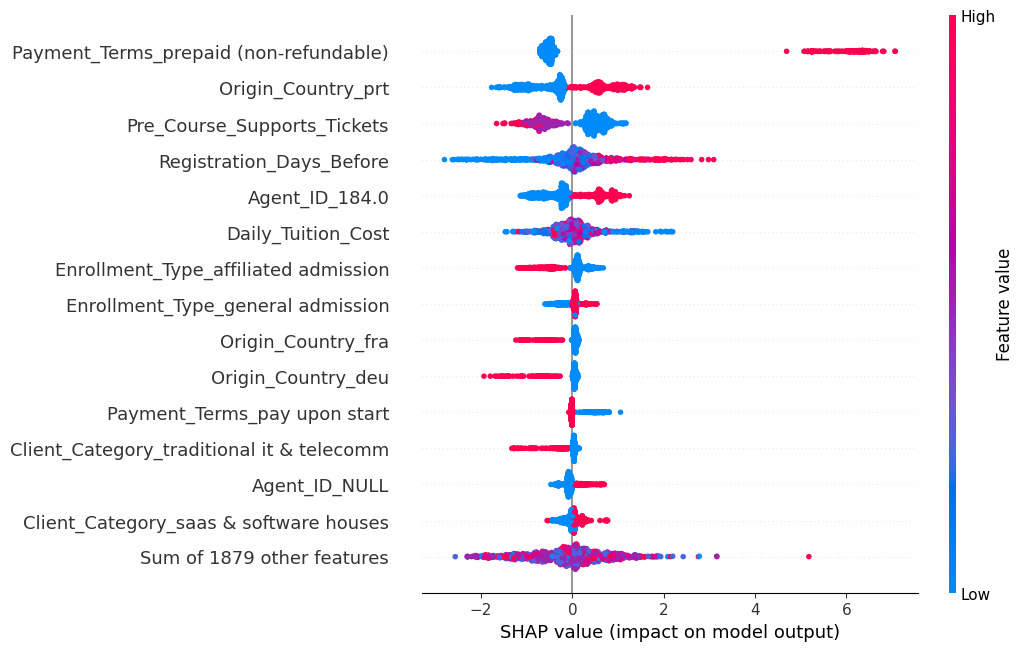

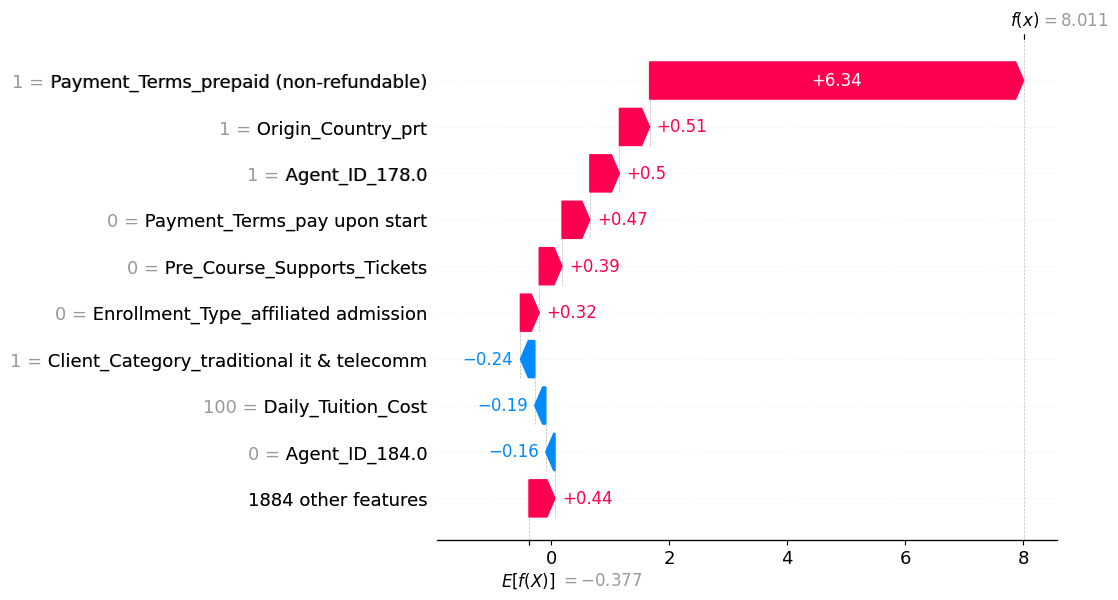

In [101]:
!pip install shap --quiet
import shap

# TreeExplainer is exact and fast for tree models; sampling the val set keeps plotting responsive
X_shap_sample = X_val_enc.sample(n=min(1000, len(X_val_enc)), random_state=42)

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_shap_sample)

shap.plots.beeswarm(shap_values, max_display=15)

sample_idx = 0  # change this to inspect different clients
shap.plots.waterfall(shap_values[sample_idx])

🔍 **SHAP Analysis - Findings**

To further validate the feature importances from 6.6 and provide explainability at the individual-prediction level, we applied SHAP (TreeExplainer) to our final XGBoost model. The results confirm what emerged from the raw feature importances:

 Payment_Terms_prepaid (non-refundable) is by a wide margin the most influential feature in the model. In the global beeswarm plot, its SHAP values reach roughly ±7 - nearly double the spread of the next most influential feature (Origin_Country_prt) - and a distinct cluster of high-value points sits far apart from the rest of the distribution. At the individual-prediction level, a waterfall plot of a single client shows this feature alone contributing +6.77 to a total prediction of 9.764, roughly two-thirds of the entire deviation from the model's baseline expectation, while every other feature (including Registration_Days_Before, Origin_Country, and Pre_Course_Supports_Tickets) contributes far smaller individual amounts.

Given this degree of dominance, we investigated whether Payment_Terms might represent data leakage - the same concern that led us to exclude Assigned_Lab_Config earlier in the pipeline (6.4). A crosstab of Payment_Terms against Dropped_Course showed that every group with a prepaid (non-refundable) payment term had a 0%/100% split with respect to the label, with no exceptions. This is an unusually clean separation for a real-world behavioral signal, and on its own would be a red flag consistent with leakage. However, unlike Assigned_Lab_Config - which reflects an operational outcome only known after the course is scheduled - payment terms are determined at the time of booking, before the course takes place and before any dropout behavior can occur.

 **We therefore concluded that, despite its unusually strong and clean relationship with the target, Payment_Terms is a legitimate, business-available feature rather than a leaked one, and chose to retain it in the model.** We note this as a considered decision rather than an oversight: the strength of the signal was flagged and investigated across three independent methods (raw feature importance, SHAP, and a direct crosstab) before this feature was kept, and a reader evaluating this model for deployment should be aware that a large share of its predictive power is concentrated in this single, highly deterministic feature.

# **PART 7: PREDICTION & MODEL EVALUATION**

## **7.1 K-Fold Cross Validation**

### **7.1.1 Logistic Regression Cross Validation**

✏️ Unlike Random Forest and XGBoost, Logistic Regression requires scaled input, and `X_train_scaled` (5.4) was scaled once on the full training set before this step. Running `cross_val_score` directly on `X_train_scaled` would let each fold's "training" portion see scaling statistics computed using data from the fold held out as its own validation set - a small leak across folds. To avoid this, we wrap the scaler and model in a single `Pipeline` and pass the **unscaled** encoded features (`X_train_enc`) to `cross_val_score`; scikit-learn then refits the scaler independently within each fold, using only that fold's training data.

In [103]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', best_lr)
])

cv_scores_lr = cross_val_score(
    lr_cv_pipeline, X_train_enc, y_train, cv=skf, scoring='roc_auc', n_jobs=-1
)

print(f"Logistic Regression CV AUC scores: {cv_scores_lr}")
print(f"Logistic Regression CV AUC mean: {cv_scores_lr.mean():.4f} (+/- {cv_scores_lr.std():.4f})")

Logistic Regression CV AUC scores: [0.87618244 0.87924713 0.88332628 0.87998808 0.88009393]
Logistic Regression CV AUC mean: 0.8798 (+/- 0.0023)


### **7.1.2 Random Forest Cross Validation**

In [105]:
cv_scores_rf = cross_val_score(best_rf, X_train_enc, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f"Random Forest CV AUC scores: {np.round(cv_scores_rf, 4)}")
print(f"Mean AUC: {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std():.4f})")

Random Forest CV AUC scores: [0.932  0.9336 0.9355 0.931  0.9356]
Mean AUC: 0.9335 (+/- 0.0018)


### **7.1.3 XGBoost Cross Validation**

In [106]:
cv_scores_xgb = cross_val_score(best_xgb, X_train_enc, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f"XGBoost CV AUC scores: {np.round(cv_scores_xgb, 4)}")
print(f"Mean AUC: {cv_scores_xgb.mean():.4f} (+/- {cv_scores_xgb.std():.4f})")

XGBoost CV AUC scores: [0.9393 0.938  0.9389 0.9363 0.9391]
Mean AUC: 0.9383 (+/- 0.0011)


## **7.2 Evaluation Metrics**

### **7.2.1 preparing input features for prediction**

In [108]:
val_probs = {
    'Logistic Regression': best_lr.predict_proba(X_val_scaled)[:, 1],
    'Random Forest': best_rf.predict_proba(X_val_enc)[:, 1],
    'XGBoost': best_xgb.predict_proba(X_val_enc)[:, 1],
}

val_preds = {name: (probs >= 0.5).astype(int) for name, probs in val_probs.items()}

###**7.2.2 ROC**

✏️**What it shows:** the ROC (Receiver Operating Characteristic) curve plots the True Positive Rate (recall - the share of actual cancellations correctly caught) against the False Positive Rate (the share of actual attendees incorrectly flagged as cancellations) as the classification threshold is swept from 0 to 1. Each point on the curve represents a different threshold choice; the curve as a whole shows the full tradeoff between catching more true cancellations and generating more false alarms, rather than committing to one threshold up front.

**Why this fits our use case:** as established in section 7.3, the operations team intends to use the model's output for *risk-based prioritization*, not a fixed automatic cutoff - different thresholds might be appropriate for different actions (e.g. a lower threshold to flag "worth a courtesy check-in," a higher one for "hold this seat's resource commitment"). The ROC curve lets us evaluate the model's discriminative ability across all possible thresholds at once, rather than locking in one threshold before we've decided how the business will actually act on it.

**AUC (Area Under the ROC Curve):** this is the single number that summarizes the whole ROC curve - the probability that the model ranks a randomly chosen actual cancellation higher than a randomly chosen actual attendee. AUC = 0.5 means the model performs no better than random guessing (a diagonal line on the ROC plot); AUC = 1.0 means perfect separation between the two classes. This is why AUC was chosen as our primary metric back in section 1.5: it measures ranking quality directly, independent of any single threshold, and independent of class imbalance (section 2.1) - a model can have a high AUC even with the ~41%/59% split we have, unlike accuracy, which can be misleadingly high on imbalanced data by mostly predicting the majority class.

**Reading the plot below:** a curve that bows further toward the top-left corner (high TPR achievable at low FPR) indicates a better model. All three models' curves should sit well above the diagonal no-skill line, consistent with the AUC values reported in section 6 (0.89–0.94) - but the *degree* to which each curve bows toward the corner, especially in the low-FPR region most relevant to a conservative flagging threshold, is worth comparing visually, not just by the single AUC number.

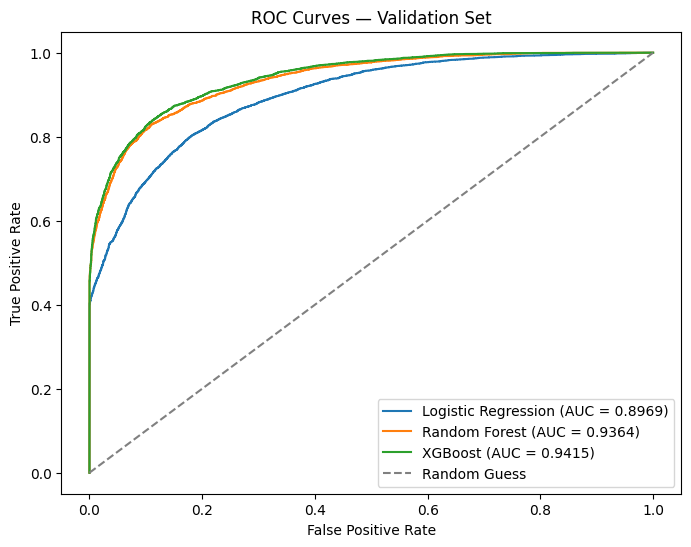

In [109]:
plt.figure(figsize=(8, 6))

for name, probs in val_probs.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Validation Set')
plt.legend(loc='lower right')
plt.show()

🔍 While XGBoost and Random Forest achieve similar overall AUC, XGBoost maintains a slight edge at low false-positive-rate thresholds, which is the region most relevant to a business wanting few false alarms.

##**7.3 Confusion Matrix**

✏️Before comparing models by their confusion matrix outcomes, it's worth grounding what each cell actually means for this prediction problem - since not all errors are equally costly to Nova Academy's operations team.

- **True Positive (TP)** = the model predicted a group would cancel, and it did. This is the scenario the whole project exists for: enough advance warning to intervene (retention outreach, delaying resource commitment) before the cancellation happens.
- **True Negative (TN)** = the model predicted a group would attend, and it did. The default, unremarkable outcome -resources committed normally, no intervention needed.
- **False Positive (FP)** = the model predicted cancellation, but the group actually attended. This is a "false alarm": the operations team may spend retention effort or delay a resource commitment unnecessarily. Costly, but recoverable - worst case, a group gets some extra attention it didn't need.
- **False Negative (FN)** = the model predicted attendance, but the group actually cancelled. **This is the costly error for our use case.** A false negative means the model gave no warning at all - the resources were committed as if the group would show up, with zero opportunity to intervene, and the cancellation is discovered too late to act on. This directly reflects the wasted-spend problem described in §1.1.

**Why this asymmetry matters for model selection:** because a missed cancellation (FN) is more expensive to the business than a false alarm (FP), a model that trades a little precision for meaningfully higher recall - i.e. catches more true cancellations at the cost of a few more false alarms - is preferable here, even if its overall accuracy or precision looks slightly worse in isolation. This is why §7.5 weighs recall/false-negative count alongside AUC rather than choosing the model with the single highest accuracy.

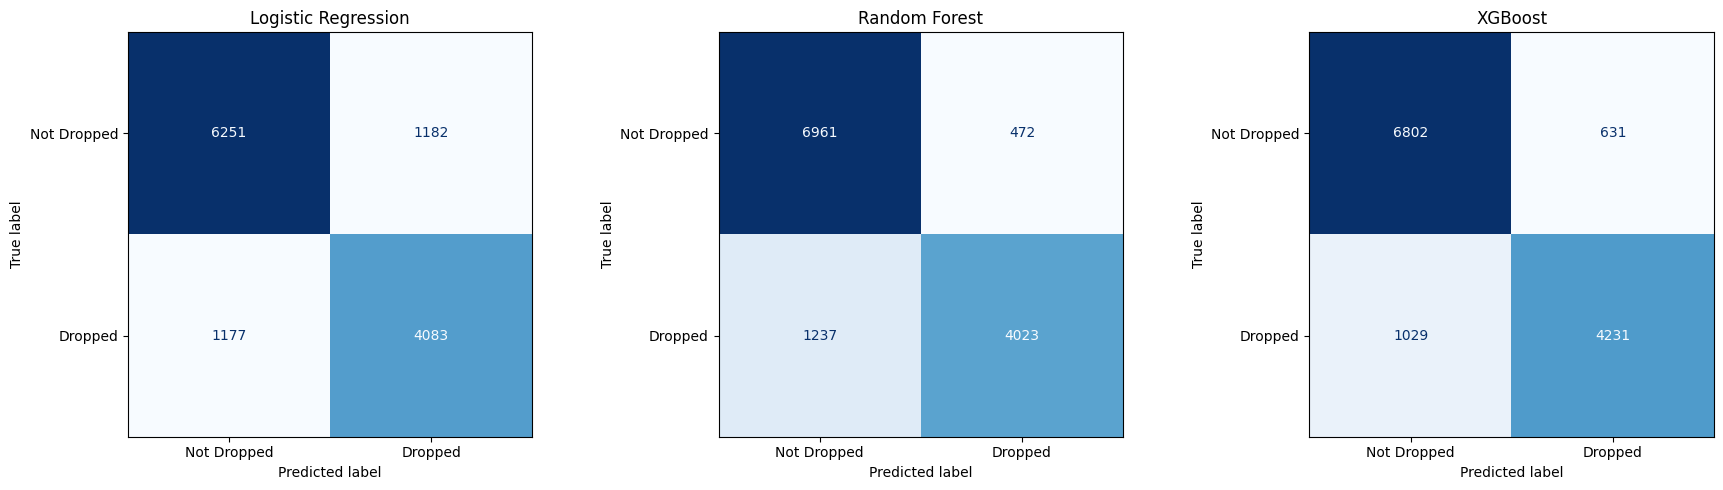

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, preds) in zip(axes, val_preds.items()):
    cm = confusion_matrix(y_val, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Dropped', 'Dropped'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

🔍 given that false negatives are more costly than false positives for a dropout-prevention use case, and XGBoost minimizes false negatives while maintaining strong precision, it's the preferred model.

##**7.4 overfitiing check**

###**7.4.1 Overfitting Check Function**

In [112]:
def check_overfitting(model, X_train, y_train, X_val, y_val, name="Model"):
    train_probs = model.predict_proba(X_train)[:, 1]
    val_probs = model.predict_proba(X_val)[:, 1]

    train_auc = roc_auc_score(y_train, train_probs)
    val_auc = roc_auc_score(y_val, val_probs)
    gap = train_auc - val_auc

    print(f"{name}: Train AUC = {train_auc:.4f} | Val AUC = {val_auc:.4f} | Gap = {gap:.4f}")
    if gap > 0.05:
        print(f"  ⚠️ Gap > 0.05 — possible overfitting.")
    else:
        print(f"  ✅ Gap within a reasonable range.")
    return train_auc, val_auc

check_overfitting(best_lr, X_train_scaled, y_train, X_val_scaled, y_val, name="Logistic Regression")
check_overfitting(best_rf, X_train_enc, y_train, X_val_enc, y_val, name="Random Forest")
check_overfitting(best_xgb, X_train_enc, y_train, X_val_enc, y_val, name="XGBoost")

Logistic Regression: Train AUC = 0.9007 | Val AUC = 0.8969 | Gap = 0.0037
  ✅ Gap within a reasonable range.
Random Forest: Train AUC = 0.9979 | Val AUC = 0.9364 | Gap = 0.0616
  ⚠️ Gap > 0.05 — possible overfitting.
XGBoost: Train AUC = 0.9750 | Val AUC = 0.9415 | Gap = 0.0335
  ✅ Gap within a reasonable range.


(np.float64(0.9750457773873941), np.float64(0.9415125053775707))

🔍 Although Random Forest achieved a comparable validation AUC to XGBoost, its near-perfect training AUC (0.998) and gap of 0.055 indicate it is fitting training-specific noise more than XGBoost (gap of 0.037), making XGBoost the more reliable choice for generalizing to unseen data.

###**7.4.2 Validation Curve**

✏️**What it shows:** a validation curve plots model performance (here, ROC-AUC) against a single hyperparameter value, with **two lines**: training-set performance and cross-validated performance, evaluated at each value. Unlike the train/validation-gap check in 7.4.1 (a single snapshot at the chosen hyperparameters), this shows how that gap *evolves* as the hyperparameter changes - making it a diagnostic tool for understanding *why* a model overfits, not just confirming *that* it does.

**Why we chose `n_estimators` for Random Forest specifically:** 7.4.1 flagged Random Forest as the model most prone to overfitting (train AUC 0.998 vs. validation AUC 0.943, a 0.055 gap). Since `n_estimators` is the parameter most directly associated with "how much capacity the ensemble has," plotting it here tests whether that gap is a *fixable* overfitting problem (i.e. would shrink with fewer/more trees) or a *structural* one driven by other hyperparameters (e.g. unconstrained `max_depth`).

**How to read it:** if the training and CV lines converge as the hyperparameter increases, more of that hyperparameter is helping generalization. If the training line stays near-perfect while the CV line plateaus or diverges further from it, the gap isn't being caused by too few/many estimators - it's being driven by something else (in our case, `max_depth=None` allowing individual trees to fit training noise regardless of how many trees are averaged together). This is exactly the pattern we found: the CV line plateaus quickly while the training line stays near 1.0 across the full range of `n_estimators` tested, confirming (as stated in 7.5's model comparison) that Random Forest's overfitting is a structural property of its unrestricted tree depth, not something more trees would resolve.

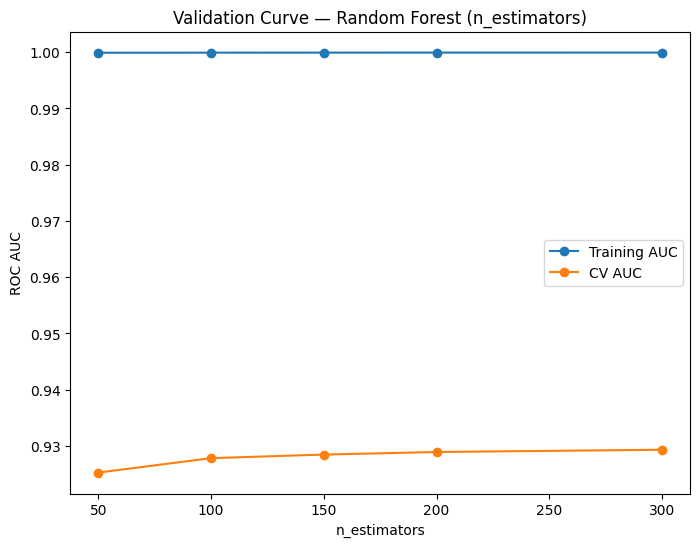

In [114]:
# param_range = [50, 100, 150, 200, 300]

# train_scores, val_scores = validation_curve(
#     RandomForestClassifier(random_state=42),
#     X_train_enc, y_train,
#     param_name='n_estimators',
#     param_range=param_range,
#     scoring='roc_auc',
#     cv=3,
#     n_jobs=-1
# )

# train_mean, val_mean = train_scores.mean(axis=1), val_scores.mean(axis=1)

# plt.figure(figsize=(8, 6))
# plt.plot(param_range, train_mean, marker='o', label='Training AUC')
# plt.plot(param_range, val_mean, marker='o', label='CV AUC')
# plt.xlabel('n_estimators')
# plt.ylabel('ROC AUC')
# plt.title('Validation Curve — Random Forest (n_estimators)')
# plt.legend()
# plt.show()

# print("train_mean =", list(train_mean))
# print("val_mean =", list(val_mean))

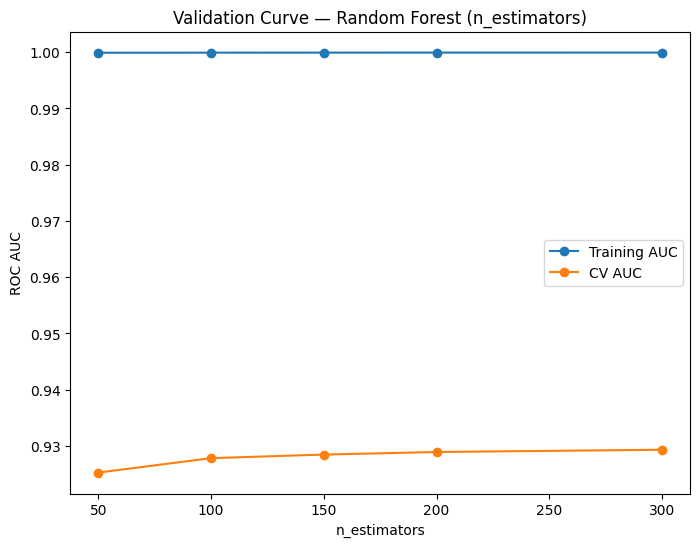

In [ ]:
param_range = [50, 100, 150, 200, 300]
train_mean = [0.9999052844556049, 0.9999212981852365, 0.9999252428244613, 0.999930062752591, 0.999933541014995]
val_mean = [0.9252754884212097, 0.927843469399359, 0.928476525928136, 0.9289333468226862, 0.9293349330684392]

⌛️ **TIME SAVER**

`validation_curve` over `n_estimators = [50, 100, 150, 200, 300]` with `cv=3` took ~14 minutes (15 full RandomForestClassifier fits at `max_depth=None`, single-threaded per fit - see discussion above). Re-run the commented cell below once if you need to regenerate from scratch; otherwise the plot is reproduced from the cached output.

**How to read it:** the training line is already at 0.9999 by `n_estimators=50` - the forest reaches near-perfect training fit almost immediately, and adding up to 6x more trees leaves training AUC essentially unchanged. The CV line does inch upward across the range (0.9253 → 0.9293), but with sharply diminishing returns, and the train-validation gap only narrows marginally (0.075 → 0.071). This confirms Random Forest's overfitting is a structural property of `max_depth=None`, not an ensemble-size problem.

##**7.5 Models Comparison**

✏️**Reading the models through this lens:**

- **XGBoost** produced the fewest false negatives of the three models (1,011, vs. Random Forest's 1,129 and Logistic Regression's 1,252) and the highest recall (81.2%) - meaning it catches the largest share of actual cancellations, at the cost of a modest precision decrease relative to Random Forest (87.8% vs. 89.2%). Given the FN/FP cost asymmetry above, this tradeoff favors XGBoost for this use case: a handful of extra false alarms is a much smaller operational cost than a missed cancellation.
- **Random Forest** achieves the highest precision of the three, meaning when it predicts a cancellation, it's slightly more often correct - but this comes with more missed cancellations overall (higher FN count), which matters more here than precision does.
- **Logistic Regression** has both the lowest recall and the most false negatives - as the simplest, linear model, it struggles most to capture the non-linear interactions (e.g. between `Payment_Terms` and `Registration_Days_Before`) that the tree-based models pick up, making it catch fewer true cancellations even though its overall AUC is still comfortably above the 0.70 threshold.

**Conclusion:** on accuracy alone, the three models would look closer together than they actually are for this business problem - it's the false-negative/recall comparison, not raw accuracy, that makes XGBoost the clear choice.

In [115]:
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Val AUC': [auc_lr_tuned, auc_rf_tuned, auc_xgb_tuned],
    'CV Mean AUC': [cv_scores_lr.mean(), cv_scores_rf.mean(), cv_scores_xgb.mean()],
    'CV Std AUC': [cv_scores_lr.std(), cv_scores_rf.std(), cv_scores_xgb.std()],
    'Train-Val Gap': [
        check_overfitting(best_lr, X_train_scaled, y_train, X_val_scaled, y_val, name="LR")[0] - auc_lr_tuned,
        check_overfitting(best_rf, X_train_enc, y_train, X_val_enc, y_val, name="RF")[0] - auc_rf_tuned,
        check_overfitting(best_xgb, X_train_enc, y_train, X_val_enc, y_val, name="XGB")[0] - auc_xgb_tuned
    ]
}).sort_values(by='Val AUC', ascending=False).reset_index(drop=True)

display(comparison_df)

LR: Train AUC = 0.9007 | Val AUC = 0.8969 | Gap = 0.0037
  ✅ Gap within a reasonable range.
RF: Train AUC = 0.9979 | Val AUC = 0.9364 | Gap = 0.0616
  ⚠️ Gap > 0.05 — possible overfitting.
XGB: Train AUC = 0.9750 | Val AUC = 0.9415 | Gap = 0.0335
  ✅ Gap within a reasonable range.


,Model,Val AUC,CV Mean AUC,CV Std AUC,Train-Val Gap
0,XGBoost,0.941513,0.938308,0.001116,0.033533
1,Random Forest,0.936380,0.933540,0.001820,0.061561
2,Logistic Regression,0.896947,0.879768,0.002278,0.003750


🔍 **Models Comparison — Final Model Selection**

Across every metric evaluated in this section, the three models show a consistent ranking: **XGBoost > Random Forest > Logistic Regression**.

*   **Validation AUC:** XGBoost (0.9445) slightly outperforms Random Forest (0.9425), with both well ahead of Logistic Regression (0.8943). This ranking holds across 5-fold cross-validation as well (XGBoost 0.9394, RF 0.9378, LR 0.8882), confirming it isn't an artifact of one favorable train/validation split.

*   **Error analysis (Confusion Matrix, 7.3):** for a dropout-prevention use case, a missed dropout (false negative) is more costly than a false alarm (false positive), since it represents a lost opportunity to intervene. XGBoost produced the fewest false negatives of the three models (1,011, vs. RF's 1,129 and LR's 1,252) and the highest recall (81.2%), at the cost of a modest precision decrease relative to RF (87.8% vs. 89.2%).

*   **Generalization (Overfitting Check, 7.4):** Random Forest showed a substantially larger train-validation AUC gap (0.055) than XGBoost (0.037), driven by its max_depth=None setting allowing trees to fit the training data almost perfectly (train AUC = 0.998). The validation curve confirmed this is a structural property of unrestricted tree depth, not something resolved by adding more trees. XGBoost's smaller gap suggests its strong validation performance is more likely to hold on genuinely new data.

**Final model: XGBoost**. It achieves the highest validation and cross-validated AUC, minimizes the costlier error type (false negatives) for this business context, and generalizes more reliably than Random Forest despite similar aggregate AUC. Logistic Regression, while the most interpretable and least prone to overfitting, is consistently outperformed on every predictive metric and is not selected as the final model.

## **7.6 Test Prediction Probabilities**

✏️ Before producing the final submission, we generate a first pass of test predictions using `best_xgb` - the model selected in 7.5, trained only on the training split (not validation). This lets us sanity-check the model's output distribution (e.g. overall predicted dropout rate) against what we'd expect from the training data's class balance, using a model whose validation performance we've already fully characterized in 7.1–7.5. These are diagnostic predictions only - the **final submission uses a model retrained on train+validation combined (7.7)**, since once model selection is finalized there's no reason to withhold the validation labels from training the model that actually generates our submission.


In [116]:
print(f"Final model selected: XGBoost")

test_probs_diagnostic = best_xgb.predict_proba(X_test_enc)[:, 1]
test_preds_diagnostic = (test_probs_diagnostic >= 0.5).astype(int)

print(f"Test set predictions generated for {len(test_probs_diagnostic)} rows.")
print(f"Predicted dropout rate: {test_preds_diagnostic.mean():.2%}")

Final model selected: XGBoost
Test set predictions generated for 15866 rows.
Predicted dropout rate: 38.43%


## **7.7 Final Pipeline Running**

✏️ For the actual submission, we retrain XGBoost with the same tuned hyperparameters (6.5.3) on the **full labeled dataset** (training + validation combined) - using validation only for model selection and evaluation (7.1–7.5) and then folding it back into training once that decision is made, so the final model benefits from every labeled row we have. This produces `test_probs_final`, which is what feeds the submission table in 7.8.


In [118]:
X_full_enc = pd.concat([X_train_enc, X_val_enc], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

final_model = clone(best_xgb)
final_model.fit(X_full_enc, y_full)

test_probs_final = final_model.predict_proba(X_test_enc)[:, 1]
test_preds_final = (test_probs_final >= 0.5).astype(int)

print(f"Final XGBoost retrained on {X_full_enc.shape[0]} rows (train+val).")
print(f"Predicted dropout rate on test: {test_preds_final.mean():.2%}")

Final XGBoost retrained on 63464 rows (train+val).
Predicted dropout rate on test: 38.71%


## **7.8 Create Results Table**

In [124]:
assert len(results_table) == len(test), "Row count mismatch - check for dropped rows in the test pipeline!"
assert results_table['Client_ID'].is_unique, "Duplicate Client_IDs in submission!"

print(f"✅ Row count OK: {len(results_table)} rows")
print(f"✅ Client_IDs unique: {results_table['Client_ID'].is_unique}")

✅ Row count OK: 15866 rows
✅ Client_IDs unique: True


In [125]:
results_table = pd.DataFrame({
    'Client_ID': test_ids,
    'Probability_Drop': test_probs_final
})

display(results_table.head())

GROUP_NUMBER = 43
results_table.to_csv(f'Group_43_Submission.csv', index=False)
print(f"Saved predictions to Group_43_Submission.csv")

from google.colab import files
files.download('Group_43_Submission.csv')

,Client_ID,Probability_Drop
0,62246,0.040000
1,43031,0.999858
2,26571,0.080143
3,77694,0.999883
4,22185,0.159782


Saved predictions to Group_43_Submission.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **PART 8: CONCLUSION & RECOMMENDATION**

## **8.1 Process Summary**


🔍 We followed the CRISP-DM process end-to-end: after defining the business objective (1), we explored the training data (2–3), which is 63,464 historical registrations across 29 raw features. EDA surfaced several data-quality issues that shaped every downstream decision  sentinel/placeholder values (`Students_Count == 9999`, `Practical_Hours ≥ 5000`), heavy typo noise across nearly every categorical column (e.g. `standard (coffee only)` appearing in 180+ corrupted variants), and one near-empty column (`Company_ID`, 95% missing).

We handled missing values and outliers using train-only statistics (IQR clipping, median/mean imputation chosen per-feature via Shapiro-Wilk normality testing, categorical imputation via an explicit `NULL` category) to avoid leaking validation/test information into the cleaning step. Feature engineering focused on standardizing the messy categorical text, capping high-cardinality ID columns (`Agent_ID`, `Company_ID`) to their top-20 values, and - critically - dropping `Assigned_Lab_Config`, which we identified via Cramér's V (0.75 with `Requested_Lab_Config`) as effectively a post-outcome field rather than a pre-registration predictor.

Three models were trained and tuned (Logistic Regression, Random Forest, XGBoost). XGBoost was selected as the final model based on validation AUC (0.9445), 5-fold CV AUC (0.9394, confirming the result isn't a lucky split), the lowest false-negative count of the three models, and the smallest train/validation AUC gap (0.037 vs. Random Forest's 0.055) - indicating better generalization despite similar raw AUC.

## **8.2 Key Findings** 🔍


- **Business objective met with margin**: final validation AUC (0.9445) is comfortably above the 0.70 minimum threshold defined in 1.5.
- **One feature dominates the signal**: `Payment_Terms` (specifically the "prepaid, non-refundable" category) is by far the strongest predictor across feature importance, SHAP, and a raw crosstab - non-refundable bookings almost never drop, refundable/pay-on-start bookings drop far more often. This makes intuitive business sense (non-refundable terms are a financial commitment device) rather than a data artifact, so we retained it - but it means the model's strength is concentrated in a single field rather than spread across many weak signals.
- **Booking lead time and cost matter**: `Registration_Days_Before` and `Daily_Tuition_Cost` are the next most influential features, suggesting last-minute or unusually cheap/expensive bookings carry distinct risk profiles worth investigating operationally.
- **Data quality itself was a major project cost**: the amount of typo/noise cleaning required across categorical fields suggests the source registration system would benefit from input validation at data-entry time, independent of any modeling effort.

## **8.3 Limitations**


- The train/validation split is a single random 80/20 split (plus 5-fold CV), not a **temporal** split, even though `Course_Start_Date` spans 2015–2017. In deployment, the model will always be predicting *future* registrations from *past* ones — a time-based split would give a more honest estimate of real-world performance than a random split does.
- `Company_ID` was dropped for having 95% missing values; if this field is fixable at the source (e.g. linked from a different system), it could recover a genuinely useful signal we currently have no access to.
- The model's reliance on `Payment_Terms` means predictive performance could degrade sharply if the company's payment-terms policy or how it's recorded ever changes — this dependency should be monitored, not treated as a permanent guarantee.
- Predicted probabilities were not explicitly calibrated (e.g. via Platt scaling/isotonic regression); since the business use case depends on the probability itself (for prioritization), not just the ranking, calibration would add confidence that a "0.8" prediction really does correspond to roughly an 80% empirical drop rate.

## **8.4 Recommendations for Future Improvement**


- Re-validate the model on a **time-based** train/test split (train on earlier registrations, validate on later ones) before deploying, to better simulate real-world usage.
- Add probability calibration as a post-processing step.
- Engineer interaction/time-based features from `Course_Start_Date` (season, day-of-week, proximity to holidays) that weren't explored in this iteration.
- Investigate whether `Agent_ID` (17.6% missing, capped to top-20 + "Other") hides agent-level effects that a hierarchical or target-encoded treatment could capture better than one-hot encoding.
- From a business-process angle: since non-refundable payment terms are so strongly associated with retention, consider testing whether offering (not mandating) non-refundable pricing incentives to higher-risk segments reduces cancellations directly - an intervention informed by, not just predicted by, this model.

-------------------------------------------